In [1]:
# ============================================================
# RICE DISEASE CLASSIFICATION PROJECT
# CELL 1: ENVIRONMENT AND DATASET INSPECTION
# ============================================================

import os
import sys
import platform
import torch

print("=" * 70)
print("RICE DISEASE CLASSIFICATION PROJECT")
print("ENVIRONMENT INITIALIZATION")
print("=" * 70)

# 1. Python and PyTorch information
print("\n[1] SOFTWARE ENVIRONMENT")
print("-" * 50)
print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# 2. GPU information
print("\n[2] GPU INFORMATION")
print("-" * 50)

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)

        print(f"\nGPU {i}: {props.name}")
        print(
            "Total GPU memory:",
            f"{props.total_memory / (1024**3):.2f} GB"
        )

    print(
        "\nCurrent GPU allocated memory:",
        f"{torch.cuda.memory_allocated() / (1024**2):.2f} MB"
    )
else:
    print("No CUDA GPU detected. Check Kaggle accelerator settings.")

# 3. Inspect Kaggle input datasets
print("\n[3] AVAILABLE KAGGLE INPUTS")
print("-" * 50)

INPUT_DIR = "/kaggle/input"

if os.path.isdir(INPUT_DIR):
    input_items = sorted(os.listdir(INPUT_DIR))

    if not input_items:
        print("No datasets found in /kaggle/input.")
    else:
        for item in input_items:
            item_path = os.path.join(INPUT_DIR, item)

            if os.path.isdir(item_path):
                print(f"\nDataset/folder: {item}")

                try:
                    children = sorted(os.listdir(item_path))
                    for child in children[:15]:
                        child_path = os.path.join(item_path, child)

                        if os.path.isdir(child_path):
                            print(f"  [DIR]  {child}")
                        else:
                            print(f"  [FILE] {child}")

                    if len(children) > 15:
                        print(
                            f"  ... and {len(children) - 15} more items"
                        )

                except PermissionError:
                    print("  Cannot access this folder.")
            else:
                print("File:", item)
else:
    print("Kaggle input directory is unavailable.")

# 4. Inspect available disk space
print("\n[4] WORKING DIRECTORY")
print("-" * 50)

WORK_DIR = "/kaggle/working"
os.makedirs(WORK_DIR, exist_ok=True)

disk = os.statvfs(WORK_DIR)
free_gb = disk.f_bavail * disk.f_frsize / (1024**3)

print("Working directory:", WORK_DIR)
print(f"Available disk space: {free_gb:.2f} GB")

print("\n" + "=" * 70)
print("CELL 1 COMPLETED")
print("No training or dataset modifications performed.")
print("=" * 70)

RICE DISEASE CLASSIFICATION PROJECT
ENVIRONMENT INITIALIZATION

[1] SOFTWARE ENVIRONMENT
--------------------------------------------------
Python version: 3.13.15
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch version: 2.11.0+cu128
CUDA available: True

[2] GPU INFORMATION
--------------------------------------------------

GPU 0: Tesla T4
Total GPU memory: 14.56 GB

GPU 1: Tesla T4
Total GPU memory: 14.56 GB

Current GPU allocated memory: 0.00 MB

[3] AVAILABLE KAGGLE INPUTS
--------------------------------------------------

Dataset/folder: datasets
  [DIR]  sirichandanakota

[4] WORKING DIRECTORY
--------------------------------------------------
Working directory: /kaggle/working
Available disk space: 19.50 GB

CELL 1 COMPLETED
No training or dataset modifications performed.


In [2]:
# ============================================================
# CELL 2: LOCATE AND INSPECT THE RICE DISEASE DATASET
# ============================================================

import os

INPUT_DIR = "/kaggle/input"

print("=" * 70)
print("RICE DATASET DISCOVERY")
print("=" * 70)

# Find the dataset root
for current_root, dirs, files in os.walk(INPUT_DIR):
    depth = current_root.replace(INPUT_DIR, "").count(os.sep)

    # Limit the initial inspection depth
    if depth > 4:
        dirs[:] = []
        continue

    dirs[:] = sorted(dirs)

    print(f"\nDirectory: {current_root}")

    for directory in dirs[:10]:
        print(f"  [DIR]  {directory}")

    for filename in files[:10]:
        print(f"  [FILE] {filename}")

    if len(dirs) > 10:
        print(f"  ... and {len(dirs) - 10} more directories")

    if len(files) > 10:
        print(f"  ... and {len(files) - 10} more files")

print("\n" + "=" * 70)
print("DATASET DISCOVERY COMPLETED")
print("=" * 70)

RICE DATASET DISCOVERY

Directory: /kaggle/input
  [DIR]  datasets

Directory: /kaggle/input/datasets
  [DIR]  sirichandanakota

Directory: /kaggle/input/datasets/sirichandanakota
  [DIR]  rice-crop-dataset
  [DIR]  rice-disease-model-backup

Directory: /kaggle/input/datasets/sirichandanakota/rice-crop-dataset
  [DIR]  Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)

Directory: /kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)
  [DIR]  Bakanae
  [DIR]  Brown Spot
  [DIR]  False Smut
  [DIR]  Healthy
  [DIR]  Leaf Blast
  [DIR]  Leaf Scald
  [DIR]  Narrow Brown Spot
  [DIR]  Neck Blast
  [DIR]  Sheath Blight
  [DIR]  Stem Rot

Directory: /kaggle/input/datasets/sirichandanakota/rice-disease-model-backup
  [DIR]  checkpoints
  [DIR]  results

Directory: /kaggle/input/datasets/sirichandanakota/rice-disease-model-backup/checkpoints
  [FILE] best_convnext_tiny.pth
  [FI

In [3]:
# ============================================================
# CELL 3: INSPECT RECOVERED MODEL CHECKPOINTS
# ============================================================

import os
import torch

BACKUP_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup"
)

CHECKPOINT_DIR = os.path.join(BACKUP_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BACKUP_DIR, "results")

print("=" * 70)
print("RECOVERED MODEL CHECKPOINTS")
print("=" * 70)

for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    path = os.path.join(CHECKPOINT_DIR, filename)

    if not os.path.isfile(path):
        continue

    print(f"\nFile: {filename}")
    print(f"Size: {os.path.getsize(path) / (1024**2):.2f} MB")

    if filename.endswith((".pth", ".pt")):
        try:
            checkpoint = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            if isinstance(checkpoint, dict):
                print("Checkpoint keys:", list(checkpoint.keys()))

                for key in [
                    "model_name",
                    "epoch",
                    "best_epoch",
                    "best_val_macro_f1",
                    "best_val_f1",
                    "val_accuracy",
                    "best_val_accuracy"
                ]:
                    if key in checkpoint:
                        print(f"{key}: {checkpoint[key]}")

                state = checkpoint.get(
                    "model_state_dict",
                    checkpoint.get("state_dict")
                )

                if isinstance(state, dict):
                    print("Model state dictionary: available")
                    print("Number of parameter entries:", len(state))
                else:
                    print("Model state dictionary: not found at standard keys")

            else:
                print("Checkpoint object type:", type(checkpoint).__name__)

        except Exception as exc:
            print("Could not inspect checkpoint:", repr(exc))

print("\n" + "=" * 70)
print("TRAINING HISTORY FILES")
print("=" * 70)

if os.path.isdir(RESULTS_DIR):
    for filename in os.listdir(RESULTS_DIR):
        print(filename)

print("\nCheckpoint inspection completed.")

RECOVERED MODEL CHECKPOINTS

File: best_convnext_tiny.pth
Size: 106.22 MB
Checkpoint keys: ['model_name', 'epoch', 'model_state_dict', 'validation_accuracy', 'validation_macro_f1', 'class_names']
model_name: ConvNeXt-Tiny
epoch: 5
Model state dictionary: available
Number of parameter entries: 182

File: best_efficientnetv2-s.pth
Size: 77.88 MB
Checkpoint keys: ['model_name', 'epoch', 'model_state_dict', 'validation_accuracy', 'validation_macro_f1', 'class_names']
model_name: EfficientNetV2-S
epoch: 2
Model state dictionary: available
Number of parameter entries: 782

TRAINING HISTORY FILES
convnext_tiny_training_history.csv

Checkpoint inspection completed.


In [4]:
# ============================================================
# CELL 3A: VERIFY RECOVERED MODEL CHECKPOINTS
# ============================================================

import os
import torch

BACKUP_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup"
)

CHECKPOINT_DIR = os.path.join(BACKUP_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BACKUP_DIR, "results")

checkpoint_files = [
    "best_convnext_tiny.pth",
    "best_efficientnetv2-s.pth"
]

for filename in checkpoint_files:
    path = os.path.join(CHECKPOINT_DIR, filename)

    print("\n" + "=" * 70)
    print("CHECKPOINT:", filename)
    print("=" * 70)

    if not os.path.isfile(path):
        print("STATUS: FILE NOT FOUND")
        continue

    print(f"File size: {os.path.getsize(path) / (1024**2):.2f} MB")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Object type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("Top-level keys:", list(checkpoint.keys()))

            for key in [
                "model_name",
                "epoch",
                "best_epoch",
                "best_val_macro_f1",
                "best_val_f1",
                "val_accuracy",
                "best_val_accuracy",
                "class_names"
            ]:
                if key in checkpoint:
                    value = checkpoint[key]
                    print(f"{key}: {value}")

            state = checkpoint.get(
                "model_state_dict",
                checkpoint.get("state_dict")
            )

            if state is None and checkpoint:
                # Some checkpoints store weights directly.
                if all(torch.is_tensor(v) for v in checkpoint.values()):
                    state = checkpoint

            if isinstance(state, dict):
                print("Weights found: YES")
                print("Parameter entries:", len(state))

                for key in list(state.keys())[:5]:
                    tensor = state[key]
                    if torch.is_tensor(tensor):
                        print(f"  {key}: {tuple(tensor.shape)}")
            else:
                print("Weights found at recognized locations: NO")

    except Exception as exc:
        print("Inspection error:", repr(exc))

print("\nCheckpoint inspection completed.")


CHECKPOINT: best_convnext_tiny.pth
File size: 106.22 MB
Object type: dict
Top-level keys: ['model_name', 'epoch', 'model_state_dict', 'validation_accuracy', 'validation_macro_f1', 'class_names']
model_name: ConvNeXt-Tiny
epoch: 5
class_names: ['Bakanae', 'Brown Spot', 'False Smut', 'Healthy', 'Leaf Blast', 'Leaf Scald', 'Narrow Brown Spot', 'Neck Blast', 'Sheath Blight', 'Stem Rot']
Weights found: YES
Parameter entries: 182
  stem.0.weight: (96, 3, 4, 4)
  stem.0.bias: (96,)
  stem.1.weight: (96,)
  stem.1.bias: (96,)
  stages.0.blocks.0.gamma: (96,)

CHECKPOINT: best_efficientnetv2-s.pth
File size: 77.88 MB
Object type: dict
Top-level keys: ['model_name', 'epoch', 'model_state_dict', 'validation_accuracy', 'validation_macro_f1', 'class_names']
model_name: EfficientNetV2-S
epoch: 2
class_names: ['Bakanae', 'Brown Spot', 'False Smut', 'Healthy', 'Leaf Blast', 'Leaf Scald', 'Narrow Brown Spot', 'Neck Blast', 'Sheath Blight', 'Stem Rot']
Weights found: YES
Parameter entries: 782
  conv_s

In [ ]:


# ============================================================
# CELL 4: INSPECT DATASET AND RECOVERED TRAINING HISTORY
# ============================================================

import os
import csv
from collections import Counter

DATASET_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/"
    "Self-Collected Real-Field Dataset of Rice Fungal Diseases "
    "and Healthy Leaves(org)"
)

RESULTS_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup/results"
)

CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

print("=" * 70)
print("DATASET VERIFICATION")
print("=" * 70)

if not os.path.isdir(DATASET_DIR):
    print("ERROR: Dataset directory not found:")
    print(DATASET_DIR)
else:
    total_images = 0

    for class_name in CLASS_NAMES:
        class_dir = os.path.join(DATASET_DIR, class_name)

        if not os.path.isdir(class_dir):
            print(f"{class_name}: DIRECTORY NOT FOUND")
            continue

        count = sum(
            1
            for root, _, files in os.walk(class_dir)
            for filename in files
            if os.path.splitext(filename)[1].lower()
            in IMAGE_EXTENSIONS
        )

        total_images += count
        print(f"{class_name:22s}: {count:6d} images")

    print("-" * 70)
    print(f"{'TOTAL':22s}: {total_images:6d} images")

print("\n" + "=" * 70)
print("RECOVERED TRAINING HISTORY")
print("=" * 70)

if os.path.isdir(RESULTS_DIR):
    csv_files = [
        f for f in os.listdir(RESULTS_DIR)
        if f.lower().endswith(".csv")
    ]

    if not csv_files:
        print("No CSV training-history files found.")
    else:
        for filename in csv_files:
            path = os.path.join(RESULTS_DIR, filename)
            print(f"\nFile: {filename}")

            try:
                with open(path, "r", newline="") as file:
                    reader = csv.DictReader(file)
                    rows = list(reader)

                print("Columns:", reader.fieldnames)
                print("Recorded epochs:", len(rows))

                for row in rows[-3:]:
                    print(row)

            except Exception as exc:
                print("Could not read CSV:", repr(exc))
else:
    print("Results directory not found.")

print("\nDataset and history inspection completed.")

In [6]:
# ============================================================
# CELL 5: SEARCH FOR EXISTING SPLIT MANIFESTS
# ============================================================

import os

SEARCH_ROOTS = [
    "/kaggle/working",
    "/kaggle/input/datasets/sirichandanakota"
]

KEYWORDS = (
    "manifest",
    "split",
    "train",
    "validation",
    "val",
    "test",
    "rice_disease_project"
)

MATCHED_FILES = []

print("=" * 70)
print("SEARCHING FOR EXISTING PROJECT FILES")
print("=" * 70)

for search_root in SEARCH_ROOTS:
    print(f"\nSearching: {search_root}")

    if not os.path.isdir(search_root):
        print("Directory not found.")
        continue

    for root, dirs, files in os.walk(search_root):
        # Avoid descending into common cache directories.
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git",
                "__pycache__",
                ".cache",
                "node_modules"
            }
        ]

        for filename in files:
            lower_name = filename.lower()

            if (
                lower_name.endswith((".csv", ".json", ".txt", ".parquet"))
                and any(keyword in lower_name for keyword in KEYWORDS)
            ):
                path = os.path.join(root, filename)
                MATCHED_FILES.append(path)
                print(path)

print("\n" + "=" * 70)

if MATCHED_FILES:
    print(f"Found {len(MATCHED_FILES)} candidate file(s).")
else:
    print("No candidate split-manifest files found.")

print("Search completed.")

SEARCHING FOR EXISTING PROJECT FILES

Searching: /kaggle/working

Searching: /kaggle/input/datasets/sirichandanakota
/kaggle/input/datasets/sirichandanakota/rice-disease-model-backup/results/convnext_tiny_training_history.csv

Found 1 candidate file(s).
Search completed.


In [7]:
# ============================================================
# CELL 6: DETECT EXACT DUPLICATE FILES
# ============================================================

import os
import hashlib
from collections import defaultdict
from time import time

DATASET_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/"
    "Self-Collected Real-Field Dataset of Rice Fungal Diseases "
    "and Healthy Leaves(org)"
)

CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()

print("=" * 70)
print("EXACT DUPLICATE IMAGE CHECK")
print("=" * 70)

image_paths = []

for class_name in CLASS_NAMES:
    class_dir = os.path.join(DATASET_DIR, class_name)

    for root, _, filenames in os.walk(class_dir):
        for filename in filenames:
            if os.path.splitext(filename)[1].lower() in IMAGE_EXTENSIONS:
                image_paths.append(os.path.join(root, filename))

print(f"Images discovered: {len(image_paths)}")
print("Computing SHA-256 hashes; this may take a few minutes...")

start_time = time()
hash_to_paths = defaultdict(list)

for index, path in enumerate(image_paths, start=1):
    try:
        file_hash = sha256_file(path)
        hash_to_paths[file_hash].append(path)
    except Exception as exc:
        print(f"Could not read {path}: {exc}")

    if index % 2000 == 0:
        print(f"Processed {index}/{len(image_paths)} images")

duplicate_groups = [
    paths for paths in hash_to_paths.values()
    if len(paths) > 1
]

duplicate_files = sum(
    len(paths) - 1 for paths in duplicate_groups
)

cross_class_groups = []

for paths in duplicate_groups:
    classes = {
        os.path.basename(os.path.dirname(path))
        for path in paths
    }

    if len(classes) > 1:
        cross_class_groups.append(paths)

print("\n" + "=" * 70)
print("RESULTS")
print("=" * 70)
print(f"Files successfully hashed: {sum(map(len, hash_to_paths.values()))}")
print(f"Unique file hashes: {len(hash_to_paths)}")
print(f"Exact duplicate groups: {len(duplicate_groups)}")
print(f"Additional duplicate files: {duplicate_files}")
print(f"Duplicate groups spanning multiple classes: {len(cross_class_groups)}")
print(f"Elapsed time: {(time() - start_time) / 60:.2f} minutes")

if cross_class_groups:
    print("\nExamples of cross-class duplicate groups:")
    for paths in cross_class_groups[:5]:
        print("\nGroup:")
        for path in paths:
            print(" ", path)

print("\nNo files were changed or deleted.")

EXACT DUPLICATE IMAGE CHECK
Images discovered: 30662
Computing SHA-256 hashes; this may take a few minutes...
Processed 2000/30662 images
Processed 4000/30662 images
Processed 6000/30662 images
Processed 8000/30662 images
Processed 10000/30662 images
Processed 12000/30662 images
Processed 14000/30662 images
Processed 16000/30662 images
Processed 18000/30662 images
Processed 20000/30662 images
Processed 22000/30662 images
Processed 24000/30662 images
Processed 26000/30662 images
Processed 28000/30662 images
Processed 30000/30662 images

RESULTS
Files successfully hashed: 30662
Unique file hashes: 7955
Exact duplicate groups: 7651
Additional duplicate files: 22707
Duplicate groups spanning multiple classes: 0
Elapsed time: 17.27 minutes

No files were changed or deleted.


In [8]:
# ============================================================
# CELL 7: CREATE UNIQUE-IMAGE INVENTORY
# ============================================================

import os
import csv
import hashlib
from collections import defaultdict

DATASET_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/"
    "Self-Collected Real-Field Dataset of Rice Fungal Diseases "
    "and Healthy Leaves(org)"
)

OUTPUT_DIR = "/kaggle/working/rice_disease_project"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)

    return digest.hexdigest()

print("Collecting unique-image inventory...")

hash_to_records = defaultdict(list)

for class_name in CLASS_NAMES:
    class_dir = os.path.join(DATASET_DIR, class_name)

    for root, _, filenames in os.walk(class_dir):
        for filename in filenames:
            if os.path.splitext(filename)[1].lower() not in IMAGE_EXTENSIONS:
                continue

            path = os.path.join(root, filename)

            try:
                file_hash = sha256_file(path)

                hash_to_records[file_hash].append({
                    "path": path,
                    "class_name": class_name
                })

            except Exception as exc:
                print(f"Skipped unreadable file: {path} | {exc}")

# Verify that every exact duplicate group has one class label.
conflicting_groups = []

for file_hash, records in hash_to_records.items():
    labels = {record["class_name"] for record in records}

    if len(labels) > 1:
        conflicting_groups.append((file_hash, records))

if conflicting_groups:
    raise ValueError(
        f"Found {len(conflicting_groups)} exact-duplicate groups "
        "with conflicting labels. Resolve these before splitting."
    )

# Choose one representative per hash deterministically.
unique_records = []

for file_hash in sorted(hash_to_records):
    records = sorted(
        hash_to_records[file_hash],
        key=lambda record: record["path"]
    )

    representative = records[0]

    unique_records.append({
        "sha256": file_hash,
        "path": representative["path"],
        "class_name": representative["class_name"],
        "duplicate_count": len(records),
        "duplicate_paths": " || ".join(
            record["path"] for record in records
        )
    })

inventory_path = os.path.join(
    OUTPUT_DIR, "unique_image_inventory.csv"
)

with open(inventory_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "sha256",
            "path",
            "class_name",
            "duplicate_count",
            "duplicate_paths"
        ]
    )

    writer.writeheader()
    writer.writerows(unique_records)

print("\n" + "=" * 70)
print("UNIQUE-IMAGE INVENTORY SUMMARY")
print("=" * 70)

print(f"Original image files: {sum(len(v) for v in hash_to_records.values())}")
print(f"Unique images: {len(unique_records)}")
print(f"Exact duplicates removed from inventory: "
      f"{sum(len(v) - 1 for v in hash_to_records.values())}")
print(f"Inventory saved to: {inventory_path}")

print("\nUnique images per class:")

for class_name in CLASS_NAMES:
    count = sum(
        record["class_name"] == class_name
        for record in unique_records
    )
    print(f"{class_name:22s}: {count:5d}")

print("\nOriginal dataset remains unchanged.")


UNIQUE-IMAGE INVENTORY SUMMARY
Original image files: 30662
Unique images: 7955
Exact duplicates removed from inventory: 22707
Inventory saved to: /kaggle/working/rice_disease_project/unique_image_inventory.csv

Unique images per class:
Bakanae               :   350
Brown Spot            :   698
False Smut            :   176
Healthy               :  2296
Leaf Blast            :   702
Leaf Scald            :  1439
Narrow Brown Spot     :   726
Neck Blast            :   600
Sheath Blight         :   568
Stem Rot              :   400

Original dataset remains unchanged.


In [9]:
# ============================================================
# CELL 8: REBUILD INVENTORY AND CREATE STRATIFIED SPLIT
# ============================================================

import os
import hashlib
import pandas as pd

from collections import defaultdict
from sklearn.model_selection import train_test_split

DATASET_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/"
    "Self-Collected Real-Field Dataset of Rice Fungal Diseases "
    "and Healthy Leaves(org)"
)

PROJECT_DIR = "/kaggle/working/rice_disease_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

CLASS_NAMES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

SEED = 42

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)

    return digest.hexdigest()

print("Rebuilding unique-image inventory...")

hash_to_records = defaultdict(list)
processed = 0

for class_name in CLASS_NAMES:
    class_dir = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(class_dir):
        raise FileNotFoundError(f"Missing class directory: {class_dir}")

    for root, _, filenames in os.walk(class_dir):
        for filename in filenames:
            if os.path.splitext(filename)[1].lower() not in IMAGE_EXTENSIONS:
                continue

            path = os.path.join(root, filename)

            try:
                file_hash = sha256_file(path)
                hash_to_records[file_hash].append((path, class_name))
                processed += 1
            except Exception as exc:
                print(f"Unreadable image skipped: {path} | {exc}")

            if processed % 5000 == 0:
                print(f"Processed {processed} images")

# Verify that exact duplicate images do not have conflicting labels.
conflicts = []

for file_hash, records in hash_to_records.items():
    labels = {label for _, label in records}

    if len(labels) > 1:
        conflicts.append((file_hash, records))

if conflicts:
    raise ValueError(
        f"{len(conflicts)} exact duplicate groups have conflicting labels. "
        "Resolve these before splitting."
    )

unique_records = []

for file_hash in sorted(hash_to_records):
    records = sorted(hash_to_records[file_hash], key=lambda item: item[0])
    path, class_name = records[0]

    unique_records.append({
        "sha256": file_hash,
        "path": path,
        "class_name": class_name,
        "duplicate_count": len(records)
    })

df = pd.DataFrame(unique_records)

inventory_path = os.path.join(
    PROJECT_DIR, "unique_image_inventory.csv"
)
df.to_csv(inventory_path, index=False)

print(f"\nOriginal images processed: {processed}")
print(f"Unique images: {len(df)}")
print(f"Inventory saved: {inventory_path}")

# Create 70% train, 15% validation, 15% test.
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=SEED,
    stratify=df["class_name"]
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_df["class_name"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

manifest = manifest.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Verify split integrity.
assert manifest["sha256"].is_unique
assert len(manifest) == len(df)

split_hashes = {
    name: set(manifest.loc[manifest["split"] == name, "sha256"])
    for name in ["train", "validation", "test"]
}

assert split_hashes["train"].isdisjoint(split_hashes["validation"])
assert split_hashes["train"].isdisjoint(split_hashes["test"])
assert split_hashes["validation"].isdisjoint(split_hashes["test"])

manifest_path = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)
manifest.to_csv(manifest_path, index=False)

print("\n" + "=" * 70)
print("SPLIT RESULTS")
print("=" * 70)

print(manifest["split"].value_counts().reindex(
    ["train", "validation", "test"]
))

print("\nClass distribution:")
print(pd.crosstab(
    manifest["class_name"],
    manifest["split"]
).reindex(columns=["train", "validation", "test"]))

print("\nExact SHA-256 overlap between splits: NONE")
print(f"Inventory: {inventory_path}")
print(f"Split manifest: {manifest_path}")

Rebuilding unique-image inventory...
Processed 5000 images
Processed 10000 images
Processed 15000 images
Processed 20000 images
Processed 25000 images
Processed 30000 images

Original images processed: 30662
Unique images: 7955
Inventory saved: /kaggle/working/rice_disease_project/unique_image_inventory.csv

SPLIT RESULTS
split
train         5567
validation    1194
test          1194
Name: count, dtype: int64

Class distribution:
split              train  validation  test
class_name                                
Bakanae              245          52    53
Brown Spot           488         105   105
False Smut           123          27    26
Healthy             1606         345   345
Leaf Blast           492         105   105
Leaf Scald          1007         216   216
Narrow Brown Spot    508         109   109
Neck Blast           420          90    90
Sheath Blight        398          85    85
Stem Rot             280          60    60

Exact SHA-256 overlap between splits: NONE
Invent

In [10]:
# CELL 13: VERIFY AND BACK UP INVENTORY + SPLIT MANIFEST

import os
import shutil
import pandas as pd

PROJECT_DIR = "/kaggle/working/rice_disease_project"

INVENTORY_PATH = os.path.join(
    PROJECT_DIR, "unique_image_inventory.csv"
)
MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)

print("=" * 65)
print("VERIFYING DATASET FILES")
print("=" * 65)

for path in [INVENTORY_PATH, MANIFEST_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required file missing: {path}")
    print(f"Found: {os.path.basename(path)}")
    print(f"Size: {os.path.getsize(path) / 1024:.2f} KB")

inventory = pd.read_csv(INVENTORY_PATH)
manifest = pd.read_csv(MANIFEST_PATH)

print("\nInventory rows:", len(inventory))
print("Manifest rows:", len(manifest))

print("\nSplit counts:")
print(manifest["split"].value_counts())

print("\nExact hash overlap check:")
hash_sets = {
    split: set(manifest.loc[manifest["split"] == split, "sha256"])
    for split in ["train", "validation", "test"]
}

overlap = (
    (hash_sets["train"] & hash_sets["validation"])
    | (hash_sets["train"] & hash_sets["test"])
    | (hash_sets["validation"] & hash_sets["test"])
)

print("Cross-split hash overlap:", len(overlap))

assert len(inventory) == 7955, "Unexpected inventory size"
assert len(manifest) == 7955, "Unexpected manifest size"
assert len(overlap) == 0, "Duplicate hash overlap detected"

# Create a local backup folder for easy download
BACKUP_DIR = os.path.join(PROJECT_DIR, "csv_backup")
os.makedirs(BACKUP_DIR, exist_ok=True)

shutil.copy2(INVENTORY_PATH, BACKUP_DIR)
shutil.copy2(MANIFEST_PATH, BACKUP_DIR)

print("\nBackup copies created in:", BACKUP_DIR)
print("\nVerification successful.")
print("Remember to download these CSV files or save them")
print("to a persistent Kaggle output dataset before restarting.")

VERIFYING DATASET FILES
Found: unique_image_inventory.csv
Size: 1944.27 KB
Found: dataset_split_manifest.csv
Size: 1995.55 KB

Inventory rows: 7955
Manifest rows: 7955

Split counts:
split
train         5567
test          1194
validation    1194
Name: count, dtype: int64

Exact hash overlap check:
Cross-split hash overlap: 0

Backup copies created in: /kaggle/working/rice_disease_project/csv_backup

Verification successful.
Remember to download these CSV files or save them
to a persistent Kaggle output dataset before restarting.


In [11]:
# CELL 14: CONFIGURE TRAINING ENVIRONMENT

import os
import random
import numpy as np
import pandas as pd
import torch

# Paths
PROJECT_DIR = "/kaggle/working/rice_disease_project"
INVENTORY_PATH = os.path.join(
    PROJECT_DIR, "unique_image_inventory.csv"
)
MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dataset configuration
CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2
EPOCHS = 10

# Check required files
inventory = pd.read_csv(INVENTORY_PATH)
manifest = pd.read_csv(MANIFEST_PATH)

assert len(inventory) == 7955
assert len(manifest) == 7955
assert set(manifest["class_name"].unique()) == set(CLASS_NAMES)

print("=" * 65)
print("TRAINING ENVIRONMENT")
print("=" * 65)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs per model:", EPOCHS)
print("Random seed:", SEED)

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(
            f"GPU {i}: {props.name} | "
            f"Memory: {props.total_memory / (1024**3):.2f} GB"
        )
else:
    print("WARNING: GPU unavailable. Enable a GPU in Kaggle settings.")

print("\nSplit counts:")
print(manifest["split"].value_counts().to_string())

print("\nCheckpoint directory:", CHECKPOINT_DIR)
print("Results directory:", RESULTS_DIR)
print("\nEnvironment configured successfully.")

TRAINING ENVIRONMENT
PyTorch: 2.11.0+cu128
CUDA available: True
Number of classes: 10
Image size: 224
Batch size: 16
Epochs per model: 10
Random seed: 42
GPU 0: Tesla T4 | Memory: 14.56 GB
GPU 1: Tesla T4 | Memory: 14.56 GB

Split counts:
split
train         5567
test          1194
validation    1194

Checkpoint directory: /kaggle/working/rice_disease_project/checkpoints
Results directory: /kaggle/working/rice_disease_project/results

Environment configured successfully.


In [12]:
# CELL 15: CHECK LIBRARIES AND VERIFY IMAGE PATHS

import os
import importlib.util
import pandas as pd
from tqdm.auto import tqdm

PROJECT_DIR = "/kaggle/working/rice_disease_project"
INVENTORY_PATH = os.path.join(PROJECT_DIR, "unique_image_inventory.csv")
MANIFEST_PATH = os.path.join(PROJECT_DIR, "dataset_split_manifest.csv")

print("=" * 65)
print("LIBRARY CHECK")
print("=" * 65)

required_libraries = ["torch", "torchvision", "timm", "sklearn", "PIL"]

for library in required_libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library:12s}: {'Available' if available else 'MISSING'}")

if importlib.util.find_spec("timm") is None:
    raise ImportError(
        "timm is missing. Install it in a separate cell with: %pip install timm"
    )

# Load manifest
manifest = pd.read_csv(MANIFEST_PATH)

required_columns = {"path", "class_name", "sha256", "split"}
missing_columns = required_columns - set(manifest.columns)

if missing_columns:
    raise ValueError(f"Manifest is missing columns: {missing_columns}")

print("\n" + "=" * 65)
print("IMAGE PATH VERIFICATION")
print("=" * 65)

missing_paths = []

for path in tqdm(manifest["path"].tolist(), desc="Checking paths"):
    if not os.path.isfile(path):
        missing_paths.append(path)

print("\nManifest entries:", len(manifest))
print("Missing image files:", len(missing_paths))

if missing_paths:
    print("\nFirst missing paths:")
    for path in missing_paths[:10]:
        print(path)
    raise FileNotFoundError(
        "Some image paths are missing. Stop before training."
    )

print("\nAll image paths verified successfully.")
print("\nClass counts by split:")
print(pd.crosstab(manifest["class_name"], manifest["split"]).to_string())

print("\nReady to prepare data loaders.")

LIBRARY CHECK
torch       : Available
torchvision : Available
timm        : Available
sklearn     : Available
PIL         : Available

IMAGE PATH VERIFICATION


Checking paths:   0%|          | 0/7955 [00:00<?, ?it/s]


Manifest entries: 7955
Missing image files: 0

All image paths verified successfully.

Class counts by split:
split              test  train  validation
class_name                                
Bakanae              53    245          52
Brown Spot          105    488         105
False Smut           26    123          27
Healthy             345   1606         345
Leaf Blast          105    492         105
Leaf Scald          216   1007         216
Narrow Brown Spot   109    508         109
Neck Blast           90    420          90
Sheath Blight        85    398          85
Stem Rot             60    280          60

Ready to prepare data loaders.


In [13]:
# CELL 16: CREATE PYTORCH DATASETS AND DATALOADERS

import os
import random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

PROJECT_DIR = "/kaggle/working/rice_disease_project"
MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2

CLASS_NAMES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

CLASS_TO_IDX = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)
}

manifest = pd.read_csv(MANIFEST_PATH)

# Verify split labels and class names
assert set(manifest["split"]) == {"train", "validation", "test"}
assert set(manifest["class_name"]) == set(CLASS_NAMES)

# ImageNet normalization for pretrained models
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class RiceDiseaseDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["path"]
        label = CLASS_TO_IDX[row["class_name"]]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "validation"].copy()
test_df = manifest[manifest["split"] == "test"].copy()

train_dataset = RiceDiseaseDataset(train_df, train_transform)
val_dataset = RiceDiseaseDataset(val_df, eval_transform)
test_dataset = RiceDiseaseDataset(test_df, eval_transform)

# Seed worker processes for reproducibility
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)

print("=" * 65)
print("DATA LOADERS READY")
print("=" * 65)
print("Classes:", len(CLASS_NAMES))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Batch size:", BATCH_SIZE)

# Check one batch
images, labels = next(iter(train_loader))

print("\nSample batch:")
print("Image tensor shape:", tuple(images.shape))
print("Label tensor shape:", tuple(labels.shape))
print("Image tensor dtype:", images.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())
print("Image tensor finite:", torch.isfinite(images).all().item())

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.isfinite(images).all()

print("\nData-loader verification passed.")



DATA LOADERS READY
Classes: 10
Training images: 5567
Validation images: 1194
Test images: 1194
Batch size: 16

Sample batch:
Image tensor shape: (16, 3, 224, 224)
Label tensor shape: (16,)
Image tensor dtype: torch.float32
Label range: 0 to 8
Image tensor finite: True

Data-loader verification passed.


In [15]:
# CELL 18: INSPECT THE SAVED EFFICIENTNETV2-S CHECKPOINT

import os
import torch

BACKUP_CHECKPOINT = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup/checkpoints/best_efficientnetv2-s.pth"
)

print("=" * 65)
print("CHECKPOINT INSPECTION")
print("=" * 65)

if not os.path.isfile(BACKUP_CHECKPOINT):
    raise FileNotFoundError(
        f"Saved checkpoint not found: {BACKUP_CHECKPOINT}"
    )

checkpoint = torch.load(
    BACKUP_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint file exists:", os.path.isfile(BACKUP_CHECKPOINT))
print("Checkpoint size:", round(
    os.path.getsize(BACKUP_CHECKPOINT) / (1024**2), 2
), "MB")

print("\nCheckpoint keys:")
print(list(checkpoint.keys()))

print("\nModel name:", checkpoint.get("model_name"))
print("Saved epoch:", checkpoint.get("epoch"))
print("Saved validation accuracy:", checkpoint.get("validation_accuracy"))
print("Saved validation macro-F1:", checkpoint.get("validation_macro_f1"))
print("Saved classes:", checkpoint.get("class_names"))

state_dict = checkpoint.get("model_state_dict")

if not isinstance(state_dict, dict):
    raise ValueError("No valid model_state_dict found in checkpoint.")

print("\nNumber of state-dict entries:", len(state_dict))

for key in list(state_dict.keys())[:8]:
    value = state_dict[key]
    if hasattr(value, "shape"):
        print(f"{key}: {tuple(value.shape)}")
    else:
        print(f"{key}: {type(value).__name__}")

print("\nCheckpoint inspection complete.")

CHECKPOINT INSPECTION
Checkpoint file exists: True
Checkpoint size: 77.88 MB

Checkpoint keys:
['model_name', 'epoch', 'model_state_dict', 'validation_accuracy', 'validation_macro_f1', 'class_names']

Model name: EfficientNetV2-S
Saved epoch: 2
Saved validation accuracy: 0.9664429530201343
Saved validation macro-F1: 0.963317124174076
Saved classes: ['Bakanae', 'Brown Spot', 'False Smut', 'Healthy', 'Leaf Blast', 'Leaf Scald', 'Narrow Brown Spot', 'Neck Blast', 'Sheath Blight', 'Stem Rot']

Number of state-dict entries: 782
conv_stem.weight: (24, 3, 3, 3)
bn1.weight: (24,)
bn1.bias: (24,)
bn1.running_mean: (24,)
bn1.running_var: (24,)
bn1.num_batches_tracked: ()
blocks.0.0.conv.weight: (24, 24, 3, 3)
blocks.0.0.bn1.weight: (24,)

Checkpoint inspection complete.


In [16]:
# CELL 19: RESTORE SAVED EFFICIENTNETV2-S MODEL

import os
import gc
import torch
import timm

PROJECT_DIR = "/kaggle/working/rice_disease_project"

BACKUP_CHECKPOINT = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup/checkpoints/best_efficientnetv2-s.pth"
)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 10

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Load the checkpoint on CPU first
checkpoint = torch.load(
    BACKUP_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

EXPECTED_CLASSES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

assert checkpoint["class_names"] == EXPECTED_CLASSES, (
    "Checkpoint class order does not match the current dataset."
)

# Build architecture without downloading weights
model = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=NUM_CLASSES
)

# Restore learned parameters
load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(DEVICE)

print("=" * 65)
print("CHECKPOINT RESTORATION")
print("=" * 65)
print("Model architecture: EfficientNetV2-S")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Device:", DEVICE)
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)
print("Strict state-dict loading: SUCCESS")

# Smoke test
model.eval()

with torch.no_grad():
    images, labels = next(iter(val_loader))
    images = images.to(DEVICE)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=torch.cuda.is_available()
    ):
        outputs = model(images)

print("\nInput shape:", tuple(images.shape))
print("Output shape:", tuple(outputs.shape))
print("Finite outputs:", torch.isfinite(outputs).all().item())

assert outputs.shape == (images.shape[0], NUM_CLASSES)
assert torch.isfinite(outputs).all()

print("\nModel restored successfully.")

CHECKPOINT RESTORATION
Model architecture: EfficientNetV2-S
Checkpoint epoch: 2
Device: cuda:0
Missing keys: []
Unexpected keys: []
Strict state-dict loading: SUCCESS

Input shape: (16, 3, 224, 224)
Output shape: (16, 10)
Finite outputs: True

Model restored successfully.


In [17]:
# CELL 20: SAVE RECOVERABLE CHECKPOINT AND PREPARE TRAINING

import os
import gc
import torch
import pandas as pd
import torch.nn as nn

PROJECT_DIR = "/kaggle/working/rice_disease_project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR, "efficientnetv2_s_recovered.pth"
)

# Preserve the original checkpoint and save a working copy.
torch.save(checkpoint, CHECKPOINT_PATH)

print("=" * 65)
print("CHECKPOINT BACKUP")
print("=" * 65)
print("Saved:", CHECKPOINT_PATH)
print(f"Size: {os.path.getsize(CHECKPOINT_PATH) / (1024**2):.2f} MB")

# Configure optimization for fine-tuning.
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

USE_AMP = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

# Training history starts fresh for this run.
history = []

print("\nTraining configuration:")
print("Model: EfficientNetV2-S")
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", 1e-4)
print("Mixed precision:", USE_AMP)
print("Checkpointing: enabled")
print("\nSetup complete.")

CHECKPOINT BACKUP
Saved: /kaggle/working/rice_disease_project/checkpoints/efficientnetv2_s_recovered.pth
Size: 77.87 MB

Training configuration:
Model: EfficientNetV2-S
Initial learning rate: 1e-05
Weight decay: 0.0001
Mixed precision: True
Checkpointing: enabled

Setup complete.


In [18]:
# CELL 21: ONE-EPOCH TRAINING SMOKE TEST

import os
import time
import torch
import pandas as pd
from tqdm.auto import tqdm

PROJECT_DIR = "/kaggle/working/rice_disease_project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

model.train()
running_loss = 0.0
running_correct = 0
running_total = 0
start_time = time.time()

progress = tqdm(train_loader, desc="EfficientNetV2-S | smoke-test epoch")

for images, labels in progress:
    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=USE_AMP
    ):
        outputs = model(images)
        loss = criterion(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    batch_size = labels.size(0)
    running_loss += loss.item() * batch_size
    running_correct += (outputs.argmax(dim=1) == labels).sum().item()
    running_total += batch_size

    progress.set_postfix(
        loss=f"{running_loss / running_total:.4f}",
        accuracy=f"{100 * running_correct / running_total:.2f}%"
    )

train_loss = running_loss / running_total
train_accuracy = running_correct / running_total

# Save a recovery checkpoint after the smoke test.
smoke_checkpoint_path = os.path.join(
    CHECKPOINT_DIR, "efficientnetv2_s_smoke_test.pth"
)

torch.save({
    "model_name": "EfficientNetV2-S",
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "class_names": CLASS_NAMES,
    "train_loss": train_loss,
    "train_accuracy": train_accuracy,
}, smoke_checkpoint_path)

history.append({
    "epoch": 1,
    "train_loss": train_loss,
    "train_accuracy": train_accuracy,
    "elapsed_seconds": time.time() - start_time,
})

history_path = os.path.join(
    RESULTS_DIR, "efficientnetv2_s_training_history.csv"
)
pd.DataFrame(history).to_csv(history_path, index=False)

print("\n" + "=" * 65)
print("SMOKE TEST COMPLETED")
print("=" * 65)
print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy:.4%}")
print(f"Elapsed time: {time.time() - start_time:.1f} seconds")
print("Checkpoint:", smoke_checkpoint_path)
print("History:", history_path)

EfficientNetV2-S | smoke-test epoch:   0%|          | 0/348 [00:00<?, ?it/s]


SMOKE TEST COMPLETED
Training loss: 0.1741
Training accuracy: 94.2518%
Elapsed time: 133.6 seconds
Checkpoint: /kaggle/working/rice_disease_project/checkpoints/efficientnetv2_s_smoke_test.pth
History: /kaggle/working/rice_disease_project/results/efficientnetv2_s_training_history.csv


In [19]:
# CELL 22: VALIDATE EFFICIENTNETV2-S AFTER SMOKE TEST

import os
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = "/kaggle/working/rice_disease_project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

model.eval()

all_labels = []
all_predictions = []
validation_loss_sum = 0.0
validation_total = 0

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Validation"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        validation_loss_sum += loss.item() * batch_size
        validation_total += batch_size

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

val_loss = validation_loss_sum / validation_total
val_accuracy = accuracy_score(all_labels, all_predictions)
val_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 65)
print("EFFICIENTNETV2-S — VALIDATION RESULTS")
print("=" * 65)
print(f"Validation loss:     {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4%}")
print(f"Validation macro-F1: {val_macro_f1:.4%}")

print("\nPer-class classification report:")
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
print(report_df.round(4).to_string())

report_path = os.path.join(
    RESULTS_DIR, "efficientnetv2_s_smoke_validation_report.csv"
)
report_df.to_csv(report_path)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(CLASS_NAMES)))
)

cm_path = os.path.join(
    RESULTS_DIR, "efficientnetv2_s_smoke_confusion_matrix.csv"
)
pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(cm_path)

print("\nSaved validation report:", report_path)
print("Saved confusion matrix:", cm_path)

Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EFFICIENTNETV2-S — VALIDATION RESULTS
Validation loss:     0.0886
Validation accuracy: 96.1474%
Validation macro-F1: 95.8229%

Per-class classification report:
                   precision  recall  f1-score    support
Bakanae               1.0000  0.9615    0.9804    52.0000
Brown Spot            0.8857  0.8857    0.8857   105.0000
False Smut            0.9643  1.0000    0.9818    27.0000
Healthy               0.9882  0.9710    0.9795   345.0000
Leaf Blast            0.8304  0.8857    0.8571   105.0000
Leaf Scald            0.9908  0.9954    0.9931   216.0000
Narrow Brown Spot     0.9630  0.9541    0.9585   109.0000
Neck Blast            1.0000  0.9889    0.9944    90.0000
Sheath Blight         0.9765  0.9765    0.9765    85.0000
Stem Rot              0.9672  0.9833    0.9752    60.0000
accuracy              0.9615  0.9615    0.9615     0.9615
macro avg             0.9566  0.9602    0.9582  1194.0000
weighted avg          0.9624  0.9615    0.9618  1194.0000

Saved validation report: /

In [20]:
# CELL 23: SAVE CURRENT VALIDATION CHECKPOINT

import os
import torch

PROJECT_DIR = "/kaggle/working/rice_disease_project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "efficientnetv2_s_validation_checkpoint.pth"
)

torch.save(
    {
        "model_name": "efficientnetv2_s",
        "model_state_dict": model.state_dict(),
        "validation_loss": float(val_loss),
        "validation_accuracy": float(val_accuracy),
        "validation_macro_f1": float(val_macro_f1),
        "class_names": CLASS_NAMES,
        "seed": 42,
    },
    checkpoint_path
)

print("Checkpoint saved successfully.")
print("Path:", checkpoint_path)
print(f"Validation accuracy: {val_accuracy:.4%}")
print(f"Validation macro-F1: {val_macro_f1:.4%}")

Checkpoint saved successfully.
Path: /kaggle/working/rice_disease_project/checkpoints/efficientnetv2_s_validation_checkpoint.pth
Validation accuracy: 96.1474%
Validation macro-F1: 95.8229%


In [21]:
# CELL 24: CONTINUE TRAINING WITH BEST-CHECKPOINT TRACKING

import os
import copy
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

PROJECT_DIR = "/kaggle/working/rice_disease_project"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

BEST_PATH = os.path.join(
    CHECKPOINT_DIR, "efficientnetv2_s_best_macro_f1.pth"
)
HISTORY_PATH = os.path.join(
    RESULTS_DIR, "efficientnetv2_s_continued_training_history.csv"
)

best_macro_f1 = float(val_macro_f1)
training_history = []

for epoch in range(1, 4):
    # ---------------- TRAIN ----------------
    model.train()
    train_loss_sum = 0.0
    train_total = 0
    train_correct = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch}/3 - Train"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_total += batch_size
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------------- VALIDATE ----------------
    model.eval()
    val_loss_sum = 0.0
    val_total = 0
    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch}/3 - Validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_total += batch_size

            val_labels.extend(labels.cpu().numpy())
            val_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

    epoch_val_loss = val_loss_sum / val_total
    epoch_val_accuracy = accuracy_score(val_labels, val_predictions)
    epoch_val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    if scheduler is not None:
        scheduler.step(epoch_val_loss)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": epoch_val_loss,
        "validation_accuracy": epoch_val_accuracy,
        "validation_macro_f1": epoch_val_macro_f1,
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    training_history.append(row)

    print(f"\nEpoch {epoch}/3 summary")
    print(f"Train loss:          {train_loss:.4f}")
    print(f"Train accuracy:      {train_accuracy:.4%}")
    print(f"Validation loss:     {epoch_val_loss:.4f}")
    print(f"Validation accuracy: {epoch_val_accuracy:.4%}")
    print(f"Validation macro-F1: {epoch_val_macro_f1:.4%}")

    if epoch_val_macro_f1 > best_macro_f1:
        best_macro_f1 = epoch_val_macro_f1
        torch.save(
            {
                "model_name": "efficientnetv2_s",
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "validation_loss": epoch_val_loss,
                "validation_accuracy": epoch_val_accuracy,
                "validation_macro_f1": epoch_val_macro_f1,
                "class_names": CLASS_NAMES,
                "seed": 42,
            },
            BEST_PATH
        )
        print("New best validation macro-F1 — checkpoint saved.")

    pd.DataFrame(training_history).to_csv(HISTORY_PATH, index=False)

print("\nTraining finished.")
print(f"Best validation macro-F1 observed: {best_macro_f1:.4%}")
print("Best checkpoint:", BEST_PATH)
print("History:", HISTORY_PATH)

Epoch 1/3 - Train:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 1/3 - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 1/3 summary
Train loss:          0.1007
Train accuracy:      96.9463%
Validation loss:     0.0685
Validation accuracy: 97.3199%
Validation macro-F1: 97.0277%
New best validation macro-F1 — checkpoint saved.


Epoch 2/3 - Train:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 2/3 - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 2/3 summary
Train loss:          0.0729
Train accuracy:      97.5570%
Validation loss:     0.0521
Validation accuracy: 98.2412%
Validation macro-F1: 98.2443%
New best validation macro-F1 — checkpoint saved.


Epoch 3/3 - Train:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 3/3 - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 3/3 summary
Train loss:          0.0638
Train accuracy:      97.7367%
Validation loss:     0.0357
Validation accuracy: 98.4087%
Validation macro-F1: 98.3275%
New best validation macro-F1 — checkpoint saved.

Training finished.
Best validation macro-F1 observed: 98.3275%
Best checkpoint: /kaggle/working/rice_disease_project/checkpoints/efficientnetv2_s_best_macro_f1.pth
History: /kaggle/working/rice_disease_project/results/efficientnetv2_s_continued_training_history.csv


In [22]:
# CELL 25: VERIFY BEST EFFICIENTNETV2-S CHECKPOINT

import os
import torch

best_path = (
    "/kaggle/working/rice_disease_project/checkpoints/"
    "efficientnetv2_s_best_macro_f1.pth"
)

assert os.path.exists(best_path), (
    "Best checkpoint file was not found."
)

best_checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

print("=" * 55)
print("BEST EFFICIENTNETV2-S CHECKPOINT")
print("=" * 55)
print("Model:", best_checkpoint["model_name"])
print("Best epoch:", best_checkpoint["epoch"])
print(
    f"Validation accuracy: "
    f"{best_checkpoint['validation_accuracy']:.4%}"
)
print(
    f"Validation macro-F1: "
    f"{best_checkpoint['validation_macro_f1']:.4%}"
)
print(
    f"Validation loss: "
    f"{best_checkpoint['validation_loss']:.4f}"
)
print("Classes:", best_checkpoint["class_names"])
print("Checkpoint size:", f"{os.path.getsize(best_path) / (1024**2):.2f} MB")

BEST EFFICIENTNETV2-S CHECKPOINT
Model: efficientnetv2_s
Best epoch: 3
Validation accuracy: 98.4087%
Validation macro-F1: 98.3275%
Validation loss: 0.0357
Classes: ['Bakanae', 'Brown Spot', 'False Smut', 'Healthy', 'Leaf Blast', 'Leaf Scald', 'Narrow Brown Spot', 'Neck Blast', 'Sheath Blight', 'Stem Rot']
Checkpoint size: 77.89 MB


In [23]:
# CELL 26: EVALUATE BEST EFFICIENTNETV2-S CHECKPOINT

import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_DIR = "/kaggle/working/rice_disease_project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

best_path = os.path.join(
    PROJECT_DIR,
    "checkpoints",
    "efficientnetv2_s_best_macro_f1.pth"
)

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

# Restore the best weights into the existing model architecture
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(DEVICE)
model.eval()

class_names = checkpoint["class_names"]
all_labels = []
all_predictions = []
loss_sum = 0.0
total = 0

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Best-model validation"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        total += batch_size

        all_labels.extend(labels.cpu().tolist())
        all_predictions.extend(outputs.argmax(dim=1).cpu().tolist())

eval_loss = loss_sum / total
eval_accuracy = accuracy_score(all_labels, all_predictions)
eval_macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("\nBEST CHECKPOINT — VALIDATION RESULTS")
print(f"Validation loss:     {eval_loss:.4f}")
print(f"Validation accuracy: {eval_accuracy:.4%}")
print(f"Validation macro-F1: {eval_macro_f1:.4%}")

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
print("\nPER-CLASS REPORT")
print(report_df.round(4).to_string())

report_path = os.path.join(
    RESULTS_DIR, "efficientnetv2_s_best_validation_report.csv"
)
report_df.to_csv(report_path)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

cm_path = os.path.join(
    RESULTS_DIR, "efficientnetv2_s_best_confusion_matrix.csv"
)
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(cm_path)

print("\nSaved report:", report_path)
print("Saved confusion matrix:", cm_path)

Best-model validation:   0%|          | 0/75 [00:00<?, ?it/s]


BEST CHECKPOINT — VALIDATION RESULTS
Validation loss:     0.0357
Validation accuracy: 98.4087%
Validation macro-F1: 98.3275%

PER-CLASS REPORT
                   precision  recall  f1-score    support
Bakanae               1.0000  1.0000    1.0000    52.0000
Brown Spot            0.9439  0.9619    0.9528   105.0000
False Smut            1.0000  1.0000    1.0000    27.0000
Healthy               0.9942  0.9971    0.9957   345.0000
Leaf Blast            0.9333  0.9333    0.9333   105.0000
Leaf Scald            0.9908  1.0000    0.9954   216.0000
Narrow Brown Spot     0.9811  0.9541    0.9674   109.0000
Neck Blast            1.0000  1.0000    1.0000    90.0000
Sheath Blight         1.0000  0.9765    0.9881    85.0000
Stem Rot              1.0000  1.0000    1.0000    60.0000
accuracy              0.9841  0.9841    0.9841     0.9841
macro avg             0.9843  0.9823    0.9833  1194.0000
weighted avg          0.9842  0.9841    0.9841  1194.0000

Saved report: /kaggle/working/rice_disease_

In [24]:
# CELL 27: REVIEW EFFICIENTNETV2-S TRAINING HISTORY

import os
import pandas as pd

history_path = (
    "/kaggle/working/rice_disease_project/results/"
    "efficientnetv2_s_continued_training_history.csv"
)

if os.path.exists(history_path):
    history_df = pd.read_csv(history_path)
    print(history_df.round(4).to_string(index=False))
else:
    print("Training history file not found:", history_path)

 epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  validation_macro_f1  learning_rate
     1      0.1007          0.9695           0.0685               0.9732               0.9703            0.0
     2      0.0729          0.9756           0.0521               0.9824               0.9824            0.0
     3      0.0638          0.9774           0.0357               0.9841               0.9833            0.0


In [25]:
# CELL 28: CHECK LEARNING RATE AND OPTIMIZER STATE

print("Optimizer:", type(optimizer).__name__)
print("Scheduler:", type(scheduler).__name__)

for i, group in enumerate(optimizer.param_groups):
    print(f"Parameter group {i} learning rate: {group['lr']:.10g}")

print("\nScheduler state:")
print("Best monitored loss:", scheduler.best)
print("Bad epochs:", scheduler.num_bad_epochs)
print("Scheduler patience:", scheduler.patience)
print("Reduction factor:", scheduler.factor)

Optimizer: AdamW
Scheduler: ReduceLROnPlateau
Parameter group 0 learning rate: 1e-05

Scheduler state:
Best monitored loss: 0.035695819199784116
Bad epochs: 0
Scheduler patience: 2
Reduction factor: 0.5


In [26]:
# CELL 29: CHECK SUPPORT FOR A FRESH EFFICIENTNETV2-S MODEL

import torch
import timm

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("Device:", DEVICE)

fresh_model = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

fresh_model = fresh_model.to(DEVICE)

print("Architecture: EfficientNetV2-S")
print("Pretrained weights: False")
print("Number of classes:", len(CLASS_NAMES))
print("Output shape:", fresh_model(
    torch.randn(2, 3, 224, 224, device=DEVICE)
).shape)

print("Fresh model initialized successfully.")

PyTorch: 2.11.0+cu128
timm: 1.0.29
Device: cuda:0
Architecture: EfficientNetV2-S
Pretrained weights: False
Number of classes: 10
Output shape: torch.Size([2, 10])
Fresh model initialized successfully.


In [27]:
# CELL 30: CONFIGURE FRESH EFFICIENTNETV2-S TRAINING

import os
import torch
import torch.nn as nn
import pandas as pd

PROJECT_DIR = "/kaggle/working/rice_disease_project"
FRESH_DIR = os.path.join(PROJECT_DIR, "fresh_efficientnetv2_s")
FRESH_CHECKPOINT_DIR = os.path.join(FRESH_DIR, "checkpoints")
FRESH_RESULTS_DIR = os.path.join(FRESH_DIR, "results")

os.makedirs(FRESH_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(FRESH_RESULTS_DIR, exist_ok=True)

fresh_criterion = nn.CrossEntropyLoss()

fresh_optimizer = torch.optim.AdamW(
    fresh_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

fresh_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    fresh_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

fresh_use_amp = DEVICE.type == "cuda"
fresh_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=fresh_use_amp
)

FRESH_BEST_PATH = os.path.join(
    FRESH_CHECKPOINT_DIR,
    "best_fresh_efficientnetv2_s.pth"
)

FRESH_HISTORY_PATH = os.path.join(
    FRESH_RESULTS_DIR,
    "fresh_efficientnetv2_s_training_history.csv"
)

print("Fresh training configuration ready.")
print("Model: EfficientNetV2-S (random initialization)")
print("Optimizer: AdamW")
print("Initial learning rate:", fresh_optimizer.param_groups[0]["lr"])
print("Weight decay:", fresh_optimizer.param_groups[0]["weight_decay"])
print("AMP enabled:", fresh_use_amp)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Maximum planned epochs: 10")
print("Fresh checkpoint path:", FRESH_BEST_PATH)

Fresh training configuration ready.
Model: EfficientNetV2-S (random initialization)
Optimizer: AdamW
Initial learning rate: 0.0001
Weight decay: 0.0001
AMP enabled: True
Training batches: 348
Validation batches: 75
Maximum planned epochs: 10
Fresh checkpoint path: /kaggle/working/rice_disease_project/fresh_efficientnetv2_s/checkpoints/best_fresh_efficientnetv2_s.pth


In [28]:
# CELL 31: TRAIN FRESH EFFICIENTNETV2-S FOR ONE EPOCH

import torch
from tqdm.auto import tqdm

fresh_model.train()

running_loss = 0.0
correct = 0
total = 0

for images, labels in tqdm(train_loader, desc="Fresh model - Epoch 1"):
    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    fresh_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=fresh_use_amp
    ):
        outputs = fresh_model(images)
        loss = fresh_criterion(outputs, labels)

    if fresh_use_amp:
        fresh_scaler.scale(loss).backward()
        fresh_scaler.step(fresh_optimizer)
        fresh_scaler.update()
    else:
        loss.backward()
        fresh_optimizer.step()

    batch_size = labels.size(0)
    running_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

fresh_train_loss = running_loss / total
fresh_train_accuracy = correct / total

print("\nFresh EfficientNetV2-S — Epoch 1")
print(f"Training loss:     {fresh_train_loss:.4f}")
print(f"Training accuracy: {fresh_train_accuracy:.4%}")
print("Training images:", total)

Fresh model - Epoch 1:   0%|          | 0/348 [00:00<?, ?it/s]


Fresh EfficientNetV2-S — Epoch 1
Training loss:     1.7993
Training accuracy: 44.2069%
Training images: 5567


In [29]:
# CELL 32: VALIDATE FRESH EFFICIENTNETV2-S AFTER EPOCH 1

import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

fresh_model.eval()

val_loss_sum = 0.0
val_total = 0
val_labels = []
val_predictions = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Fresh model - Validation"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=fresh_use_amp
        ):
            outputs = fresh_model(images)
            loss = fresh_criterion(outputs, labels)

        batch_size = labels.size(0)
        val_loss_sum += loss.item() * batch_size
        val_total += batch_size

        val_labels.extend(labels.cpu().tolist())
        val_predictions.extend(outputs.argmax(dim=1).cpu().tolist())

fresh_val_loss = val_loss_sum / val_total
fresh_val_accuracy = accuracy_score(val_labels, val_predictions)
fresh_val_macro_f1 = f1_score(
    val_labels,
    val_predictions,
    average="macro",
    zero_division=0
)

print("\nFRESH EFFICIENTNETV2-S — EPOCH 1 RESULTS")
print(f"Training loss:          {fresh_train_loss:.4f}")
print(f"Training accuracy:      {fresh_train_accuracy:.4%}")
print(f"Validation loss:        {fresh_val_loss:.4f}")
print(f"Validation accuracy:    {fresh_val_accuracy:.4%}")
print(f"Validation macro-F1:    {fresh_val_macro_f1:.4%}")
print(f"Validation images:      {val_total}")

Fresh model - Validation:   0%|          | 0/75 [00:00<?, ?it/s]


FRESH EFFICIENTNETV2-S — EPOCH 1 RESULTS
Training loss:          1.7993
Training accuracy:      44.2069%
Validation loss:        3.2360
Validation accuracy:    61.6415%
Validation macro-F1:    46.8323%
Validation images:      1194


In [30]:
# CELL 33: SAVE FRESH MODEL EPOCH 1 METRICS

import os
import pandas as pd

FRESH_RESULTS_DIR = (
    "/kaggle/working/rice_disease_project/"
    "fresh_efficientnetv2_s/results"
)
os.makedirs(FRESH_RESULTS_DIR, exist_ok=True)

fresh_history = [{
    "epoch": 1,
    "train_loss": fresh_train_loss,
    "train_accuracy": fresh_train_accuracy,
    "validation_loss": fresh_val_loss,
    "validation_accuracy": fresh_val_accuracy,
    "validation_macro_f1": fresh_val_macro_f1,
    "learning_rate": fresh_optimizer.param_groups[0]["lr"]
}]

history_path = os.path.join(
    FRESH_RESULTS_DIR,
    "fresh_efficientnetv2_s_training_history.csv"
)

pd.DataFrame(fresh_history).to_csv(history_path, index=False)

print("Epoch 1 results saved.")
print("Path:", history_path)
print(pd.DataFrame(fresh_history).round(4).to_string(index=False))

Epoch 1 results saved.
Path: /kaggle/working/rice_disease_project/fresh_efficientnetv2_s/results/fresh_efficientnetv2_s_training_history.csv
 epoch  train_loss  train_accuracy  validation_loss  validation_accuracy  validation_macro_f1  learning_rate
     1      1.7993          0.4421            3.236               0.6164               0.4683         0.0001


In [31]:
# CELL 34: FRESH EFFICIENTNETV2-S — EPOCH 2

import torch
from tqdm.auto import tqdm

fresh_model.train()

running_loss = 0.0
correct = 0
total = 0

for images, labels in tqdm(train_loader, desc="Fresh model - Epoch 2"):
    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    fresh_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=fresh_use_amp
    ):
        outputs = fresh_model(images)
        loss = fresh_criterion(outputs, labels)

    if fresh_use_amp:
        fresh_scaler.scale(loss).backward()
        fresh_scaler.step(fresh_optimizer)
        fresh_scaler.update()
    else:
        loss.backward()
        fresh_optimizer.step()

    batch_size = labels.size(0)
    running_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

fresh_train_loss = running_loss / total
fresh_train_accuracy = correct / total

print("\nFresh EfficientNetV2-S — Epoch 2")
print(f"Training loss:     {fresh_train_loss:.4f}")
print(f"Training accuracy: {fresh_train_accuracy:.4%}")
print("Training images:", total)

Fresh model - Epoch 2:   0%|          | 0/348 [00:00<?, ?it/s]


Fresh EfficientNetV2-S — Epoch 2
Training loss:     1.1238
Training accuracy: 62.5472%
Training images: 5567


In [32]:
# CELL 35: VALIDATION AFTER EPOCH 2

import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

fresh_model.eval()

val_loss_sum = 0.0
val_total = 0
val_labels = []
val_predictions = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader, desc="Fresh model - Epoch 2 Validation"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=fresh_use_amp
        ):
            outputs = fresh_model(images)
            loss = fresh_criterion(outputs, labels)

        batch_size = labels.size(0)
        val_loss_sum += loss.item() * batch_size
        val_total += batch_size

        val_labels.extend(labels.cpu().tolist())
        val_predictions.extend(outputs.argmax(dim=1).cpu().tolist())

fresh_val_loss = val_loss_sum / val_total
fresh_val_accuracy = accuracy_score(val_labels, val_predictions)
fresh_val_macro_f1 = f1_score(
    val_labels,
    val_predictions,
    average="macro",
    zero_division=0
)

print("\nFRESH EFFICIENTNETV2-S — EPOCH 2 RESULTS")
print(f"Training loss:       {fresh_train_loss:.4f}")
print(f"Training accuracy:   {fresh_train_accuracy:.4%}")
print(f"Validation loss:     {fresh_val_loss:.4f}")
print(f"Validation accuracy: {fresh_val_accuracy:.4%}")
print(f"Validation macro-F1: {fresh_val_macro_f1:.4%}")
print(f"Validation images:   {val_total}")

Fresh model - Epoch 2 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


FRESH EFFICIENTNETV2-S — EPOCH 2 RESULTS
Training loss:       1.1238
Training accuracy:   62.5472%
Validation loss:     1.3633
Validation accuracy: 67.5042%
Validation macro-F1: 57.7302%
Validation images:   1194


In [33]:
# CELL 36: FRESH EFFICIENTNETV2-S — EPOCH 3 TRAINING

import torch
from tqdm.auto import tqdm

fresh_model.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

progress = tqdm(train_loader, desc="Fresh model - Epoch 3 Training")

for images, labels in progress:
    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    fresh_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=fresh_use_amp
    ):
        outputs = fresh_model(images)
        loss = fresh_criterion(outputs, labels)

    fresh_scaler.scale(loss).backward()
    fresh_scaler.step(fresh_optimizer)
    fresh_scaler.update()

    batch_size = labels.size(0)
    train_loss_sum += loss.item() * batch_size
    train_correct += (outputs.argmax(dim=1) == labels).sum().item()
    train_total += batch_size

fresh_train_loss = train_loss_sum / train_total
fresh_train_accuracy = train_correct / train_total

print("\nFRESH EFFICIENTNETV2-S — EPOCH 3 TRAINING")
print(f"Training loss:     {fresh_train_loss:.4f}")
print(f"Training accuracy: {fresh_train_accuracy:.4%}")
print(f"Training images:   {train_total}")

Fresh model - Epoch 3 Training:   0%|          | 0/348 [00:00<?, ?it/s]


FRESH EFFICIENTNETV2-S — EPOCH 3 TRAINING
Training loss:     0.8910
Training accuracy: 69.0677%
Training images:   5567


In [34]:
# CELL 37: FRESH EFFICIENTNETV2-S — EPOCH 3 VALIDATION

import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

fresh_model.eval()

val_loss_sum = 0.0
val_total = 0
val_labels = []
val_predictions = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader, desc="Fresh model - Epoch 3 Validation"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=fresh_use_amp
        ):
            outputs = fresh_model(images)
            loss = fresh_criterion(outputs, labels)

        batch_size = labels.size(0)
        val_loss_sum += loss.item() * batch_size
        val_total += batch_size

        val_labels.extend(labels.cpu().tolist())
        val_predictions.extend(outputs.argmax(dim=1).cpu().tolist())

fresh_val_loss = val_loss_sum / val_total
fresh_val_accuracy = accuracy_score(val_labels, val_predictions)
fresh_val_macro_f1 = f1_score(
    val_labels, val_predictions,
    average="macro",
    zero_division=0
)

print("\nFRESH EFFICIENTNETV2-S — EPOCH 3 RESULTS")
print(f"Training loss:       {fresh_train_loss:.4f}")
print(f"Training accuracy:   {fresh_train_accuracy:.4%}")
print(f"Validation loss:     {fresh_val_loss:.4f}")
print(f"Validation accuracy: {fresh_val_accuracy:.4%}")
print(f"Validation macro-F1: {fresh_val_macro_f1:.4%}")
print(f"Validation images:   {val_total}")

Fresh model - Epoch 3 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


FRESH EFFICIENTNETV2-S — EPOCH 3 RESULTS
Training loss:       0.8910
Training accuracy:   69.0677%
Validation loss:     0.7110
Validation accuracy: 77.7219%
Validation macro-F1: 72.5238%
Validation images:   1194


In [35]:
# CELL 38: FRESH EFFICIENTNETV2-S — EPOCH 4 TRAINING

import torch
from tqdm.auto import tqdm

fresh_model.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

progress = tqdm(
    train_loader,
    desc="Fresh model - Epoch 4 Training"
)

for images, labels in progress:
    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    fresh_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=fresh_use_amp
    ):
        outputs = fresh_model(images)
        loss = fresh_criterion(outputs, labels)

    fresh_scaler.scale(loss).backward()
    fresh_scaler.step(fresh_optimizer)
    fresh_scaler.update()

    batch_size = labels.size(0)
    train_loss_sum += loss.item() * batch_size
    train_correct += (
        outputs.argmax(dim=1) == labels
    ).sum().item()
    train_total += batch_size

fresh_train_loss = train_loss_sum / train_total
fresh_train_accuracy = train_correct / train_total

print("\nFRESH EFFICIENTNETV2-S — EPOCH 4 TRAINING")
print(f"Training loss:     {fresh_train_loss:.4f}")
print(f"Training accuracy: {fresh_train_accuracy:.4%}")
print(f"Training images:   {train_total}")

Fresh model - Epoch 4 Training:   0%|          | 0/348 [00:00<?, ?it/s]


FRESH EFFICIENTNETV2-S — EPOCH 4 TRAINING
Training loss:     0.7786
Training accuracy: 72.9657%
Training images:   5567


In [36]:
# CELL 39: FRESH EFFICIENTNETV2-S — EPOCH 4 VALIDATION

import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

fresh_model.eval()

val_loss_sum = 0.0
val_total = 0
val_labels = []
val_predictions = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader,
        desc="Fresh model - Epoch 4 Validation"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=fresh_use_amp
        ):
            outputs = fresh_model(images)
            loss = fresh_criterion(outputs, labels)

        batch_size = labels.size(0)
        val_loss_sum += loss.item() * batch_size
        val_total += batch_size

        val_labels.extend(labels.cpu().tolist())
        val_predictions.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )

fresh_val_loss = val_loss_sum / val_total
fresh_val_accuracy = accuracy_score(
    val_labels, val_predictions
)
fresh_val_macro_f1 = f1_score(
    val_labels,
    val_predictions,
    average="macro",
    zero_division=0
)

print("\nFRESH EFFICIENTNETV2-S — EPOCH 4 RESULTS")
print(f"Training loss:       {fresh_train_loss:.4f}")
print(f"Training accuracy:   {fresh_train_accuracy:.4%}")
print(f"Validation loss:     {fresh_val_loss:.4f}")
print(f"Validation accuracy: {fresh_val_accuracy:.4%}")
print(f"Validation macro-F1: {fresh_val_macro_f1:.4%}")
print(f"Validation images:   {val_total}")

Fresh model - Epoch 4 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


FRESH EFFICIENTNETV2-S — EPOCH 4 RESULTS
Training loss:       0.7786
Training accuracy:   72.9657%
Validation loss:     0.8433
Validation accuracy: 77.3032%
Validation macro-F1: 70.2728%
Validation images:   1194


In [37]:
# TRAIN EPOCHS 5–10 AUTOMATICALLY
# Assumes Epoch 4 model is currently in memory.

import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

os.makedirs(FRESH_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(FRESH_RESULTS_DIR, exist_ok=True)

# Recover history from earlier epochs if available
if os.path.exists(FRESH_HISTORY_PATH):
    history = pd.read_csv(FRESH_HISTORY_PATH).to_dict("records")
else:
    history = []

best_macro_f1 = max(
    [float(row.get("validation_macro_f1", 0)) for row in history],
    default=0.0
)

for epoch in range(5, 11):
    print(f"\n{'=' * 60}")
    print(f"EPOCH {epoch}/10")
    print(f"{'=' * 60}")

    # ---------------- TRAIN ----------------
    fresh_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch} Training"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        fresh_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=fresh_use_amp
        ):
            outputs = fresh_model(images)
            loss = fresh_criterion(outputs, labels)

        fresh_scaler.scale(loss).backward()
        fresh_scaler.step(fresh_optimizer)
        fresh_scaler.update()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------------- VALIDATE ----------------
    fresh_model.eval()
    val_loss_sum = 0.0
    val_total = 0
    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch} Validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=fresh_use_amp
            ):
                outputs = fresh_model(images)
                loss = fresh_criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_total += batch_size
            val_labels.extend(labels.cpu().tolist())
            val_predictions.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )

    val_loss = val_loss_sum / val_total
    val_accuracy = accuracy_score(val_labels, val_predictions)
    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # Update learning rate based on validation loss
    fresh_scheduler.step(val_loss)

    current_lr = fresh_optimizer.param_groups[0]["lr"]

    print(f"\nEpoch {epoch} Results")
    print(f"Training loss:       {train_loss:.4f}")
    print(f"Training accuracy:   {train_accuracy:.2%}")
    print(f"Validation loss:     {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation macro-F1: {val_macro_f1:.2%}")
    print(f"Learning rate:       {current_lr:.7f}")

    # Record actual results
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    history = [r for r in history if int(r["epoch"]) != epoch]
    history.append(row)
    history = sorted(history, key=lambda r: int(r["epoch"]))

    pd.DataFrame(history).to_csv(FRESH_HISTORY_PATH, index=False)

    # Save best checkpoint based on validation macro-F1
    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1

        torch.save({
            "epoch": epoch,
            "model_name": "efficientnetv2_s_fresh",
            "model_state_dict": fresh_model.state_dict(),
            "optimizer_state_dict": fresh_optimizer.state_dict(),
            "scheduler_state_dict": fresh_scheduler.state_dict(),
            "validation_accuracy": val_accuracy,
            "validation_macro_f1": val_macro_f1,
            "validation_loss": val_loss,
            "class_names": CLASS_NAMES
        }, FRESH_BEST_PATH)

        print("Saved new best validation checkpoint.")

# ---------------- SUMMARY ----------------
results_df = pd.DataFrame(history).sort_values("epoch")
print("\n" + "=" * 75)
print("TRAINING SUMMARY")
print("=" * 75)

display(results_df.round(4))

best_row = results_df.loc[
    results_df["validation_macro_f1"].idxmax()
]

print("\nBest recorded validation result:")
print(f"Epoch:                {int(best_row['epoch'])}")
print(f"Validation accuracy:  {best_row['validation_accuracy']:.2%}")
print(f"Validation macro-F1:  {best_row['validation_macro_f1']:.2%}")
print(f"Validation loss:      {best_row['validation_loss']:.4f}")

print(f"\nHistory saved to: {FRESH_HISTORY_PATH}")
print(f"Best checkpoint:  {FRESH_BEST_PATH}")


EPOCH 5/10


Epoch 5 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 5 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 5 Results
Training loss:       0.6639
Training accuracy:   76.65%
Validation loss:     0.7560
Validation accuracy: 82.91%
Validation macro-F1: 80.61%
Learning rate:       0.0001000
Saved new best validation checkpoint.

EPOCH 6/10


Epoch 6 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 6 Validation:   0%|          | 0/75 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 10 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 10 Results
Training loss:       0.3431
Training accuracy:   88.02%
Validation loss:     0.7784
Validation accuracy: 88.44%
Validation macro-F1: 86.71%
Learning rate:       0.0000500
Saved new best validation checkpoint.

TRAINING SUMMARY


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate
0,1,1.7993,0.4421,3.2360,0.6164,0.4683,0.0001
1,5,0.6639,0.7665,0.7560,0.8291,0.8061,0.0001
2,6,0.6141,0.7843,1.2941,0.8074,0.7603,0.0001
3,7,0.5328,0.8164,1.0572,0.8409,0.8057,0.0001
4,8,0.4956,0.8252,0.8090,0.8626,0.8433,0.0000
5,9,0.3882,0.8628,0.8033,0.8727,0.8515,0.0000
6,10,0.3431,0.8802,0.7784,0.8844,0.8671,0.0000



Best recorded validation result:
Epoch:                10
Validation accuracy:  88.44%
Validation macro-F1:  86.71%
Validation loss:      0.7784

History saved to: /kaggle/working/rice_disease_project/fresh_efficientnetv2_s/results/fresh_efficientnetv2_s_training_history.csv
Best checkpoint:  /kaggle/working/rice_disease_project/fresh_efficientnetv2_s/checkpoints/best_fresh_efficientnetv2_s.pth


In [38]:
# CONTINUE FRESH EFFICIENTNETV2-S: EPOCHS 11–20

import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

os.makedirs(FRESH_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(FRESH_RESULTS_DIR, exist_ok=True)

history = pd.read_csv(FRESH_HISTORY_PATH).to_dict("records")

best_macro_f1 = max(
    float(row["validation_macro_f1"]) for row in history
)

for epoch in range(11, 21):

    print(f"\n{'='*60}")
    print(f"EPOCH {epoch}/20")
    print(f"{'='*60}")

    # TRAINING
    fresh_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch} Training"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        fresh_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=fresh_use_amp
        ):
            outputs = fresh_model(images)
            loss = fresh_criterion(outputs, labels)

        fresh_scaler.scale(loss).backward()
        fresh_scaler.step(fresh_optimizer)
        fresh_scaler.update()

        bs = labels.size(0)
        train_loss_sum += loss.item() * bs
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += bs

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # VALIDATION
    fresh_model.eval()

    val_loss_sum = 0.0
    val_total = 0
    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch} Validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=fresh_use_amp
            ):
                outputs = fresh_model(images)
                loss = fresh_criterion(outputs, labels)

            bs = labels.size(0)
            val_loss_sum += loss.item() * bs
            val_total += bs

            val_labels.extend(labels.cpu().tolist())
            val_predictions.extend(
                outputs.argmax(1).cpu().tolist()
            )

    val_loss = val_loss_sum / val_total
    val_accuracy = accuracy_score(
        val_labels, val_predictions
    )
    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    fresh_scheduler.step(val_loss)

    current_lr = fresh_optimizer.param_groups[0]["lr"]

    print(f"\nEPOCH {epoch} RESULTS")
    print(f"Training accuracy:   {train_accuracy:.2%}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation macro-F1: {val_macro_f1:.2%}")
    print(f"Training loss:       {train_loss:.4f}")
    print(f"Validation loss:     {val_loss:.4f}")
    print(f"Learning rate:       {current_lr:.8f}")

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    history = [
        r for r in history if int(r["epoch"]) != epoch
    ]
    history.append(row)
    history = sorted(history, key=lambda r: int(r["epoch"]))

    pd.DataFrame(history).to_csv(
        FRESH_HISTORY_PATH, index=False
    )

    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1

        torch.save({
            "epoch": epoch,
            "model_name": "efficientnetv2_s_fresh",
            "model_state_dict": fresh_model.state_dict(),
            "optimizer_state_dict": fresh_optimizer.state_dict(),
            "scheduler_state_dict": fresh_scheduler.state_dict(),
            "validation_accuracy": val_accuracy,
            "validation_macro_f1": val_macro_f1,
            "validation_loss": val_loss,
            "class_names": CLASS_NAMES
        }, FRESH_BEST_PATH)

        print("BEST CHECKPOINT UPDATED")

# FINAL SUMMARY
results_df = pd.DataFrame(history).sort_values("epoch")

display(results_df.round(4))

best_row = results_df.loc[
    results_df["validation_macro_f1"].idxmax()
]

print("\nBEST MODEL")
print(f"Epoch: {int(best_row['epoch'])}")
print(f"Validation accuracy: {best_row['validation_accuracy']:.2%}")
print(f"Validation macro-F1: {best_row['validation_macro_f1']:.2%}")

print("\nTraining history and checkpoint saved.")


EPOCH 11/20


Epoch 11 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 11 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EPOCH 11 RESULTS
Training accuracy:   88.43%
Validation accuracy: 87.86%
Validation macro-F1: 84.53%
Training loss:       0.3313
Validation loss:     0.7190
Learning rate:       0.00005000

EPOCH 12/20


Epoch 12 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 12 Validation:   0%|          | 0/75 [00:00<?, ?it/s]

... (23 outputs left out)

Epoch 20 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EPOCH 20 RESULTS
Training accuracy:   95.65%
Validation accuracy: 95.48%
Validation macro-F1: 94.22%
Training loss:       0.1374
Validation loss:     0.8497
Learning rate:       0.00001250


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate
0,1,1.7993,0.4421,3.2360,0.6164,0.4683,0.0001
1,5,0.6639,0.7665,0.7560,0.8291,0.8061,0.0001
2,6,0.6141,0.7843,1.2941,0.8074,0.7603,0.0001
3,7,0.5328,0.8164,1.0572,0.8409,0.8057,0.0001
4,8,0.4956,0.8252,0.8090,0.8626,0.8433,0.0000
5,9,0.3882,0.8628,0.8033,0.8727,0.8515,0.0000
6,10,0.3431,0.8802,0.7784,0.8844,0.8671,0.0000
7,11,0.3313,0.8843,0.7190,0.8786,0.8453,0.0000
8,12,0.3200,0.8879,0.8980,0.8886,0.8627,0.0000
9,13,0.2788,0.9017,0.8936,0.9179,0.9005,0.0000



BEST MODEL
Epoch: 18
Validation accuracy: 95.73%
Validation macro-F1: 94.93%

Training history and checkpoint saved.


Loaded checkpoint:
Epoch: 18
Validation Accuracy: 95.73%
Validation Macro-F1: 94.93%

FINAL TEST RESULTS — EFFICIENTNETV2-S
Best checkpoint epoch: 18
Test images:           1194
Test loss:             0.6090
Test accuracy:         96.31%
Test macro-F1:         94.56%

CLASSIFICATION REPORT


,precision,recall,f1-score,support
Bakanae,0.9636,1.0000,0.9815,53.0000
Brown Spot,0.9278,0.8571,0.8911,105.0000
False Smut,0.7931,0.8846,0.8364,26.0000
Healthy,0.9799,0.9913,0.9856,345.0000
Leaf Blast,0.9029,0.8857,0.8942,105.0000
Leaf Scald,0.9818,1.0000,0.9908,216.0000
Narrow Brown Spot,0.9727,0.9817,0.9772,109.0000
Neck Blast,1.0000,1.0000,1.0000,90.0000
Sheath Blight,0.9756,0.9412,0.9581,85.0000
Stem Rot,0.9492,0.9333,0.9412,60.0000


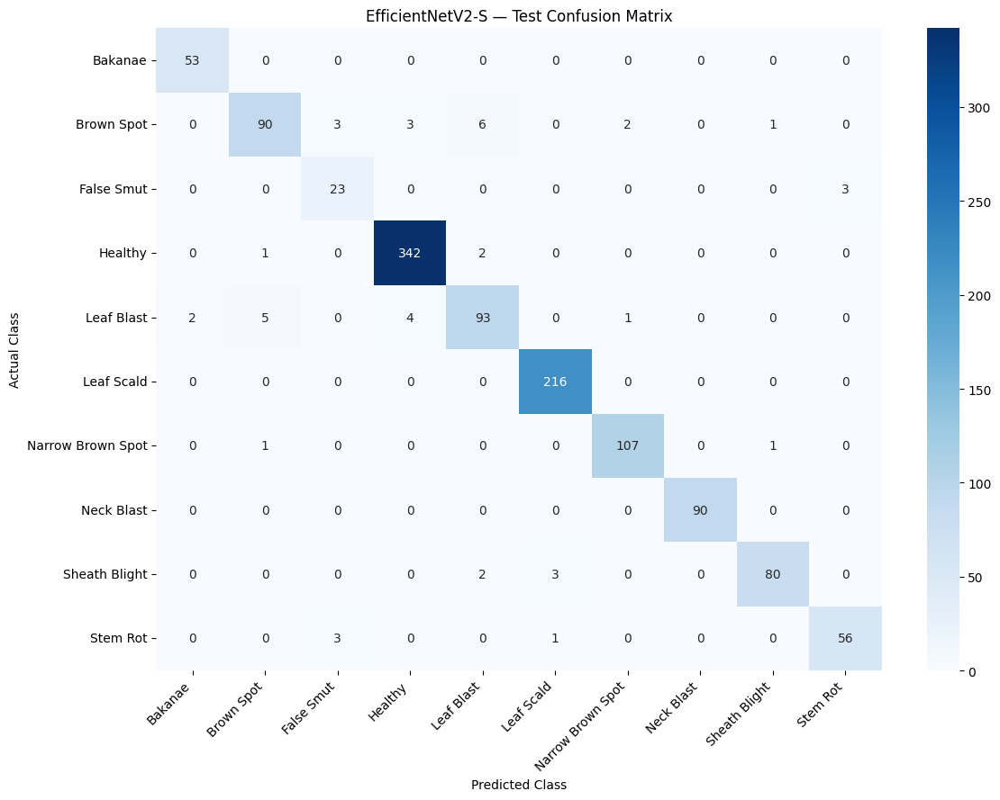


Test evaluation files saved successfully.


In [39]:
# FINAL TEST EVALUATION — BEST EPOCH 18 CHECKPOINT

import os
import torch
import timm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load best checkpoint
checkpoint = torch.load(
    FRESH_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

print("Loaded checkpoint:")
print("Epoch:", checkpoint["epoch"])
print("Validation Accuracy:",
      f"{checkpoint['validation_accuracy']:.2%}")
print("Validation Macro-F1:",
      f"{checkpoint['validation_macro_f1']:.2%}")

# 2. Create model and load best weights
test_model = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

test_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

test_model = test_model.to(DEVICE)
test_model.eval()

# 3. Evaluate on test dataset
test_labels = []
test_predictions = []
test_loss_sum = 0.0
test_total = 0

test_criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = test_model(images)
            loss = test_criterion(outputs, labels)

        batch_size = labels.size(0)

        test_loss_sum += loss.item() * batch_size
        test_total += batch_size

        test_labels.extend(labels.cpu().numpy())
        test_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )

# 4. Calculate metrics
test_loss = test_loss_sum / test_total

test_accuracy = accuracy_score(
    test_labels, test_predictions
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("\n" + "=" * 55)
print("FINAL TEST RESULTS — EFFICIENTNETV2-S")
print("=" * 55)

print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f"Test images:           {test_total}")
print(f"Test loss:             {test_loss:.4f}")
print(f"Test accuracy:         {test_accuracy:.2%}")
print(f"Test macro-F1:         {test_macro_f1:.2%}")

# 5. Classification report
report = classification_report(
    test_labels,
    test_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASSIFICATION REPORT")
display(report_df.round(4))

# 6. Confusion matrix
cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("EfficientNetV2-S — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 7. Save results
os.makedirs(FRESH_RESULTS_DIR, exist_ok=True)

report_df.to_csv(
    os.path.join(
        FRESH_RESULTS_DIR,
        "efficientnetv2_s_test_classification_report.csv"
    )
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    os.path.join(
        FRESH_RESULTS_DIR,
        "efficientnetv2_s_test_confusion_matrix.csv"
    )
)

print("\nTest evaluation files saved successfully.")

In [40]:
# EXPORT BEST EFFICIENTNETV2-S MODEL

import os
import torch
import shutil

EXPORT_DIR = "/kaggle/working/riceguard_ai"
os.makedirs(EXPORT_DIR, exist_ok=True)

# Copy best checkpoint
MODEL_EXPORT_PATH = os.path.join(
    EXPORT_DIR,
    "riceguard_efficientnetv2_s.pth"
)

shutil.copy2(
    FRESH_BEST_PATH,
    MODEL_EXPORT_PATH
)

# Save class names
import json

with open(
    os.path.join(EXPORT_DIR, "class_names.json"),
    "w"
) as f:
    json.dump(CLASS_NAMES, f, indent=4)

print("MODEL EXPORT COMPLETED")
print("Model:", MODEL_EXPORT_PATH)
print("Classes:", CLASS_NAMES)
print(
    "Model size:",
    round(os.path.getsize(MODEL_EXPORT_PATH) / (1024**2), 2),
    "MB"
)

MODEL EXPORT COMPLETED
Model: /kaggle/working/riceguard_ai/riceguard_efficientnetv2_s.pth
Classes: ['Bakanae', 'Brown Spot', 'False Smut', 'Healthy', 'Leaf Blast', 'Leaf Scald', 'Narrow Brown Spot', 'Neck Blast', 'Sheath Blight', 'Stem Rot']
Model size: 232.32 MB


In [41]:
# STEP 2: CREATE RICEGUARD AI PREDICTION MODULE

import os

backend_code = r'''
import torch
import timm
import json
from PIL import Image
from torchvision import transforms

MODEL_PATH = "riceguard_efficientnetv2_s.pth"
CLASS_PATH = "class_names.json"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

with open(CLASS_PATH, "r") as f:
    CLASS_NAMES = json.load(f)

model = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_disease(image_path):

    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        outputs = model(image)
        probabilities = torch.softmax(outputs, dim=1)

    confidence, predicted = probabilities.max(dim=1)

    return {
        "disease": CLASS_NAMES[predicted.item()],
        "confidence": round(confidence.item() * 100, 2)
    }
'''

backend_path = os.path.join(
    EXPORT_DIR,
    "predict.py"
)

with open(backend_path, "w") as f:
    f.write(backend_code)

print("Prediction backend created:", backend_path)

Prediction backend created: /kaggle/working/riceguard_ai/predict.py


In [44]:
# FIX PREDICTION BACKEND PATHS

backend_code = r'''
import os
import torch
import timm
import json
from PIL import Image
from torchvision import transforms

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    BASE_DIR, "riceguard_efficientnetv2_s.pth"
)

CLASS_PATH = os.path.join(
    BASE_DIR, "class_names.json"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

with open(CLASS_PATH, "r") as f:
    CLASS_NAMES = json.load(f)

model = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_disease(image_path):
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        outputs = model(image)
        probabilities = torch.softmax(outputs, dim=1)

    confidence, predicted = probabilities.max(dim=1)

    return {
        "disease": CLASS_NAMES[predicted.item()],
        "confidence": round(confidence.item() * 100, 2)
    }
'''

backend_path = os.path.join(EXPORT_DIR, "predict.py")

with open(backend_path, "w") as f:
    f.write(backend_code)

print("Backend paths fixed successfully.")
print("Export directory:", EXPORT_DIR)
print("Files:", os.listdir(EXPORT_DIR))

Backend paths fixed successfully.
Export directory: /kaggle/working/riceguard_ai
Files: ['__pycache__', 'riceguard_efficientnetv2_s.pth', 'class_names.json', 'predict.py']


In [47]:
# INSPECT CUSTOM DATASET ATTRIBUTES

dataset = test_loader.dataset

print("Dataset class:", type(dataset).__name__)

print("\nAvailable attributes:")

for name in dir(dataset):
    if not name.startswith("__"):
        value = getattr(dataset, name)

        if not callable(value):
            try:
                print(
                    f"{name}: type={type(value).__name__}, "
                    f"length={len(value) if hasattr(value, '__len__') else 'N/A'}"
                )
            except Exception:
                print(f"{name}: {type(value).__name__}")

print("\nFirst test batch:")
images, labels = next(iter(test_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First label:", labels[0].item())
print("Actual class:", CLASS_NAMES[labels[0].item()])

Dataset class: RiceDiseaseDataset

Available attributes:
dataframe: type=DataFrame, length=1194

First test batch:
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
First label: 1
Actual class: Brown Spot


In [48]:
# INSPECT TEST DATAFRAME

df = test_loader.dataset.dataframe

print("DataFrame columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nFirst test image label:")
print(df.iloc[0])

DataFrame columns:
['sha256', 'path', 'class_name', 'duplicate_count', 'split']

First 5 rows:


,sha256,path,class_name,duplicate_count,split
0,d20906cb22aaa8583cfbb76637360113cb439cb82e223f...,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,3,test
1,bd30a014f4de085fd107c1405c45938942bcb5ef34bb59...,/kaggle/input/datasets/sirichandanakota/rice-c...,Narrow Brown Spot,12,test
2,a565e3a27b57ac5a52ff7ebcce1654bdf52d9993279433...,/kaggle/input/datasets/sirichandanakota/rice-c...,Leaf Blast,3,test
3,3af6b55b04512059747d2c4c55408271e9ce70f9d9a1e4...,/kaggle/input/datasets/sirichandanakota/rice-c...,False Smut,8,test
4,b89397ea9a51ed55dbd71a52c674d017874fa7d6b14664...,/kaggle/input/datasets/sirichandanakota/rice-c...,Healthy,4,test



First test image label:
sha256             d20906cb22aaa8583cfbb76637360113cb439cb82e223f...
path               /kaggle/input/datasets/sirichandanakota/rice-c...
class_name                                                Brown Spot
duplicate_count                                                    3
split                                                           test
Name: 0, dtype: object


RICEGUARD AI — PREDICTION RESULT
Actual disease:     Brown Spot
Predicted disease:  Brown Spot
Confidence:         97.64%
Prediction status:  CORRECT


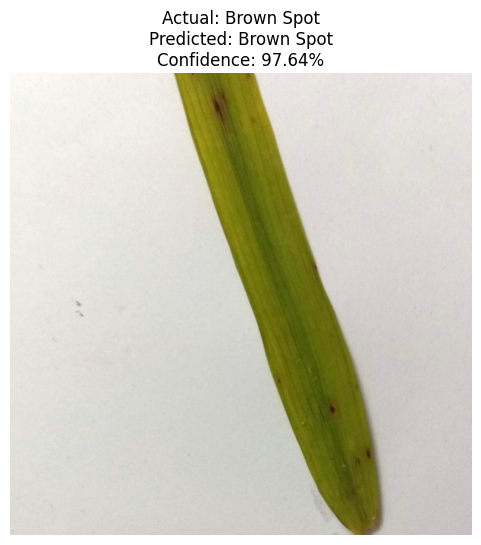

In [49]:
# RICEGUARD AI — REAL IMAGE PREDICTION TEST

import sys
import matplotlib.pyplot as plt

sys.path.insert(0, EXPORT_DIR)

from predict import predict_disease

# Get first test image from DataFrame
test_df = test_loader.dataset.dataframe

test_image_path = test_df.iloc[0]["path"]
actual_label = test_df.iloc[0]["class_name"]

# Predict
result = predict_disease(test_image_path)

print("=" * 50)
print("RICEGUARD AI — PREDICTION RESULT")
print("=" * 50)

print("Actual disease:    ", actual_label)
print("Predicted disease: ", result["disease"])
print("Confidence:        ", str(result["confidence"]) + "%")

print(
    "Prediction status: ",
    "CORRECT" if result["disease"] == actual_label else "INCORRECT"
)

# Display image
image = plt.imread(test_image_path)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(
    f"Actual: {actual_label}\n"
    f"Predicted: {result['disease']}\n"
    f"Confidence: {result['confidence']}%"
)
plt.axis("off")
plt.show()

In [50]:
# CONVNEXT-TINY — FRESH MODEL INITIALIZATION

import torch
import torch.nn as nn
import timm
import os
import gc

# Release unused GPU memory
gc.collect()
torch.cuda.empty_cache()

# Initialize without pretrained weights
convnext_model = timm.create_model(
    "convnext_tiny",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
)

convnext_model = convnext_model.to(DEVICE)

# Training configuration
convnext_criterion = nn.CrossEntropyLoss()

convnext_optimizer = torch.optim.AdamW(
    convnext_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

convnext_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    convnext_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

convnext_use_amp = DEVICE.type == "cuda"

convnext_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=convnext_use_amp
)

# Save directories
CONVNEXT_DIR = "/kaggle/working/rice_disease_project/convnext_tiny"

CONVNEXT_CHECKPOINT_DIR = os.path.join(
    CONVNEXT_DIR, "checkpoints"
)

CONVNEXT_RESULTS_DIR = os.path.join(
    CONVNEXT_DIR, "results"
)

os.makedirs(CONVNEXT_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(CONVNEXT_RESULTS_DIR, exist_ok=True)

CONVNEXT_BEST_PATH = os.path.join(
    CONVNEXT_CHECKPOINT_DIR,
    "best_convnext_tiny_fresh.pth"
)

CONVNEXT_HISTORY_PATH = os.path.join(
    CONVNEXT_RESULTS_DIR,
    "convnext_tiny_training_history.csv"
)

# Verify architecture
convnext_model.eval()

with torch.no_grad():
    dummy = torch.randn(2, 3, 224, 224).to(DEVICE)
    output = convnext_model(dummy)

print("=" * 50)
print("CONVNEXT-TINY INITIALIZATION")
print("=" * 50)

print("Architecture: ConvNeXt-Tiny")
print("Pretrained weights: False")
print("Number of classes:", len(CLASS_NAMES))
print("Output shape:", tuple(output.shape))
print("Parameters:", f"{sum(p.numel() for p in convnext_model.parameters()):,}")
print("Device:", DEVICE)
print("AMP enabled:", convnext_use_amp)

assert output.shape == (2, len(CLASS_NAMES))

print("\nConvNeXt-Tiny initialized successfully!")

CONVNEXT-TINY INITIALIZATION
Architecture: ConvNeXt-Tiny
Pretrained weights: False
Number of classes: 10
Output shape: (2, 10)
Parameters: 27,827,818
Device: cuda:0
AMP enabled: True

ConvNeXt-Tiny initialized successfully!


In [51]:
# CONVNEXT-TINY — EPOCH 1 TRAINING

import torch
from tqdm.auto import tqdm

convnext_model.train()

train_loss_sum = 0.0
train_correct = 0
train_total = 0

progress = tqdm(
    train_loader,
    desc="ConvNeXt-Tiny - Epoch 1 Training"
)

for images, labels in progress:

    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    convnext_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=convnext_use_amp
    ):
        outputs = convnext_model(images)
        loss = convnext_criterion(outputs, labels)

    convnext_scaler.scale(loss).backward()
    convnext_scaler.step(convnext_optimizer)
    convnext_scaler.update()

    batch_size = labels.size(0)

    train_loss_sum += loss.item() * batch_size

    train_correct += (
        outputs.argmax(dim=1) == labels
    ).sum().item()

    train_total += batch_size

convnext_train_loss = train_loss_sum / train_total
convnext_train_accuracy = train_correct / train_total

print("\nCONVNEXT-TINY — EPOCH 1 TRAINING")
print(f"Training loss:     {convnext_train_loss:.4f}")
print(f"Training accuracy: {convnext_train_accuracy:.2%}")
print(f"Training images:   {train_total}")

ConvNeXt-Tiny - Epoch 1 Training:   0%|          | 0/348 [00:00<?, ?it/s]


CONVNEXT-TINY — EPOCH 1 TRAINING
Training loss:     1.5627
Training accuracy: 44.05%
Training images:   5567


In [52]:
# CONVNEXT-TINY: AUTOMATIC TRAINING EPOCHS 2–20

import os
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

best_macro_f1 = 0.0
history = []

for epoch in range(2, 21):

    print(f"\n{'='*60}")
    print(f"CONVNEXT-TINY — EPOCH {epoch}/20")
    print(f"{'='*60}")

    # ---------------- TRAINING ----------------
    convnext_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch} Training"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        convnext_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=convnext_use_amp
        ):
            outputs = convnext_model(images)
            loss = convnext_criterion(outputs, labels)

        convnext_scaler.scale(loss).backward()
        convnext_scaler.step(convnext_optimizer)
        convnext_scaler.update()

        bs = labels.size(0)

        train_loss_sum += loss.item() * bs
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += bs

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------------- VALIDATION ----------------
    convnext_model.eval()

    val_loss_sum = 0.0
    val_total = 0
    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader, desc=f"Epoch {epoch} Validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=convnext_use_amp
            ):
                outputs = convnext_model(images)
                loss = convnext_criterion(outputs, labels)

            bs = labels.size(0)

            val_loss_sum += loss.item() * bs
            val_total += bs

            val_labels.extend(labels.cpu().tolist())
            val_predictions.extend(
                outputs.argmax(1).cpu().tolist()
            )

    val_loss = val_loss_sum / val_total
    val_accuracy = accuracy_score(
        val_labels, val_predictions
    )
    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # Learning rate scheduling
    convnext_scheduler.step(val_loss)

    current_lr = convnext_optimizer.param_groups[0]["lr"]

    print(f"\nEPOCH {epoch} RESULTS")
    print(f"Training loss:       {train_loss:.4f}")
    print(f"Training accuracy:   {train_accuracy:.2%}")
    print(f"Validation loss:     {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation macro-F1: {val_macro_f1:.2%}")
    print(f"Learning rate:       {current_lr:.8f}")

    # Save epoch history
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    history.append(row)

    pd.DataFrame(history).to_csv(
        CONVNEXT_HISTORY_PATH, index=False
    )

    # Save best checkpoint
    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1

        torch.save({
            "epoch": epoch,
            "model_name": "convnext_tiny_fresh",
            "model_state_dict": convnext_model.state_dict(),
            "optimizer_state_dict": convnext_optimizer.state_dict(),
            "scheduler_state_dict": convnext_scheduler.state_dict(),
            "validation_accuracy": val_accuracy,
            "validation_macro_f1": val_macro_f1,
            "validation_loss": val_loss,
            "class_names": CLASS_NAMES
        }, CONVNEXT_BEST_PATH)

        print("BEST CHECKPOINT SAVED")

# ---------------- FINAL SUMMARY ----------------

results_df = pd.DataFrame(history)

print("\n" + "="*70)
print("CONVNEXT-TINY — TRAINING SUMMARY")
print("="*70)

display(results_df.round(4))

best_row = results_df.loc[
    results_df["validation_macro_f1"].idxmax()
]

print("\nBEST MODEL")
print("Epoch:", int(best_row["epoch"]))
print(
    "Validation accuracy:",
    f"{best_row['validation_accuracy']:.2%}"
)
print(
    "Validation macro-F1:",
    f"{best_row['validation_macro_f1']:.2%}"
)

print("\nHistory:", CONVNEXT_HISTORY_PATH)
print("Checkpoint:", CONVNEXT_BEST_PATH)


CONVNEXT-TINY — EPOCH 2/20


Epoch 2 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 2 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EPOCH 2 RESULTS
Training loss:       0.9754
Training accuracy:   65.85%
Validation loss:     0.8147
Validation accuracy: 68.93%
Validation macro-F1: 58.68%
Learning rate:       0.00010000
BEST CHECKPOINT SAVED

CONVNEXT-TINY — EPOCH 3/20


Epoch 3 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Epoch 3 Validation:   0%|          | 0/75 [00:00<?, ?it/s]

... (50 outputs left out)

Epoch 20 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EPOCH 20 RESULTS
Training loss:       0.2324
Training accuracy:   91.18%
Validation loss:     0.2326
Validation accuracy: 92.55%
Validation macro-F1: 90.56%
Learning rate:       0.00010000
BEST CHECKPOINT SAVED

CONVNEXT-TINY — TRAINING SUMMARY


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate
0,2,0.9754,0.6585,0.8147,0.6893,0.5868,0.0001
1,3,0.7835,0.7121,0.7069,0.7538,0.6863,0.0001
2,4,0.6929,0.7462,0.6650,0.7395,0.6545,0.0001
3,5,0.6488,0.7579,0.6809,0.7529,0.6997,0.0001
4,6,0.5893,0.7771,0.6226,0.7714,0.7204,0.0001
5,7,0.5488,0.7976,0.5536,0.8032,0.7369,0.0001
6,8,0.5071,0.8168,0.5096,0.8141,0.7760,0.0001
7,9,0.4754,0.8279,0.4450,0.8250,0.7745,0.0001
8,10,0.4371,0.8407,0.4149,0.8484,0.8220,0.0001
9,11,0.4060,0.8522,0.4107,0.8618,0.8404,0.0001



BEST MODEL
Epoch: 20
Validation accuracy: 92.55%
Validation macro-F1: 90.56%

History: /kaggle/working/rice_disease_project/convnext_tiny/results/convnext_tiny_training_history.csv
Checkpoint: /kaggle/working/rice_disease_project/convnext_tiny/checkpoints/best_convnext_tiny_fresh.pth


CONVNEXT-TINY — TEST RESULTS
Best epoch: 20
Test loss: 0.1924
Test accuracy: 93.13%
Test macro-F1: 91.87%


,precision,recall,f1-score,support
Bakanae,1.0000,0.9811,0.9905,53.0000
Brown Spot,0.8152,0.7143,0.7614,105.0000
False Smut,0.9167,0.8462,0.8800,26.0000
Healthy,0.9739,0.9739,0.9739,345.0000
Leaf Blast,0.8018,0.8476,0.8241,105.0000
Leaf Scald,0.9683,0.9907,0.9794,216.0000
Narrow Brown Spot,0.8435,0.8899,0.8661,109.0000
Neck Blast,1.0000,1.0000,1.0000,90.0000
Sheath Blight,0.9167,0.9059,0.9112,85.0000
Stem Rot,1.0000,1.0000,1.0000,60.0000


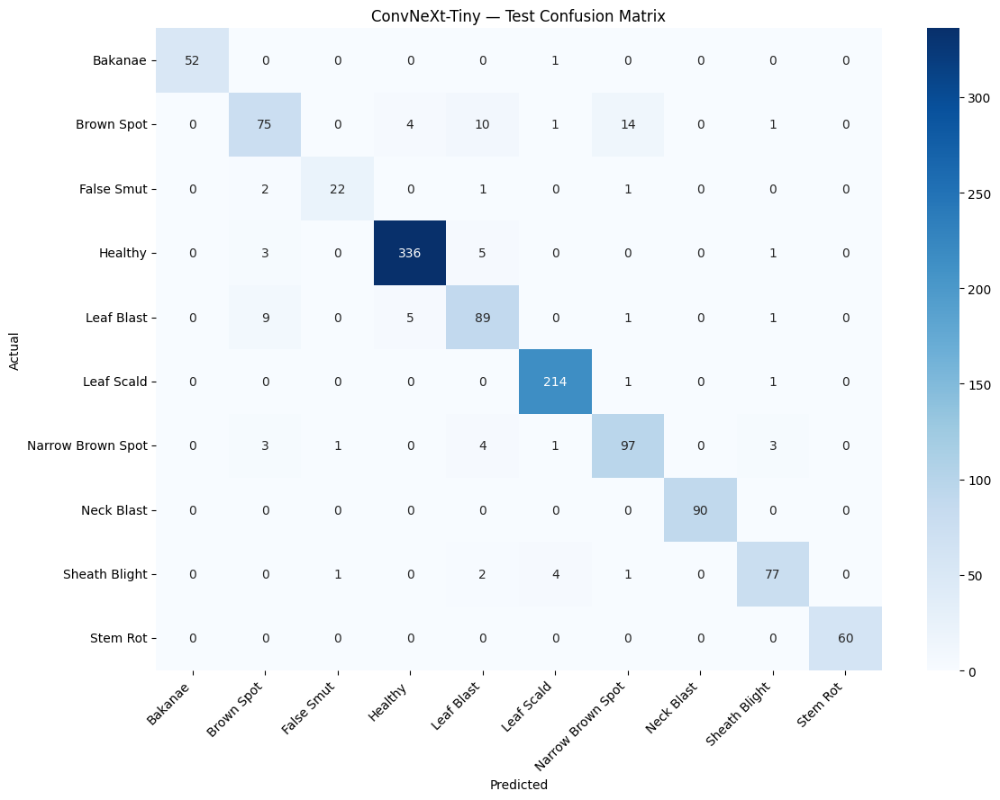

ConvNeXt-Tiny test evaluation saved.


In [53]:
# CONVNEXT-TINY — FINAL TEST EVALUATION

import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoint
checkpoint = torch.load(
    CONVNEXT_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

# Restore best model
test_convnext = timm.create_model(
    "convnext_tiny",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

test_convnext.load_state_dict(
    checkpoint["model_state_dict"]
)

test_convnext.eval()

# Evaluate untouched test set
test_labels = []
test_predictions = []
test_loss_sum = 0.0
test_total = 0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = test_convnext(images)
            loss = criterion(outputs, labels)

        bs = labels.size(0)

        test_loss_sum += loss.item() * bs
        test_total += bs

        test_labels.extend(labels.cpu().tolist())
        test_predictions.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )

# Metrics
test_loss = test_loss_sum / test_total

test_accuracy = accuracy_score(
    test_labels, test_predictions
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 55)
print("CONVNEXT-TINY — TEST RESULTS")
print("=" * 55)

print("Best epoch:", checkpoint["epoch"])
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test macro-F1: {test_macro_f1:.2%}")

# Classification report
report = classification_report(
    test_labels,
    test_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

# Confusion matrix
cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("ConvNeXt-Tiny — Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Save reports
report_df.to_csv(
    os.path.join(
        CONVNEXT_RESULTS_DIR,
        "convnext_tiny_test_report.csv"
    )
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    os.path.join(
        CONVNEXT_RESULTS_DIR,
        "convnext_tiny_confusion_matrix.csv"
    )
)

print("ConvNeXt-Tiny test evaluation saved.")

In [2]:
# Restore project configuration

CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

import torch
import timm
import pandas as pd
import torch.nn as nn
import os

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("Classes:", len(CLASS_NAMES))
print("Device:", DEVICE)
print("Configuration restored.")

Classes: 10
Device: cuda:0
Configuration restored.


In [4]:
import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/rice_disease_project"
MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)

print("Project directory exists:", os.path.exists(PROJECT_DIR))
print("Manifest exists:", os.path.exists(MANIFEST_PATH))

if os.path.exists(MANIFEST_PATH):
    manifest = pd.read_csv(MANIFEST_PATH)

    print("\nManifest columns:", manifest.columns.tolist())
    print("\nSplit counts:")
    print(manifest["split"].value_counts())

    print("\nClass counts:")
    print(pd.crosstab(manifest["class_name"], manifest["split"]))

Project directory exists: True
Manifest exists: False


In [5]:
import os

PROJECT_DIR = "/kaggle/working/rice_disease_project"

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print(f"\n{'  ' * level}{os.path.basename(root)}/")

    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{'  ' * (level + 1)}{file} ({size_mb:.2f} MB)")


rice_disease_project/

  swin_tiny/

    results/

    checkpoints/


In [6]:
import os

SEARCH_ROOTS = [
    "/kaggle/working",
    "/kaggle/input"
]

TARGET_FILES = {
    "dataset_split_manifest.csv",
    "unique_image_inventory.csv"
}

for base in SEARCH_ROOTS:
    print(f"\nSearching: {base}")

    for root, dirs, files in os.walk(base):
        dirs[:] = [
            d for d in dirs
            if d not in [".cache", "__pycache__"]
        ]

        for file in files:
            if file in TARGET_FILES:
                print(os.path.join(root, file))


Searching: /kaggle/working

Searching: /kaggle/input


In [7]:
import os

DATASET_ROOT = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)"
)

print("Dataset exists:", os.path.exists(DATASET_ROOT))

if os.path.exists(DATASET_ROOT):
    for folder in sorted(os.listdir(DATASET_ROOT)):
        path = os.path.join(DATASET_ROOT, folder)

        if os.path.isdir(path):
            count = sum(
                len(files)
                for _, _, files in os.walk(path)
            )
            print(f"{folder}: {count} files")

Dataset exists: True
Bakanae: 2000 files
Brown Spot: 3420 files
False Smut: 1200 files
Healthy: 6300 files
Leaf Blast: 3858 files
Leaf Scald: 4632 files
Narrow Brown Spot: 3438 files
Neck Blast: 1200 files
Sheath Blight: 3414 files
Stem Rot: 1200 files


In [8]:
# ============================================================
# RICEGUARD AI — DATASET RECOVERY
# SHA256 deduplication + stratified split
# ============================================================

import os
import hashlib
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

DATASET_ROOT = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)"
)

PROJECT_DIR = "/kaggle/working/rice_disease_project"

os.makedirs(PROJECT_DIR, exist_ok=True)

CLASS_NAMES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

SEED = 42

def calculate_sha256(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


# -------------------- SCAN AND HASH --------------------

records = []

for class_name in CLASS_NAMES:

    class_dir = os.path.join(DATASET_ROOT, class_name)

    if not os.path.isdir(class_dir):
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    image_paths = []

    for root, _, files in os.walk(class_dir):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                image_paths.append(os.path.join(root, file))

    print(f"{class_name}: {len(image_paths)} files")

    for path in tqdm(image_paths, desc=f"Hashing {class_name}"):

        try:
            with Image.open(path) as img:
                img.verify()

            sha256 = calculate_sha256(path)

            records.append({
                "sha256": sha256,
                "path": path,
                "class_name": class_name
            })

        except Exception as e:
            print("Skipping unreadable image:", path, str(e))


# -------------------- EXACT DEDUPLICATION --------------------

df = pd.DataFrame(records)

print("\nOriginal readable images:", len(df))

# Verify that no exact duplicate hash appears in different classes
cross_class = (
    df.groupby("sha256")["class_name"]
      .nunique()
)

if (cross_class > 1).any():
    raise ValueError(
        "Exact duplicate images exist across different classes. "
        "Resolve these before creating the split."
    )

df = (
    df.sort_values("path")
      .drop_duplicates(subset="sha256", keep="first")
      .reset_index(drop=True)
)

print("Unique images:", len(df))
print("Removed exact duplicates:", len(records) - len(df))


# -------------------- STRATIFIED 70/15/15 SPLIT --------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_name"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_name"],
    random_state=SEED
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# -------------------- VERIFY --------------------

assert len(manifest) == len(df)
assert manifest["sha256"].is_unique

print("\nSPLIT COUNTS")
print(manifest["split"].value_counts())

print("\nCLASS-WISE SPLIT")
display(
    pd.crosstab(
        manifest["class_name"],
        manifest["split"]
    )
)

# -------------------- SAVE --------------------

INVENTORY_PATH = os.path.join(
    PROJECT_DIR,
    "unique_image_inventory.csv"
)

MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "dataset_split_manifest.csv"
)

df.to_csv(INVENTORY_PATH, index=False)
manifest.to_csv(MANIFEST_PATH, index=False)

print("\nRECOVERY COMPLETE")
print("Inventory:", INVENTORY_PATH)
print("Manifest:", MANIFEST_PATH)
print("Total unique images:", len(manifest))
print("=" * 60)

Bakanae: 2000 files


Hashing Bakanae:   0%|          | 0/2000 [00:00<?, ?it/s]

Brown Spot: 3420 files


Hashing Brown Spot:   0%|          | 0/3420 [00:00<?, ?it/s]

False Smut: 1200 files


Hashing False Smut:   0%|          | 0/1200 [00:00<?, ?it/s]

... (13 outputs left out)

Hashing Stem Rot:   0%|          | 0/1200 [00:00<?, ?it/s]


Original readable images: 30662
Unique images: 7955
Removed exact duplicates: 22707

SPLIT COUNTS
split
train         5568
test          1194
validation    1193
Name: count, dtype: int64

CLASS-WISE SPLIT


split,test,train,validation
class_name,,,
Bakanae,52,245,53
Brown Spot,105,489,104
False Smut,26,123,27
Healthy,345,1607,344
Leaf Blast,106,491,105
Leaf Scald,216,1007,216
Narrow Brown Spot,109,508,109
Neck Blast,90,420,90
Sheath Blight,85,398,85



RECOVERY COMPLETE
Inventory: /kaggle/working/rice_disease_project/unique_image_inventory.csv
Manifest: /kaggle/working/rice_disease_project/dataset_split_manifest.csv
Total unique images: 7955


In [9]:
# ============================================================
# RICEGUARD AI — REBUILD DATA LOADERS
# ============================================================

import os
import torch
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

PROJECT_DIR = "/kaggle/working/rice_disease_project"

MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "dataset_split_manifest.csv"
)

CLASS_NAMES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 16
IMAGE_SIZE = 224
NUM_WORKERS = 2

# Load manifest
manifest = pd.read_csv(MANIFEST_PATH)

# ImageNet normalization
NORMALIZE = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# Training augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),
    transforms.ToTensor(),
    NORMALIZE
])

# Validation and test transformation
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    NORMALIZE
])


class RiceDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        self.class_to_idx = {
            name: idx
            for idx, name in enumerate(CLASS_NAMES)
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(row["path"]).convert("RGB")

        label = self.class_to_idx[row["class_name"]]

        if self.transform:
            image = self.transform(image)

        return image, label


# Separate splits
train_df = manifest[
    manifest["split"] == "train"
].copy()

val_df = manifest[
    manifest["split"] == "validation"
].copy()

test_df = manifest[
    manifest["split"] == "test"
].copy()

# Create datasets
train_dataset = RiceDiseaseDataset(
    train_df,
    train_transform
)

val_dataset = RiceDiseaseDataset(
    val_df,
    eval_transform
)

test_dataset = RiceDiseaseDataset(
    test_df,
    eval_transform
)

# Create loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Verify
print("=" * 60)
print("RICEGUARD AI — DATA LOADERS READY")
print("=" * 60)

print("Device:", DEVICE)
print("Classes:", len(CLASS_NAMES))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

print("\nChecking one training batch...")

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

assert images.shape[1:] == (3, 224, 224)
assert len(CLASS_NAMES) == 10

print("\nAll data loaders initialized successfully.")
print("=" * 60)

RICEGUARD AI — DATA LOADERS READY
Device: cuda:0
Classes: 10
Training images: 5568
Validation images: 1193
Testing images: 1194

Checking one training batch...
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])

All data loaders initialized successfully.


In [10]:
# ============================================================
# RICEGUARD AI — SWIN-TINY TRAINING (20 EPOCHS)
# Fresh training | No pretrained weights
# ============================================================

import os
import time
import torch
import timm
import pandas as pd
import torch.nn as nn

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# -------------------- CONFIGURATION --------------------

SWIN_MODEL_NAME = "swin_tiny_patch4_window7_224"
SWIN_EPOCHS = 20
SWIN_LR = 1e-4
SWIN_WEIGHT_DECAY = 1e-4

SWIN_DIR = "/kaggle/working/rice_disease_project/swin_tiny"
SWIN_CHECKPOINT_DIR = os.path.join(SWIN_DIR, "checkpoints")
SWIN_RESULTS_DIR = os.path.join(SWIN_DIR, "results")

os.makedirs(SWIN_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(SWIN_RESULTS_DIR, exist_ok=True)

SWIN_BEST_PATH = os.path.join(
    SWIN_CHECKPOINT_DIR,
    "best_swin_tiny_fresh.pth"
)

SWIN_HISTORY_PATH = os.path.join(
    SWIN_RESULTS_DIR,
    "swin_tiny_training_history.csv"
)

# Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# -------------------- MODEL INITIALIZATION --------------------

swin_model = timm.create_model(
    SWIN_MODEL_NAME,
    pretrained=False,
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

swin_criterion = nn.CrossEntropyLoss()

swin_optimizer = torch.optim.AdamW(
    swin_model.parameters(),
    lr=SWIN_LR,
    weight_decay=SWIN_WEIGHT_DECAY
)

swin_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    swin_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

swin_use_amp = DEVICE.type == "cuda"

swin_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=swin_use_amp
)

print("=" * 65)
print("SWIN-TINY MODEL INITIALIZED")
print("=" * 65)
print("Architecture:", SWIN_MODEL_NAME)
print("Pretrained:", False)
print("Parameters:", f"{sum(p.numel() for p in swin_model.parameters()):,}")
print("Device:", DEVICE)
print("Epochs:", SWIN_EPOCHS)
print("Learning rate:", SWIN_LR)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("=" * 65)

# -------------------- TRAINING --------------------

swin_history = []
swin_best_macro_f1 = 0.0
swin_best_epoch = 0

training_start = time.time()

for epoch in range(1, SWIN_EPOCHS + 1):

    epoch_start = time.time()

    # ==================== TRAIN ====================

    swin_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Swin-Tiny Epoch {epoch}/{SWIN_EPOCHS} Training"
    )

    for images, labels in train_bar:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        swin_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=swin_use_amp
        ):
            outputs = swin_model(images)
            loss = swin_criterion(outputs, labels)

        swin_scaler.scale(loss).backward()
        swin_scaler.step(swin_optimizer)
        swin_scaler.update()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ==================== VALIDATION ====================

    swin_model.eval()

    val_loss_sum = 0.0
    val_total = 0

    val_labels = []
    val_predictions = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Swin-Tiny Epoch {epoch}/{SWIN_EPOCHS} Validation"
        )

        for images, labels in val_bar:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=swin_use_amp
            ):
                outputs = swin_model(images)
                loss = swin_criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_total += batch_size

            val_labels.extend(labels.cpu().tolist())

            val_predictions.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )

    val_loss = val_loss_sum / val_total

    val_accuracy = accuracy_score(
        val_labels,
        val_predictions
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # Update scheduler
    swin_scheduler.step(val_loss)

    current_lr = swin_optimizer.param_groups[0]["lr"]

    # ==================== SAVE HISTORY ====================

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    swin_history.append(epoch_record)

    pd.DataFrame(swin_history).to_csv(
        SWIN_HISTORY_PATH,
        index=False
    )

    # ==================== BEST CHECKPOINT ====================

    if val_macro_f1 > swin_best_macro_f1:

        swin_best_macro_f1 = val_macro_f1
        swin_best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": swin_model.state_dict(),
                "optimizer_state_dict": swin_optimizer.state_dict(),
                "validation_accuracy": val_accuracy,
                "validation_macro_f1": val_macro_f1,
                "validation_loss": val_loss,
                "class_names": CLASS_NAMES,
                "model_name": SWIN_MODEL_NAME
            },
            SWIN_BEST_PATH
        )

        checkpoint_status = "BEST CHECKPOINT SAVED"

    else:
        checkpoint_status = ""

    epoch_time = time.time() - epoch_start

    # ==================== EPOCH RESULTS ====================

    print("\n" + "=" * 60)
    print(f"SWIN-TINY — EPOCH {epoch}/{SWIN_EPOCHS}")
    print("=" * 60)

    print(f"Training loss:       {train_loss:.4f}")
    print(f"Training accuracy:   {train_accuracy:.2%}")
    print(f"Validation loss:     {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation macro-F1: {val_macro_f1:.2%}")
    print(f"Learning rate:       {current_lr:.8f}")
    print(f"Epoch time:          {epoch_time / 60:.2f} minutes")

    if checkpoint_status:
        print(checkpoint_status)

# -------------------- FINAL SUMMARY --------------------

total_time = (time.time() - training_start) / 60

history_df = pd.DataFrame(swin_history)

print("\n" + "=" * 70)
print("SWIN-TINY — TRAINING SUMMARY")
print("=" * 70)

display(
    history_df.style.format({
        "train_loss": "{:.4f}",
        "train_accuracy": "{:.2%}",
        "validation_loss": "{:.4f}",
        "validation_accuracy": "{:.2%}",
        "validation_macro_f1": "{:.2%}",
        "learning_rate": "{:.8f}"
    })
)

print("\nBEST MODEL")
print("Epoch:", swin_best_epoch)
print(f"Best validation macro-F1: {swin_best_macro_f1:.2%}")

best_row = history_df.loc[
    history_df["epoch"] == swin_best_epoch
].iloc[0]

print(
    f"Best validation accuracy: "
    f"{best_row['validation_accuracy']:.2%}"
)

print(f"\nTotal training time: {total_time:.2f} minutes")
print("History:", SWIN_HISTORY_PATH)
print("Checkpoint:", SWIN_BEST_PATH)
print("=" * 70)

SWIN-TINY MODEL INITIALIZED
Architecture: swin_tiny_patch4_window7_224
Pretrained: False
Parameters: 27,527,044
Device: cuda:0
Epochs: 20
Learning rate: 0.0001
Training images: 5568
Validation images: 1193


Swin-Tiny Epoch 1/20 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Swin-Tiny Epoch 1/20 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


SWIN-TINY — EPOCH 1/20
Training loss:       1.1878
Training accuracy:   59.30%
Validation loss:     0.8174
Validation accuracy: 70.83%
Validation macro-F1: 60.83%
Learning rate:       0.00010000
Epoch time:          2.47 minutes
BEST CHECKPOINT SAVED


Swin-Tiny Epoch 2/20 Training:   0%|          | 0/348 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b67c9bb9800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b67c9bb9800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (62 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b67c9bb9800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b67c9bb9800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


SWIN-TINY — EPOCH 20/20
Training loss:       0.2131
Training accuracy:   92.04%
Validation loss:     0.2021
Validation accuracy: 94.05%
Validation macro-F1: 93.93%
Learning rate:       0.00010000
Epoch time:          2.43 minutes
BEST CHECKPOINT SAVED

SWIN-TINY — TRAINING SUMMARY


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate
0,1,1.1878,59.30%,0.8174,70.83%,60.83%,0.00010000
1,2,0.7725,72.49%,0.5770,79.21%,71.86%,0.00010000
2,3,0.6475,76.53%,0.5385,80.80%,76.39%,0.00010000
3,4,0.5818,79.09%,0.4802,82.90%,79.55%,0.00010000
4,5,0.5141,81.56%,0.4404,84.74%,81.34%,0.00010000
5,6,0.4429,84.23%,0.4197,85.25%,82.23%,0.00010000
6,7,0.4221,84.48%,0.4063,85.00%,81.60%,0.00010000
7,8,0.3818,86.60%,0.3286,88.52%,86.32%,0.00010000
8,9,0.3652,86.46%,0.3498,87.68%,85.07%,0.00010000
9,10,0.3319,88.58%,0.3350,88.26%,86.38%,0.00010000



BEST MODEL
Epoch: 20
Best validation macro-F1: 93.93%
Best validation accuracy: 94.05%

Total training time: 49.34 minutes
History: /kaggle/working/rice_disease_project/swin_tiny/results/swin_tiny_training_history.csv
Checkpoint: /kaggle/working/rice_disease_project/swin_tiny/checkpoints/best_swin_tiny_fresh.pth


SWIN-TINY — TEST RESULTS
Best epoch: 20
Test loss: 0.1852
Test accuracy: 94.05%
Test macro-F1: 93.66%


,precision,recall,f1-score,support
Bakanae,0.9811,1.0000,0.9905,52.0000
Brown Spot,0.8108,0.8571,0.8333,105.0000
False Smut,1.0000,0.9231,0.9600,26.0000
Healthy,0.9739,0.9739,0.9739,345.0000
Leaf Blast,0.9540,0.7830,0.8601,106.0000
Leaf Scald,0.9502,0.9722,0.9611,216.0000
Narrow Brown Spot,0.8673,0.8991,0.8829,109.0000
Neck Blast,1.0000,1.0000,1.0000,90.0000
Sheath Blight,0.9111,0.9647,0.9371,85.0000
Stem Rot,0.9667,0.9667,0.9667,60.0000


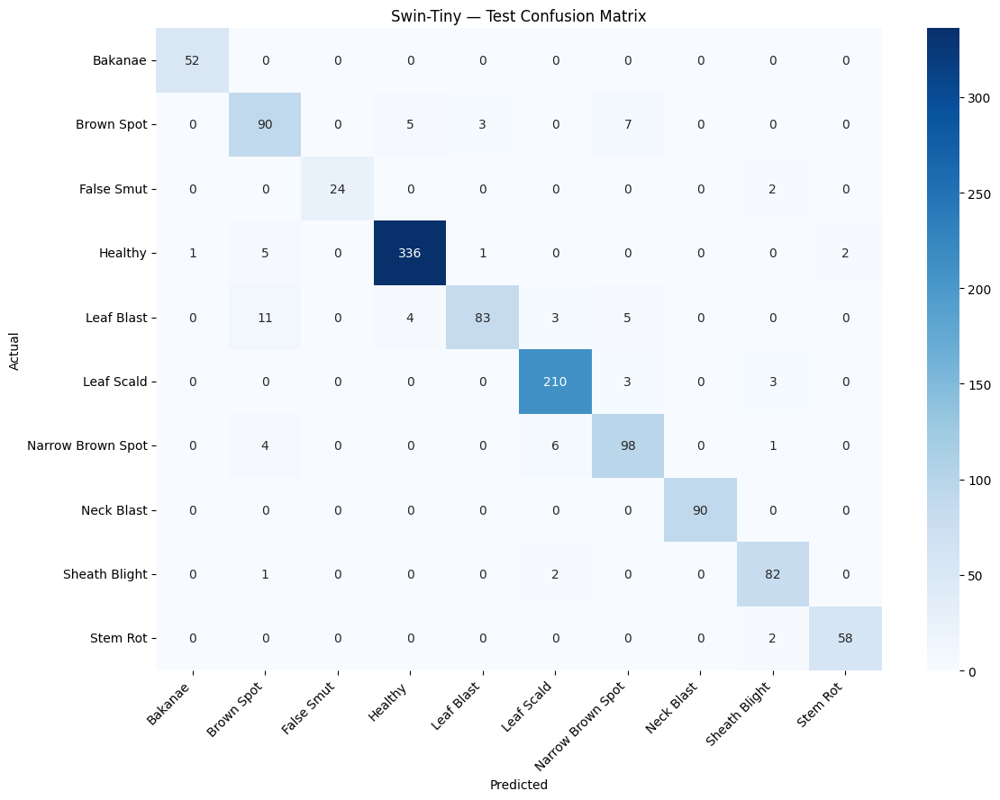


Test evaluation saved successfully.


In [11]:
# ============================================================
# SWIN-TINY — FINAL TEST EVALUATION
# ============================================================

import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SWIN_BEST_PATH = (
    "/kaggle/working/rice_disease_project/"
    "swin_tiny/checkpoints/best_swin_tiny_fresh.pth"
)

SWIN_RESULTS_DIR = (
    "/kaggle/working/rice_disease_project/"
    "swin_tiny/results"
)

# Load best checkpoint
checkpoint = torch.load(
    SWIN_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

# Recreate model
test_swin = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

test_swin.load_state_dict(
    checkpoint["model_state_dict"]
)

test_swin.eval()

criterion = torch.nn.CrossEntropyLoss()

test_labels = []
test_predictions = []
test_loss_sum = 0.0
test_total = 0

# Test evaluation
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = test_swin(images)
            loss = criterion(outputs, labels)

        batch_size = labels.size(0)

        test_loss_sum += loss.item() * batch_size
        test_total += batch_size

        test_labels.extend(labels.cpu().tolist())

        test_predictions.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )

# Metrics
test_loss = test_loss_sum / test_total

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("SWIN-TINY — TEST RESULTS")
print("=" * 60)

print("Best epoch:", checkpoint["epoch"])
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test macro-F1: {test_macro_f1:.2%}")

# Classification report
report = classification_report(
    test_labels,
    test_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

# Confusion matrix
cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Swin-Tiny — Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Save results
report_df.to_csv(
    os.path.join(
        SWIN_RESULTS_DIR,
        "swin_tiny_test_report.csv"
    )
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    os.path.join(
        SWIN_RESULTS_DIR,
        "swin_tiny_confusion_matrix.csv"
    )
)

print("\nTest evaluation saved successfully.")

In [12]:
# ============================================================
# RICEGUARD AI — EFFICIENTNETV2-S (FRESH TRAINING)
# 20 EPOCHS | RECONSTRUCTED DATASET SPLIT
# ============================================================

import os
import time
import torch
import timm
import pandas as pd
import torch.nn as nn

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ---------------- CONFIGURATION ----------------

MODEL_NAME = "efficientnetv2_s"
EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

EFF_DIR = "/kaggle/working/rice_disease_project/efficientnetv2_s_reconstructed"

EFF_CHECKPOINT_DIR = os.path.join(EFF_DIR, "checkpoints")
EFF_RESULTS_DIR = os.path.join(EFF_DIR, "results")

os.makedirs(EFF_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(EFF_RESULTS_DIR, exist_ok=True)

EFF_BEST_PATH = os.path.join(
    EFF_CHECKPOINT_DIR,
    "best_efficientnetv2_s_reconstructed.pth"
)

EFF_HISTORY_PATH = os.path.join(
    EFF_RESULTS_DIR,
    "efficientnetv2_s_training_history.csv"
)

# Verify existing loaders and configuration
assert len(CLASS_NAMES) == 10
assert len(train_loader.dataset) == 5568
assert len(val_loader.dataset) == 1193
assert len(test_loader.dataset) == 1194

# Reproducibility
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# ---------------- MODEL INITIALIZATION ----------------

eff_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

eff_criterion = nn.CrossEntropyLoss()

eff_optimizer = torch.optim.AdamW(
    eff_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

eff_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    eff_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

eff_use_amp = DEVICE.type == "cuda"

eff_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=eff_use_amp
)

print("=" * 65)
print("EFFICIENTNETV2-S — FRESH MODEL INITIALIZED")
print("=" * 65)
print("Pretrained:", False)
print("Parameters:", f"{sum(p.numel() for p in eff_model.parameters()):,}")
print("Device:", DEVICE)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))
print("Epochs:", EPOCHS)
print("=" * 65)

# ---------------- TRAINING ----------------

eff_history = []
eff_best_macro_f1 = -1.0
eff_best_epoch = 0

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    # ================= TRAIN =================

    eff_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"EfficientNetV2-S Epoch {epoch}/{EPOCHS} Training"
    )

    for images, labels in train_bar:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        eff_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=eff_use_amp
        ):
            outputs = eff_model(images)
            loss = eff_criterion(outputs, labels)

        eff_scaler.scale(loss).backward()
        eff_scaler.step(eff_optimizer)
        eff_scaler.update()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size

        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ================= VALIDATION =================

    eff_model.eval()

    val_loss_sum = 0.0
    val_total = 0

    val_labels = []
    val_predictions = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"EfficientNetV2-S Epoch {epoch}/{EPOCHS} Validation"
        )

        for images, labels in val_bar:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=eff_use_amp
            ):
                outputs = eff_model(images)
                loss = eff_criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_total += batch_size

            val_labels.extend(labels.cpu().tolist())

            val_predictions.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )

    val_loss = val_loss_sum / val_total

    val_accuracy = accuracy_score(
        val_labels,
        val_predictions
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    eff_scheduler.step(val_loss)

    current_lr = eff_optimizer.param_groups[0]["lr"]

    # ================= SAVE HISTORY =================

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    eff_history.append(record)

    pd.DataFrame(eff_history).to_csv(
        EFF_HISTORY_PATH,
        index=False
    )

    # ================= BEST CHECKPOINT =================

    checkpoint_status = ""

    if val_macro_f1 > eff_best_macro_f1:

        eff_best_macro_f1 = val_macro_f1
        eff_best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": eff_model.state_dict(),
                "optimizer_state_dict": eff_optimizer.state_dict(),
                "validation_accuracy": val_accuracy,
                "validation_macro_f1": val_macro_f1,
                "validation_loss": val_loss,
                "class_names": CLASS_NAMES,
                "model_name": MODEL_NAME
            },
            EFF_BEST_PATH
        )

        checkpoint_status = "BEST CHECKPOINT SAVED"

    epoch_time = time.time() - epoch_start

    # ================= EPOCH RESULTS =================

    print("\n" + "=" * 60)
    print(f"EFFICIENTNETV2-S — EPOCH {epoch}/{EPOCHS}")
    print("=" * 60)

    print(f"Training loss:       {train_loss:.4f}")
    print(f"Training accuracy:   {train_accuracy:.2%}")
    print(f"Validation loss:     {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Validation macro-F1: {val_macro_f1:.2%}")
    print(f"Learning rate:       {current_lr:.8f}")
    print(f"Epoch time:          {epoch_time / 60:.2f} minutes")

    if checkpoint_status:
        print(checkpoint_status)

# ---------------- FINAL SUMMARY ----------------

total_time = (time.time() - training_start) / 60

history_df = pd.DataFrame(eff_history)

print("\n" + "=" * 70)
print("EFFICIENTNETV2-S — TRAINING SUMMARY")
print("=" * 70)

display(
    history_df.style.format({
        "train_loss": "{:.4f}",
        "train_accuracy": "{:.2%}",
        "validation_loss": "{:.4f}",
        "validation_accuracy": "{:.2%}",
        "validation_macro_f1": "{:.2%}",
        "learning_rate": "{:.8f}"
    })
)

best_row = history_df.loc[
    history_df["epoch"] == eff_best_epoch
].iloc[0]

print("\nBEST MODEL")
print("Epoch:", eff_best_epoch)
print(f"Validation accuracy: {best_row['validation_accuracy']:.2%}")
print(f"Validation macro-F1: {eff_best_macro_f1:.2%}")
print(f"Training time: {total_time:.2f} minutes")

print("\nHistory:", EFF_HISTORY_PATH)
print("Checkpoint:", EFF_BEST_PATH)
print("=" * 70)

EFFICIENTNETV2-S — FRESH MODEL INITIALIZED
Pretrained: False
Parameters: 20,190,298
Device: cuda:0
Training images: 5568
Validation images: 1193
Test images: 1194
Epochs: 20


EfficientNetV2-S Epoch 1/20 Training:   0%|          | 0/348 [00:00<?, ?it/s]

EfficientNetV2-S Epoch 1/20 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EFFICIENTNETV2-S — EPOCH 1/20
Training loss:       1.7219
Training accuracy:   46.19%
Validation loss:     2.7026
Validation accuracy: 65.21%
Validation macro-F1: 52.47%
Learning rate:       0.00010000
Epoch time:          2.62 minutes
BEST CHECKPOINT SAVED


EfficientNetV2-S Epoch 2/20 Training:   0%|          | 0/348 [00:00<?, ?it/s]

EfficientNetV2-S Epoch 2/20 Validation:   0%|          | 0/75 [00:00<?, ?it/s]

... (58 outputs left out)

EfficientNetV2-S Epoch 20/20 Validation:   0%|          | 0/75 [00:00<?, ?it/s]


EFFICIENTNETV2-S — EPOCH 20/20
Training loss:       0.1832
Training accuracy:   93.46%
Validation loss:     3.1745
Validation accuracy: 95.05%
Validation macro-F1: 94.09%
Learning rate:       0.00000313
Epoch time:          2.50 minutes

EFFICIENTNETV2-S — TRAINING SUMMARY


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate
0,1,1.7219,46.19%,2.7026,65.21%,52.47%,0.00010000
1,2,1.0268,64.80%,3.3124,74.85%,63.63%,0.00010000
2,3,0.8376,71.10%,2.0501,78.88%,71.60%,0.00010000
3,4,0.7544,73.55%,1.2964,79.97%,73.52%,0.00010000
4,5,0.6318,77.62%,2.0235,80.05%,72.66%,0.00010000
5,6,0.5995,78.97%,2.6526,84.66%,81.17%,0.00010000
6,7,0.5335,81.11%,2.2511,83.49%,77.83%,0.00005000
7,8,0.4322,84.54%,2.8119,86.09%,80.65%,0.00005000
8,9,0.3875,86.06%,1.3908,89.94%,87.51%,0.00005000
9,10,0.3754,86.67%,2.0017,90.86%,88.84%,0.00002500



BEST MODEL
Epoch: 18
Validation accuracy: 94.89%
Validation macro-F1: 94.21%
Training time: 53.11 minutes

History: /kaggle/working/rice_disease_project/efficientnetv2_s_reconstructed/results/efficientnetv2_s_training_history.csv
Checkpoint: /kaggle/working/rice_disease_project/efficientnetv2_s_reconstructed/checkpoints/best_efficientnetv2_s_reconstructed.pth


In [1]:
# ============================================================
# EFFICIENTNETV2-S — FINAL TEST EVALUATION
# RECONSTRUCTED DATASET SPLIT
# ============================================================

import os
import torch
import timm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

EFF_BEST_PATH = (
    "/kaggle/working/rice_disease_project/"
    "efficientnetv2_s_reconstructed/checkpoints/"
    "best_efficientnetv2_s_reconstructed.pth"
)

EFF_RESULTS_DIR = (
    "/kaggle/working/rice_disease_project/"
    "efficientnetv2_s_reconstructed/results"
)

# Load best checkpoint
checkpoint = torch.load(
    EFF_BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

# Recreate model
test_eff_model = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

test_eff_model.load_state_dict(
    checkpoint["model_state_dict"]
)

test_eff_model.eval()

criterion = torch.nn.CrossEntropyLoss()

test_labels = []
test_predictions = []
test_loss_sum = 0.0
test_total = 0

# Test evaluation
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = test_eff_model(images)
            loss = criterion(outputs, labels)

        batch_size = labels.size(0)

        test_loss_sum += loss.item() * batch_size
        test_total += batch_size

        test_labels.extend(labels.cpu().tolist())

        test_predictions.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )

# Calculate metrics
test_loss = test_loss_sum / test_total

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("EFFICIENTNETV2-S — TEST RESULTS")
print("=" * 60)

print("Best epoch:", checkpoint["epoch"])
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test macro-F1: {test_macro_f1:.2%}")

# Classification report
report = classification_report(
    test_labels,
    test_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

# Confusion matrix
cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("EfficientNetV2-S — Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Save results
report_df.to_csv(
    os.path.join(
        EFF_RESULTS_DIR,
        "efficientnetv2_s_test_report.csv"
    )
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    os.path.join(
        EFF_RESULTS_DIR,
        "efficientnetv2_s_confusion_matrix.csv"
    )
)

print("\nTest evaluation saved successfully.")

NameError: name 'DEVICE' is not defined

In [17]:
import os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

backup = "riceguard_ai_backup.zip"

if os.path.exists(backup):
    print("Backup exists:", round(os.path.getsize(backup) / (1024**2), 2), "MB")
    display(FileLink(backup))
else:
    print("Backup file not found.")

Backup exists: 503.59 MB


/kaggle/working/riceguard_ai_backup.zip

In [1]:
import os
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/rice_disease_project")

print("PROJECT FOLDER:", PROJECT_DIR.exists())

if PROJECT_DIR.exists():
    print("\nProject contents:")
    for item in PROJECT_DIR.iterdir():
        print("📁" if item.is_dir() else "📄", item.name)

    print("\nImportant files:")
    files_to_check = [
        PROJECT_DIR / "dataset_split_manifest.csv",
        PROJECT_DIR / "unique_image_inventory.csv",
        PROJECT_DIR / "swin_tiny/checkpoints/best_swin_tiny_fresh.pth",
        PROJECT_DIR / "efficientnetv2_s_reconstructed/checkpoints/best_efficientnetv2_s_reconstructed.pth"
    ]

    for file in files_to_check:
        print(("✅" if file.exists() else "❌"), file.name)
else:
    print("Project not restored yet.")

PROJECT FOLDER: False
Project not restored yet.


In [4]:
import os

print("Files available in Kaggle input:")

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

Files available in Kaggle input:
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)/Bakanae/Bakanae (1).jpeg
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)/Bakanae/Bakanae (101).jpeg
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)/Bakanae/Bakanae (102).jpeg
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)/Bakanae/Bakanae (103).jpeg
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)/Bakanae/Bakanae (104).jpeg
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset/Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves

In [5]:
import os
import shutil
from pathlib import Path

SOURCE = Path(
    "/kaggle/input/datasets/sirichandanakota/backup-data"
)

PROJECT_DIR = Path("/kaggle/working/rice_disease_project")

if not SOURCE.exists():
    raise FileNotFoundError(f"Backup not found: {SOURCE}")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

shutil.copytree(
    SOURCE,
    PROJECT_DIR,
    dirs_exist_ok=True
)

print("=" * 60)
print("RICEGUARD AI PROJECT RESTORED")
print("=" * 60)

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(f"FOUND: {path.relative_to(PROJECT_DIR)}")

print("\nManifest:", (PROJECT_DIR / "dataset_split_manifest.csv").exists())
print("Inventory:", (PROJECT_DIR / "unique_image_inventory.csv").exists())

RICEGUARD AI PROJECT RESTORED
FOUND: dataset_split_manifest.csv
FOUND: efficientnetv2_s_reconstructed/checkpoints/best_efficientnetv2_s_reconstructed.pth
FOUND: efficientnetv2_s_reconstructed/results/efficientnetv2_s_confusion_matrix.csv
FOUND: efficientnetv2_s_reconstructed/results/efficientnetv2_s_test_report.csv
FOUND: efficientnetv2_s_reconstructed/results/efficientnetv2_s_training_history.csv
FOUND: swin_tiny/checkpoints/best_swin_tiny_fresh.pth
FOUND: swin_tiny/results/swin_tiny_confusion_matrix.csv
FOUND: swin_tiny/results/swin_tiny_test_report.csv
FOUND: swin_tiny/results/swin_tiny_training_history.csv
FOUND: unique_image_inventory.csv

Manifest: True
Inventory: True


In [6]:
import os
import pandas as pd

PROJECT_DIR = "/kaggle/working/rice_disease_project"

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)

INVENTORY_PATH = os.path.join(
    PROJECT_DIR, "unique_image_inventory.csv"
)

DATASET_DIR = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-crop-dataset/"
    "Self-Collected Real-Field Dataset of Rice Fungal Diseases and Healthy Leaves(org)"
)

manifest = pd.read_csv(MANIFEST_PATH)
inventory = pd.read_csv(INVENTORY_PATH)

print("=" * 60)
print("RICEGUARD AI DATA VERIFICATION")
print("=" * 60)

print("\nInventory rows:", len(inventory))
print("Manifest rows:", len(manifest))

print("\nSplit distribution:")
print(manifest["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(manifest["class_name"], manifest["split"]))

missing = [
    p for p in manifest["path"]
    if not os.path.isfile(p)
]

print("\nMissing image paths:", len(missing))

hash_sets = {
    split: set(manifest.loc[manifest["split"] == split, "sha256"])
    for split in ["train", "validation", "test"]
}

overlap = (
    (hash_sets["train"] & hash_sets["validation"]) |
    (hash_sets["train"] & hash_sets["test"]) |
    (hash_sets["validation"] & hash_sets["test"])
)

print("Cross-split duplicate hashes:", len(overlap))

assert len(manifest) == 7955
assert len(inventory) == 7955
assert len(missing) == 0
assert len(overlap) == 0

print("\n✅ DATA VERIFICATION PASSED")

RICEGUARD AI DATA VERIFICATION

Inventory rows: 7955
Manifest rows: 7955

Split distribution:
split
train         5568
test          1194
validation    1193
Name: count, dtype: int64

Class distribution:
split              test  train  validation
class_name                                
Bakanae              52    245          53
Brown Spot          105    489         104
False Smut           26    123          27
Healthy             345   1607         344
Leaf Blast          106    491         105
Leaf Scald          216   1007         216
Narrow Brown Spot   109    508         109
Neck Blast           90    420          90
Sheath Blight        85    398          85
Stem Rot             60    280          60

Missing image paths: 0
Cross-split duplicate hashes: 0

✅ DATA VERIFICATION PASSED


In [7]:
import os
import random
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Configuration
PROJECT_DIR = "/kaggle/working/rice_disease_project"
MANIFEST_PATH = os.path.join(PROJECT_DIR, "dataset_split_manifest.csv")

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2

CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

CLASS_TO_IDX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Load the exact restored manifest
manifest = pd.read_csv(MANIFEST_PATH)

train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "validation"].reset_index(drop=True)
test_df = manifest[manifest["split"] == "test"].reset_index(drop=True)

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset class
class RiceDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["path"]).convert("RGB")
        label = CLASS_TO_IDX[row["class_name"]]

        if self.transform:
            image = self.transform(image)

        return image, label

# Create datasets
train_dataset = RiceDiseaseDataset(train_df, train_transform)
val_dataset = RiceDiseaseDataset(val_df, eval_transform)
test_dataset = RiceDiseaseDataset(test_df, eval_transform)

# Create loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Verify a batch
images, labels = next(iter(train_loader))

print("=" * 60)
print("RICEGUARD AI DATALOADER VERIFICATION")
print("=" * 60)

print("Device:", device)
print("Classes:", len(CLASS_NAMES))
print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("\nClass mapping:")
for name, index in CLASS_TO_IDX.items():
    print(f"{index}: {name}")

assert images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() < len(CLASS_NAMES)

print("\n✅ DATALOADERS READY")

RICEGUARD AI DATALOADER VERIFICATION
Device: cuda:0
Classes: 10
Train samples: 5568
Validation samples: 1193
Test samples: 1194

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64

Class mapping:
0: Bakanae
1: Brown Spot
2: False Smut
3: Healthy
4: Leaf Blast
5: Leaf Scald
6: Narrow Brown Spot
7: Neck Blast
8: Sheath Blight
9: Stem Rot

✅ DATALOADERS READY


In [8]:
import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 20
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

MODEL_NAME = "convnext_tiny"
NUM_CLASSES = len(CLASS_NAMES)

MODEL_DIR = os.path.join(
    PROJECT_DIR, "convnext_tiny_reconstructed"
)

CHECKPOINT_DIR = os.path.join(MODEL_DIR, "checkpoints")
RESULTS_DIR = os.path.join(MODEL_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR, "best_convnext_tiny_reconstructed.pth"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR, "convnext_tiny_training_history.csv"
)

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

# ============================================================
# MODEL
# ============================================================

model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=NUM_CLASSES
)

model = model.to(device)

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# ============================================================
# TRAINING AND VALIDATION FUNCTIONS
# ============================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        predictions = outputs.argmax(dim=1)

        running_loss += loss.item() * images.size(0)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)
    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


@torch.no_grad()
def validate_one_epoch(model, loader):

    model.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        running_loss += loss.item() * images.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)
    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ============================================================
# TRAINING LOOP — ALL 20 EPOCHS
# ============================================================

history = []

best_val_f1 = -1.0
best_epoch = 0

print("=" * 65)
print("RICEGUARD AI — CONVNEXT-TINY TRAINING")
print("=" * 65)

print("Architecture:", MODEL_NAME)
print("Pretrained:", False)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Device:", device)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    print(f"\n{'=' * 65}")
    print(f"EPOCH {epoch}/{EPOCHS}")
    print("=" * 65)

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc, val_f1 = validate_one_epoch(
        model,
        val_loader
    )

    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]
    epoch_time = time.time() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    }

    history.append(record)

    # Save training history after every epoch
    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    # Save best checkpoint using validation macro-F1
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_name": MODEL_NAME,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "best_val_accuracy": val_acc,
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "seed": SEED
            },
            BEST_CHECKPOINT
        )

        print("🏆 BEST CHECKPOINT UPDATED")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Train Macro-F1: {train_f1 * 100:.2f}%")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc * 100:.2f}%")
    print(f"Validation Macro-F1: {val_f1 * 100:.2f}%")

    print(f"Learning Rate: {current_lr:.7f}")
    print(f"Epoch Time: {epoch_time / 60:.2f} minutes")

# ============================================================
# TRAINING SUMMARY
# ============================================================

total_time = (time.time() - training_start) / 60

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)

print("\n" + "=" * 65)
print("CONVNEXT-TINY TRAINING COMPLETED")
print("=" * 65)

print("Completed epochs:", len(history_df))
print("Best epoch:", best_epoch)
print(f"Best validation Macro-F1: {best_val_f1 * 100:.2f}%")

best_row = history_df.loc[
    history_df["val_macro_f1"].idxmax()
]

print(
    f"Best validation accuracy: "
    f"{best_row['val_accuracy'] * 100:.2f}%"
)

print(f"Total training time: {total_time:.2f} minutes")

print("\nCheckpoint:", BEST_CHECKPOINT)
print("Training history:", HISTORY_PATH)

assert os.path.isfile(BEST_CHECKPOINT)
assert len(history_df) == EPOCHS

print("\n✅ CONVNEXT-TINY TRAINING AND CHECKPOINT SAVING COMPLETED")

RICEGUARD AI — CONVNEXT-TINY TRAINING
Architecture: convnext_tiny
Pretrained: False
Epochs: 20
Batch size: 16
Learning rate: 0.0003
Device: cuda:0
Training images: 5568
Validation images: 1193

EPOCH 1/20


Training:   0%|          | 0/348 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

🏆 BEST CHECKPOINT UPDATED
Train Loss: 1.6872
Train Accuracy: 48.26%
Train Macro-F1: 39.61%
Validation Loss: 1.2651
Validation Accuracy: 66.14%
Validation Macro-F1: 53.94%
Learning Rate: 0.0002982
Epoch Time: 9.49 minutes

EPOCH 2/20


Training:   0%|          | 0/348 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (73 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.5757
Train Accuracy: 97.58%
Train Macro-F1: 97.28%
Validation Loss: 0.6255
Validation Accuracy: 95.22%
Validation Macro-F1: 95.06%
Learning Rate: 0.0000000
Epoch Time: 2.82 minutes

CONVNEXT-TINY TRAINING COMPLETED
Completed epochs: 20
Best epoch: 17
Best validation Macro-F1: 95.47%
Best validation accuracy: 95.56%
Total training time: 65.31 minutes

Checkpoint: /kaggle/working/rice_disease_project/convnext_tiny_reconstructed/checkpoints/best_convnext_tiny_reconstructed.pth
Training history: /kaggle/working/rice_disease_project/convnext_tiny_reconstructed/results/convnext_tiny_training_history.csv

✅ CONVNEXT-TINY TRAINING AND CHECKPOINT SAVING COMPLETED


In [10]:
import os
import itertools
import numpy as np
import pandas as pd
import torch
import timm

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

MODEL_CONFIGS = {
    "EfficientNetV2-S": {
        "architecture": "efficientnetv2_s",
        "checkpoint": os.path.join(
            PROJECT_DIR,
            "efficientnetv2_s_reconstructed",
            "checkpoints",
            "best_efficientnetv2_s_reconstructed.pth"
        )
    },

    "Swin-Tiny": {
        "architecture": "swin_tiny_patch4_window7_224",
        "checkpoint": os.path.join(
            PROJECT_DIR,
            "swin_tiny",
            "checkpoints",
            "best_swin_tiny_fresh.pth"
        )
    },

    "ConvNeXt-Tiny": {
        "architecture": "convnext_tiny",
        "checkpoint": os.path.join(
            PROJECT_DIR,
            "convnext_tiny_reconstructed",
            "checkpoints",
            "best_convnext_tiny_reconstructed.pth"
        )
    }
}

ENSEMBLE_DIR = os.path.join(
    PROJECT_DIR, "ensemble_experiments"
)

os.makedirs(ENSEMBLE_DIR, exist_ok=True)

# ============================================================
# LOAD CHECKPOINTS AND GENERATE VALIDATION PROBABILITIES
# ============================================================

validation_probabilities = {}
validation_labels = None

amp_enabled = device.type == "cuda"

for model_name, config in MODEL_CONFIGS.items():

    print(f"\nLoading {model_name}...")

    checkpoint_path = config["checkpoint"]

    assert os.path.isfile(checkpoint_path), (
        f"Checkpoint missing: {checkpoint_path}"
    )

    model = timm.create_model(
        config["architecture"],
        pretrained=False,
        num_classes=len(CLASS_NAMES)
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        state_dict = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict, strict=True)
    model.eval()

    probabilities = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(
            val_loader,
            desc=f"{model_name} validation"
        ):

            images = images.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=amp_enabled
            ):
                outputs = model(images)

            probs = torch.softmax(outputs.float(), dim=1)

            probabilities.append(probs.cpu().numpy())
            labels_list.append(labels.numpy())

    probabilities = np.concatenate(probabilities, axis=0)
    labels_array = np.concatenate(labels_list, axis=0)

    if validation_labels is None:
        validation_labels = labels_array
    else:
        assert np.array_equal(
            validation_labels, labels_array
        ), "Validation label order mismatch!"

    validation_probabilities[model_name] = probabilities

    predictions = probabilities.argmax(axis=1)

    accuracy = accuracy_score(validation_labels, predictions)

    macro_f1 = f1_score(
        validation_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    print(f"{model_name} Accuracy: {accuracy * 100:.2f}%")
    print(f"{model_name} Macro-F1: {macro_f1 * 100:.2f}%")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ============================================================
# ENSEMBLE EVALUATION FUNCTION
# ============================================================

def evaluate_ensemble(probabilities, labels):

    predictions = probabilities.argmax(axis=1)

    accuracy = accuracy_score(labels, predictions)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1


# ============================================================
# INDIVIDUAL MODEL RESULTS
# ============================================================

results = []

for name, probs in validation_probabilities.items():

    accuracy, macro_f1 = evaluate_ensemble(
        probs, validation_labels
    )

    results.append({
        "Experiment": name,
        "Weights": "Individual",
        "Validation Accuracy": accuracy,
        "Validation Macro-F1": macro_f1
    })

# ============================================================
# TWO-MODEL WEIGHT SEARCH
# ============================================================

model_names = list(validation_probabilities.keys())

weight_values = np.arange(0.05, 1.00, 0.05)

pair_combinations = [
    ("EfficientNetV2-S", "ConvNeXt-Tiny"),
    ("EfficientNetV2-S", "Swin-Tiny"),
    ("ConvNeXt-Tiny", "Swin-Tiny")
]

for first, second in pair_combinations:

    best_result = None

    for weight_first in weight_values:

        weight_second = 1.0 - weight_first

        combined_probs = (
            weight_first * validation_probabilities[first]
            +
            weight_second * validation_probabilities[second]
        )

        accuracy, macro_f1 = evaluate_ensemble(
            combined_probs,
            validation_labels
        )

        candidate = {
            "Experiment": f"{first} + {second}",
            "Weights": (
                f"{weight_first:.2f} / {weight_second:.2f}"
            ),
            "Validation Accuracy": accuracy,
            "Validation Macro-F1": macro_f1
        }

        if (
            best_result is None
            or macro_f1 > best_result["Validation Macro-F1"]
        ):
            best_result = candidate

    results.append(best_result)

# ============================================================
# THREE-MODEL WEIGHT SEARCH
# ============================================================

first = "EfficientNetV2-S"
second = "Swin-Tiny"
third = "ConvNeXt-Tiny"

best_three_model = None

for w1 in weight_values:

    for w2 in weight_values:

        w3 = 1.0 - w1 - w2

        if w3 < 0.05:
            continue

        combined_probs = (
            w1 * validation_probabilities[first]
            +
            w2 * validation_probabilities[second]
            +
            w3 * validation_probabilities[third]
        )

        accuracy, macro_f1 = evaluate_ensemble(
            combined_probs,
            validation_labels
        )

        candidate = {
            "Experiment": "Three-Model Ensemble",
            "Weights": (
                f"{w1:.2f} / {w2:.2f} / {w3:.2f}"
            ),
            "Validation Accuracy": accuracy,
            "Validation Macro-F1": macro_f1
        }

        if (
            best_three_model is None
            or macro_f1 > best_three_model["Validation Macro-F1"]
        ):
            best_three_model = candidate

results.append(best_three_model)

# ============================================================
# FINAL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation Macro-F1",
    ascending=False
).reset_index(drop=True)

results_path = os.path.join(
    ENSEMBLE_DIR,
    "validation_ensemble_comparison.csv"
)

results_df.to_csv(results_path, index=False)

print("\n" + "=" * 80)
print("RICEGUARD AI — VALIDATION ENSEMBLE COMPARISON")
print("=" * 80)

display(
    results_df.style.format({
        "Validation Accuracy": "{:.2%}",
        "Validation Macro-F1": "{:.2%}"
    })
)

print("\nBest validation experiment:")
print(results_df.iloc[0].to_string())

print("\nSaved:", results_path)

print("\n✅ VALIDATION ENSEMBLE EXPERIMENTS COMPLETED")
print("Test set remains untouched.")


Loading EfficientNetV2-S...


EfficientNetV2-S validation:   0%|          | 0/75 [00:00<?, ?it/s]

EfficientNetV2-S Accuracy: 95.05%
EfficientNetV2-S Macro-F1: 94.41%

Loading Swin-Tiny...


Swin-Tiny validation:   0%|          | 0/75 [00:00<?, ?it/s]

Swin-Tiny Accuracy: 94.05%
Swin-Tiny Macro-F1: 93.93%

Loading ConvNeXt-Tiny...


ConvNeXt-Tiny validation:   0%|          | 0/75 [00:00<?, ?it/s]

ConvNeXt-Tiny Accuracy: 95.56%
ConvNeXt-Tiny Macro-F1: 95.47%

RICEGUARD AI — VALIDATION ENSEMBLE COMPARISON


,Experiment,Weights,Validation Accuracy,Validation Macro-F1
0,Three-Model Ensemble,0.45 / 0.30 / 0.25,97.15%,97.08%
1,EfficientNetV2-S + Swin-Tiny,0.45 / 0.55,96.73%,96.70%
2,ConvNeXt-Tiny + Swin-Tiny,0.45 / 0.55,96.48%,96.49%
3,EfficientNetV2-S + ConvNeXt-Tiny,0.40 / 0.60,96.40%,96.39%
4,ConvNeXt-Tiny,Individual,95.56%,95.47%
5,EfficientNetV2-S,Individual,95.05%,94.41%
6,Swin-Tiny,Individual,94.05%,93.93%



Best validation experiment:
Experiment             Three-Model Ensemble
Weights                  0.45 / 0.30 / 0.25
Validation Accuracy                  0.9715
Validation Macro-F1                 0.97081

Saved: /kaggle/working/rice_disease_project/ensemble_experiments/validation_ensemble_comparison.csv

✅ VALIDATION ENSEMBLE EXPERIMENTS COMPLETED
Test set remains untouched.


RICEGUARD AI — FINAL TEST EVALUATION
Test samples: 1194
Number of classes: 10

Ensemble configuration:
EfficientNetV2-S: 0.45
Swin-Tiny: 0.30
ConvNeXt-Tiny: 0.25

Loading EfficientNetV2-S...


EfficientNetV2-S test evaluation:   0%|          | 0/75 [00:00<?, ?it/s]


EfficientNetV2-S Test Accuracy: 94.30%
EfficientNetV2-S Test Macro-F1: 93.30%

Loading Swin-Tiny...


Swin-Tiny test evaluation:   0%|          | 0/75 [00:00<?, ?it/s]


Swin-Tiny Test Accuracy: 94.05%
Swin-Tiny Test Macro-F1: 93.66%

Loading ConvNeXt-Tiny...


ConvNeXt-Tiny test evaluation:   0%|          | 0/75 [00:00<?, ?it/s]


ConvNeXt-Tiny Test Accuracy: 95.64%
ConvNeXt-Tiny Test Macro-F1: 94.94%

FINAL ENSEMBLE TEST RESULTS
Test Accuracy:       96.48%
Macro Precision:     96.60%
Macro Recall:        96.34%
Macro F1-Score:      96.37%
Weighted F1-Score:   96.43%

CLASSIFICATION REPORT
                   precision    recall  f1-score   support

          Bakanae     1.0000    1.0000    1.0000        52
       Brown Spot     0.8868    0.8952    0.8910       105
       False Smut     0.9630    1.0000    0.9811        26
          Healthy     0.9662    0.9942    0.9800       345
       Leaf Blast     0.9885    0.8113    0.8912       106
       Leaf Scald     0.9907    0.9815    0.9860       216
Narrow Brown Spot     0.9211    0.9633    0.9417       109
       Neck Blast     1.0000    1.0000    1.0000        90
    Sheath Blight     0.9438    0.9882    0.9655        85
         Stem Rot     1.0000    1.0000    1.0000        60

         accuracy                         0.9648      1194
        macro avg     0.9

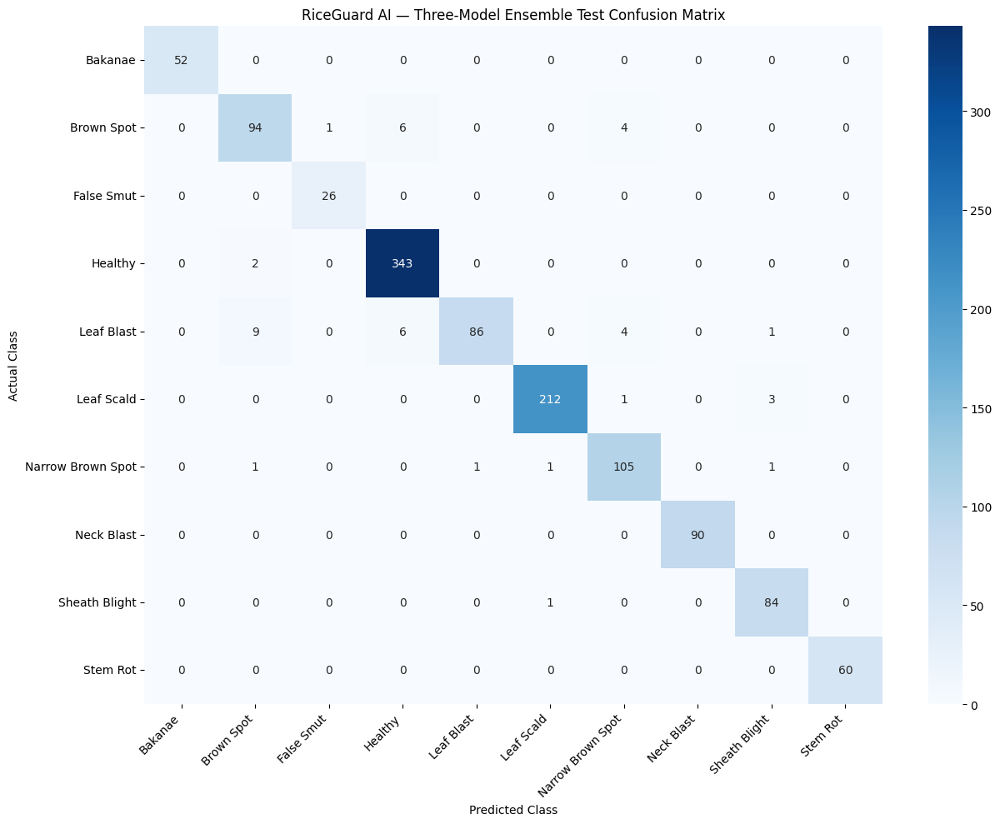


FINAL FILES SAVED
Classification report: /kaggle/working/rice_disease_project/final_test_evaluation/ensemble_test_classification_report.csv
Confusion matrix CSV: /kaggle/working/rice_disease_project/final_test_evaluation/ensemble_test_confusion_matrix.csv
Confusion matrix PNG: /kaggle/working/rice_disease_project/final_test_evaluation/ensemble_test_confusion_matrix.png
Predictions: /kaggle/working/rice_disease_project/final_test_evaluation/ensemble_test_predictions.csv
Final summary: /kaggle/working/rice_disease_project/final_test_evaluation/ensemble_final_test_summary.csv

Test samples evaluated: 1194
Correct predictions: 1152
Incorrect predictions: 42

✅ RICEGUARD AI FINAL TEST EVALUATION COMPLETED


In [11]:
import os
import gc
import numpy as np
import pandas as pd
import torch
import timm
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

MODEL_CONFIGS = {
    "EfficientNetV2-S": {
        "architecture": "efficientnetv2_s",
        "weight": 0.45,
        "checkpoint": os.path.join(
            PROJECT_DIR,
            "efficientnetv2_s_reconstructed",
            "checkpoints",
            "best_efficientnetv2_s_reconstructed.pth"
        )
    },

    "Swin-Tiny": {
        "architecture": "swin_tiny_patch4_window7_224",
        "weight": 0.30,
        "checkpoint": os.path.join(
            PROJECT_DIR,
            "swin_tiny",
            "checkpoints",
            "best_swin_tiny_fresh.pth"
        )
    },

    "ConvNeXt-Tiny": {
        "architecture": "convnext_tiny",
        "weight": 0.25,
        "checkpoint": os.path.join(
            PROJECT_DIR,
            "convnext_tiny_reconstructed",
            "checkpoints",
            "best_convnext_tiny_reconstructed.pth"
        )
    }
}

TEST_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "final_test_evaluation"
)

os.makedirs(TEST_RESULTS_DIR, exist_ok=True)

CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

NUM_CLASSES = len(CLASS_NAMES)

amp_enabled = device.type == "cuda"

# ============================================================
# VALIDATE CHECKPOINTS AND ENSEMBLE WEIGHTS
# ============================================================

total_weight = sum(
    config["weight"]
    for config in MODEL_CONFIGS.values()
)

assert abs(total_weight - 1.0) < 1e-8

for name, config in MODEL_CONFIGS.items():
    assert os.path.isfile(config["checkpoint"]), (
        f"Missing checkpoint for {name}: {config['checkpoint']}"
    )

print("=" * 70)
print("RICEGUARD AI — FINAL TEST EVALUATION")
print("=" * 70)

print("Test samples:", len(test_dataset))
print("Number of classes:", NUM_CLASSES)

print("\nEnsemble configuration:")
for name, config in MODEL_CONFIGS.items():
    print(f"{name}: {config['weight']:.2f}")

# ============================================================
# LOAD MODELS AND GENERATE TEST PROBABILITIES
# ============================================================

model_probabilities = {}
test_labels = None

for model_name, config in MODEL_CONFIGS.items():

    print(f"\nLoading {model_name}...")

    model = timm.create_model(
        config["architecture"],
        pretrained=False,
        num_classes=NUM_CLASSES
    )

    checkpoint = torch.load(
        config["checkpoint"],
        map_location="cpu",
        weights_only=False
    )

    state_dict = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint)
    )

    model.load_state_dict(state_dict, strict=True)

    model = model.to(device)
    model.eval()

    probabilities = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(
            test_loader,
            desc=f"{model_name} test evaluation"
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type=device.type,
                enabled=amp_enabled
            ):
                outputs = model(images)

            probs = torch.softmax(
                outputs.float(),
                dim=1
            )

            probabilities.append(
                probs.cpu().numpy()
            )

            labels_list.append(
                labels.numpy()
            )

    probabilities = np.concatenate(
        probabilities,
        axis=0
    )

    labels_array = np.concatenate(
        labels_list,
        axis=0
    )

    if test_labels is None:
        test_labels = labels_array
    else:
        assert np.array_equal(
            test_labels,
            labels_array
        ), "Test label order mismatch!"

    model_probabilities[model_name] = probabilities

    individual_predictions = probabilities.argmax(axis=1)

    individual_accuracy = accuracy_score(
        test_labels,
        individual_predictions
    )

    individual_f1 = f1_score(
        test_labels,
        individual_predictions,
        average="macro",
        zero_division=0
    )

    print(f"\n{model_name} Test Accuracy: {individual_accuracy * 100:.2f}%")
    print(f"{model_name} Test Macro-F1: {individual_f1 * 100:.2f}%")

    del model, checkpoint, state_dict

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ============================================================
# WEIGHTED SOFT-VOTING ENSEMBLE
# ============================================================

ensemble_probabilities = np.zeros_like(
    model_probabilities["EfficientNetV2-S"],
    dtype=np.float64
)

for model_name, config in MODEL_CONFIGS.items():

    ensemble_probabilities += (
        config["weight"]
        * model_probabilities[model_name]
    )

ensemble_predictions = ensemble_probabilities.argmax(
    axis=1
)

# ============================================================
# FINAL METRICS
# ============================================================

accuracy = accuracy_score(
    test_labels,
    ensemble_predictions
)

precision_macro = precision_score(
    test_labels,
    ensemble_predictions,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    test_labels,
    ensemble_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    test_labels,
    ensemble_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    test_labels,
    ensemble_predictions,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 70)
print("FINAL ENSEMBLE TEST RESULTS")
print("=" * 70)

print(f"Test Accuracy:       {accuracy * 100:.2f}%")
print(f"Macro Precision:     {precision_macro * 100:.2f}%")
print(f"Macro Recall:        {recall_macro * 100:.2f}%")
print(f"Macro F1-Score:      {macro_f1 * 100:.2f}%")
print(f"Weighted F1-Score:   {weighted_f1 * 100:.2f}%")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

report_dict = classification_report(
    test_labels,
    ensemble_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_path = os.path.join(
    TEST_RESULTS_DIR,
    "ensemble_test_classification_report.csv"
)

report_df.to_csv(report_path)

print("\nCLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        test_labels,
        ensemble_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    ensemble_predictions,
    labels=list(range(NUM_CLASSES))
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_path = os.path.join(
    TEST_RESULTS_DIR,
    "ensemble_test_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title(
    "RiceGuard AI — Three-Model Ensemble Test Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

confusion_plot_path = os.path.join(
    TEST_RESULTS_DIR,
    "ensemble_test_confusion_matrix.png"
)

plt.savefig(
    confusion_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# SAVE PREDICTIONS
# ============================================================

prediction_df = test_df.copy()

prediction_df["actual_label"] = [
    CLASS_NAMES[index]
    for index in test_labels
]

prediction_df["predicted_label"] = [
    CLASS_NAMES[index]
    for index in ensemble_predictions
]

prediction_df["correct"] = (
    prediction_df["actual_label"]
    == prediction_df["predicted_label"]
)

for index, class_name in enumerate(CLASS_NAMES):

    prediction_df[
        f"probability_{class_name.replace(' ', '_')}"
    ] = ensemble_probabilities[:, index]

predictions_path = os.path.join(
    TEST_RESULTS_DIR,
    "ensemble_test_predictions.csv"
)

prediction_df.to_csv(
    predictions_path,
    index=False
)

# ============================================================
# SAVE FINAL SUMMARY
# ============================================================

summary = pd.DataFrame([{
    "model": "Three-Model Weighted Soft Voting",
    "efficientnet_weight": 0.45,
    "swin_weight": 0.30,
    "convnext_weight": 0.25,
    "test_samples": len(test_labels),
    "test_accuracy": accuracy,
    "macro_precision": precision_macro,
    "macro_recall": recall_macro,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1
}])

summary_path = os.path.join(
    TEST_RESULTS_DIR,
    "ensemble_final_test_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 70)
print("FINAL FILES SAVED")
print("=" * 70)

print("Classification report:", report_path)
print("Confusion matrix CSV:", cm_path)
print("Confusion matrix PNG:", confusion_plot_path)
print("Predictions:", predictions_path)
print("Final summary:", summary_path)

print("\nTest samples evaluated:", len(test_labels))
print("Correct predictions:", int((test_labels == ensemble_predictions).sum()))
print("Incorrect predictions:", int((test_labels != ensemble_predictions).sum()))

print("\n✅ RICEGUARD AI FINAL TEST EVALUATION COMPLETED")

RICEGUARD AI — ERROR ANALYSIS
Total test images: 1194
Correct predictions: 1152
Incorrect predictions: 42
Error rate: 3.52%

1. CLASS-WISE ERROR SUMMARY


,total_images,correct_predictions,incorrect_predictions,accuracy,error_rate
actual_label,,,,,
Leaf Blast,106,86,20,81.13%,18.87%
Brown Spot,105,94,11,89.52%,10.48%
Narrow Brown Spot,109,105,4,96.33%,3.67%
Leaf Scald,216,212,4,98.15%,1.85%
Sheath Blight,85,84,1,98.82%,1.18%
Healthy,345,343,2,99.42%,0.58%
Bakanae,52,52,0,100.00%,0.00%
False Smut,26,26,0,100.00%,0.00%
Neck Blast,90,90,0,100.00%,0.00%



2. MOST COMMON MISCLASSIFICATIONS


,actual_label,predicted_label,error_count
4,Leaf Blast,Brown Spot,9
5,Leaf Blast,Healthy,6
1,Brown Spot,Healthy,6
6,Leaf Blast,Narrow Brown Spot,4
2,Brown Spot,Narrow Brown Spot,4
9,Leaf Scald,Sheath Blight,3
3,Healthy,Brown Spot,2
0,Brown Spot,False Smut,1
7,Leaf Blast,Sheath Blight,1
8,Leaf Scald,Narrow Brown Spot,1


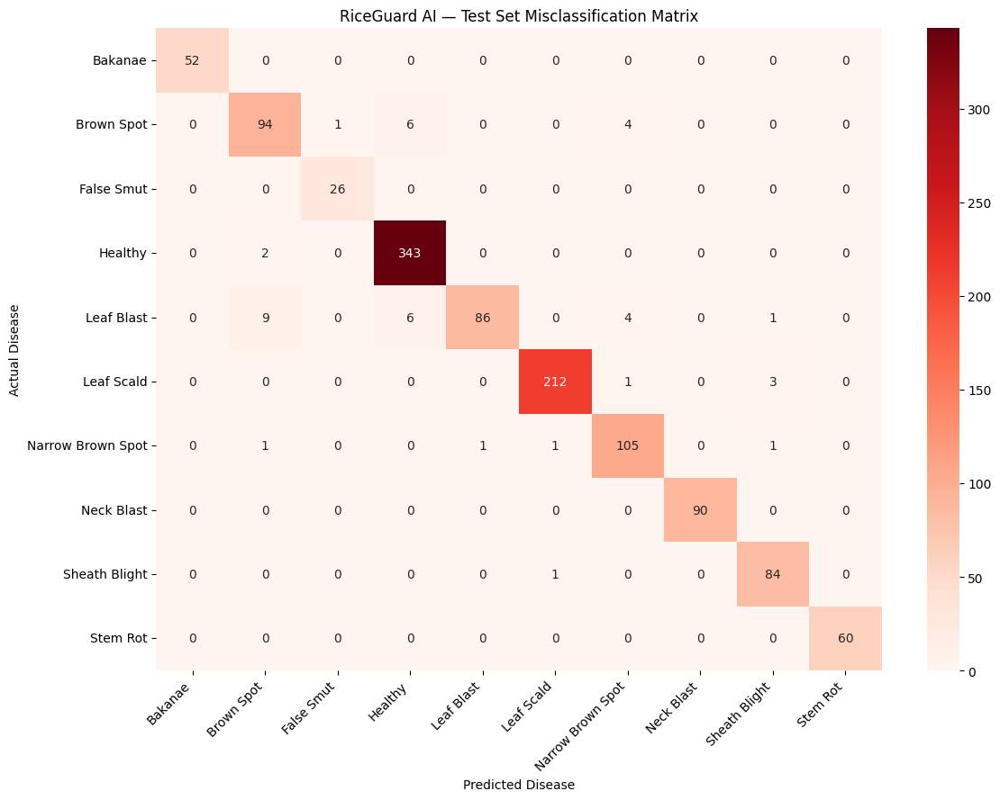


4. PRIORITY DISEASE ERRORS
Leaf Blast / Brown Spot / Narrow Brown Spot errors: 35


,path,actual_label,predicted_label
101,/kaggle/input/datasets/sirichandanakota/rice-c...,Narrow Brown Spot,Leaf Scald
214,/kaggle/input/datasets/sirichandanakota/rice-c...,Leaf Blast,Brown Spot
252,/kaggle/input/datasets/sirichandanakota/rice-c...,Leaf Blast,Brown Spot
274,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,Healthy
275,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,Healthy
290,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,Healthy
303,/kaggle/input/datasets/sirichandanakota/rice-c...,Leaf Blast,Brown Spot
350,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,Narrow Brown Spot
416,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,False Smut
469,/kaggle/input/datasets/sirichandanakota/rice-c...,Brown Spot,Narrow Brown Spot



5. MISCLASSIFIED LEAF BLAST IMAGES


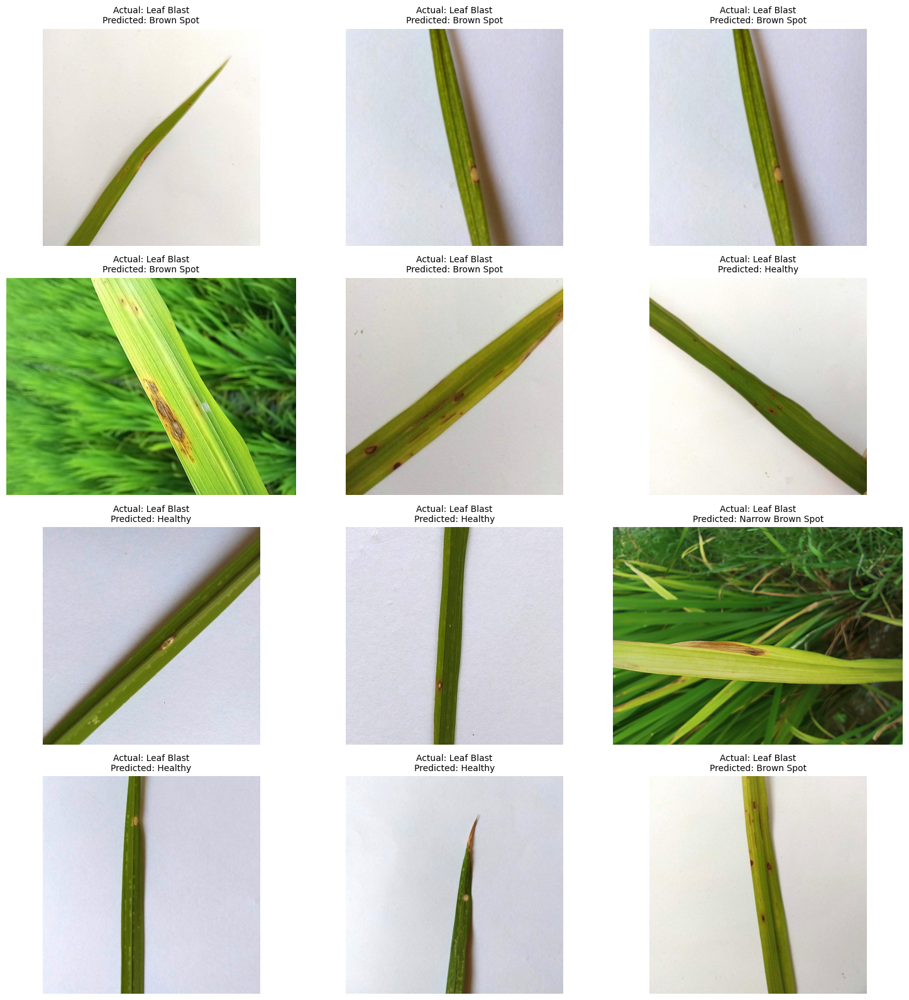


MISCLASSIFIED BROWN SPOT IMAGES


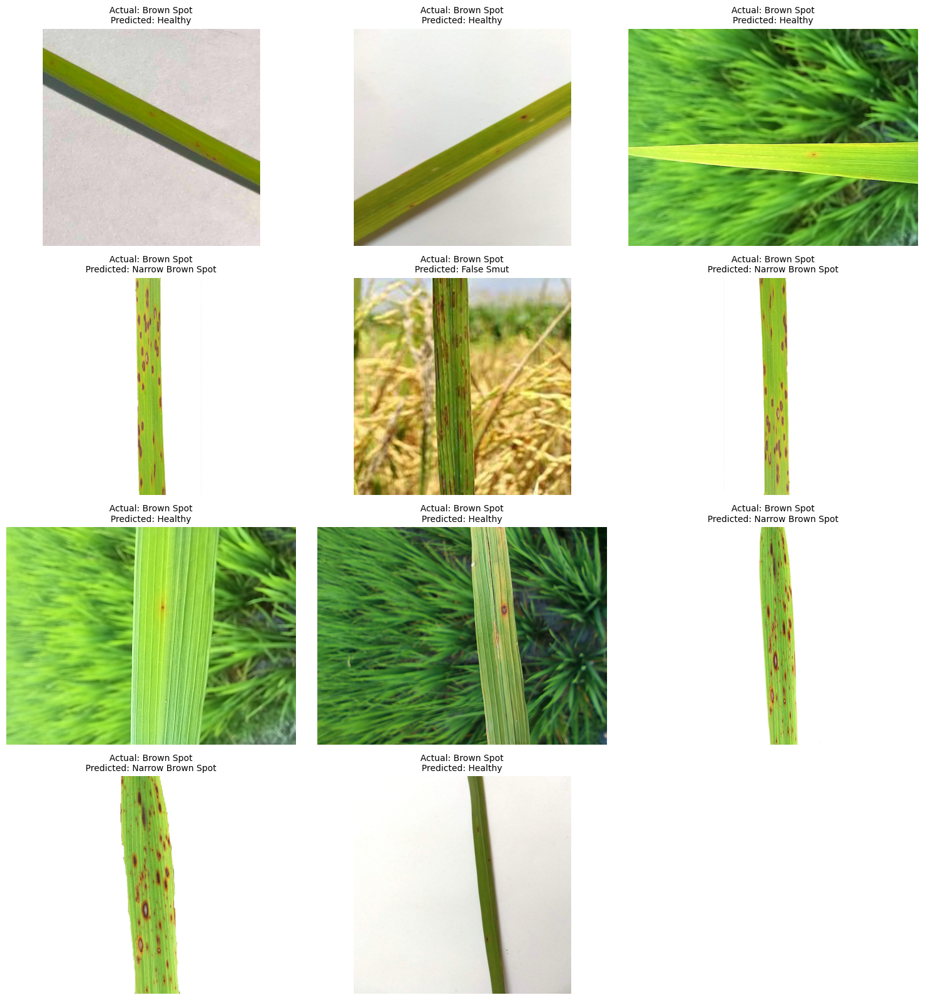


ERROR ANALYSIS COMPLETED
Saved files:
- class_wise_error_analysis.csv
- misclassification_pairs.csv
- priority_disease_errors.csv
- all_misclassified_images.csv
- error_analysis_confusion_matrix.png

✅ ERROR ANALYSIS COMPLETED


In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from IPython.display import display

# ============================================================
# LOAD FINAL TEST PREDICTIONS
# ============================================================

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "final_test_evaluation"
)

PREDICTIONS_PATH = os.path.join(
    RESULTS_DIR,
    "ensemble_test_predictions.csv"
)

df = pd.read_csv(PREDICTIONS_PATH)

errors = df[df["correct"] == False].copy()

print("=" * 70)
print("RICEGUARD AI — ERROR ANALYSIS")
print("=" * 70)

print("Total test images:", len(df))
print("Correct predictions:", df["correct"].sum())
print("Incorrect predictions:", len(errors))
print(f"Error rate: {len(errors) / len(df) * 100:.2f}%")

# ============================================================
# 1. CLASS-WISE PERFORMANCE
# ============================================================

class_performance = (
    df.groupby("actual_label")
    .agg(
        total_images=("correct", "count"),
        correct_predictions=("correct", "sum")
    )
)

class_performance["incorrect_predictions"] = (
    class_performance["total_images"]
    - class_performance["correct_predictions"]
)

class_performance["accuracy"] = (
    class_performance["correct_predictions"]
    / class_performance["total_images"]
)

class_performance["error_rate"] = (
    class_performance["incorrect_predictions"]
    / class_performance["total_images"]
)

class_performance = class_performance.sort_values(
    "error_rate",
    ascending=False
)

print("\n1. CLASS-WISE ERROR SUMMARY")
display(
    class_performance.style.format({
        "accuracy": "{:.2%}",
        "error_rate": "{:.2%}"
    })
)

class_performance.to_csv(
    os.path.join(RESULTS_DIR, "class_wise_error_analysis.csv")
)

# ============================================================
# 2. MOST COMMON CLASSIFICATION ERRORS
# ============================================================

confusion_pairs = (
    errors.groupby(["actual_label", "predicted_label"])
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

print("\n2. MOST COMMON MISCLASSIFICATIONS")
display(confusion_pairs)

confusion_pairs.to_csv(
    os.path.join(RESULTS_DIR, "misclassification_pairs.csv"),
    index=False
)

# ============================================================
# 3. VISUALIZE CONFUSION PATTERNS
# ============================================================

class_names = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

confusion = pd.crosstab(
    df["actual_label"],
    df["predicted_label"]
).reindex(
    index=class_names,
    columns=class_names,
    fill_value=0
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title("RiceGuard AI — Test Set Misclassification Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "error_analysis_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 4. LEAF BLAST AND BROWN SPOT ERRORS
# ============================================================

priority_errors = errors[
    errors["actual_label"].isin([
        "Leaf Blast",
        "Brown Spot",
        "Narrow Brown Spot"
    ])
].copy()

print("\n4. PRIORITY DISEASE ERRORS")
print("Leaf Blast / Brown Spot / Narrow Brown Spot errors:",
      len(priority_errors))

display(
    priority_errors[
        ["path", "actual_label", "predicted_label"]
    ].head(30)
)

priority_errors.to_csv(
    os.path.join(RESULTS_DIR, "priority_disease_errors.csv"),
    index=False
)

# ============================================================
# 5. DISPLAY MISCLASSIFIED IMAGES
# ============================================================

def show_misclassified_images(dataframe, max_images=12):

    sample = dataframe.head(max_images)

    if len(sample) == 0:
        print("No misclassified images in this selection.")
        return

    columns = 3
    rows = int(np.ceil(len(sample) / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(15, rows * 4)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, sample.iterrows()):

        try:
            image = Image.open(row["path"]).convert("RGB")

            ax.imshow(image)

            ax.set_title(
                f"Actual: {row['actual_label']}\n"
                f"Predicted: {row['predicted_label']}",
                fontsize=10
            )

            ax.axis("off")

        except Exception as e:
            ax.set_title(f"Image loading error: {e}")

    plt.tight_layout()
    plt.show()


print("\n5. MISCLASSIFIED LEAF BLAST IMAGES")
show_misclassified_images(
    errors[errors["actual_label"] == "Leaf Blast"],
    max_images=12
)

print("\nMISCLASSIFIED BROWN SPOT IMAGES")
show_misclassified_images(
    errors[errors["actual_label"] == "Brown Spot"],
    max_images=12
)

# ============================================================
# 6. SAVE COMPLETE ERROR ANALYSIS
# ============================================================

errors.to_csv(
    os.path.join(RESULTS_DIR, "all_misclassified_images.csv"),
    index=False
)

print("\n" + "=" * 70)
print("ERROR ANALYSIS COMPLETED")
print("=" * 70)

print("Saved files:")
print("- class_wise_error_analysis.csv")
print("- misclassification_pairs.csv")
print("- priority_disease_errors.csv")
print("- all_misclassified_images.csv")
print("- error_analysis_confusion_matrix.png")

print("\n✅ ERROR ANALYSIS COMPLETED")

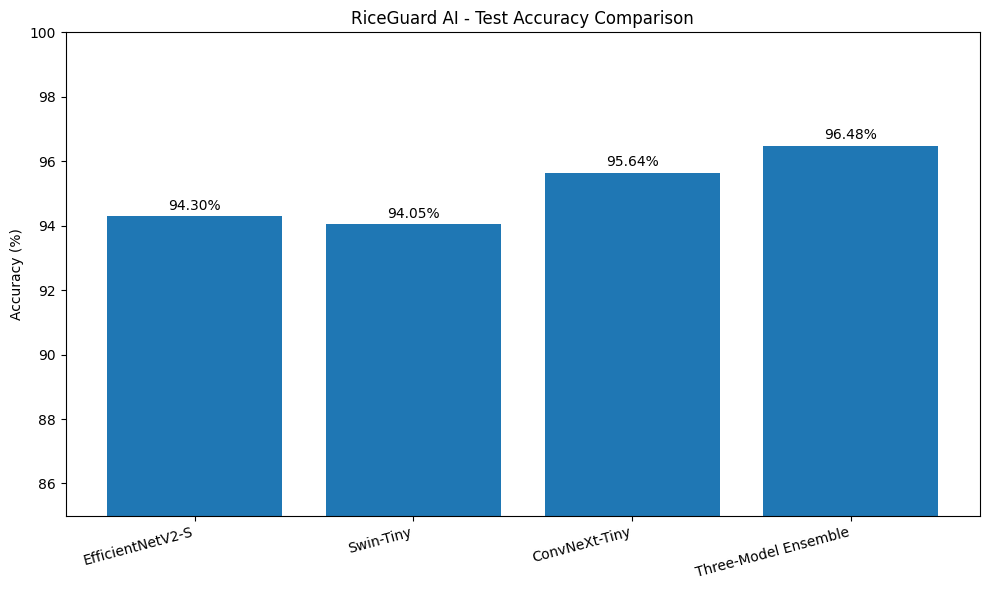

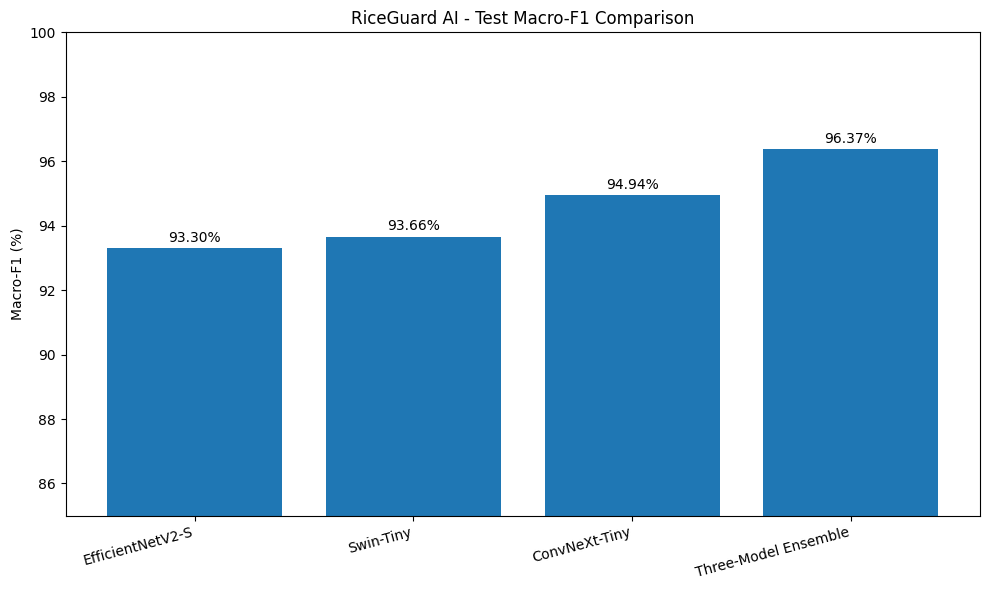

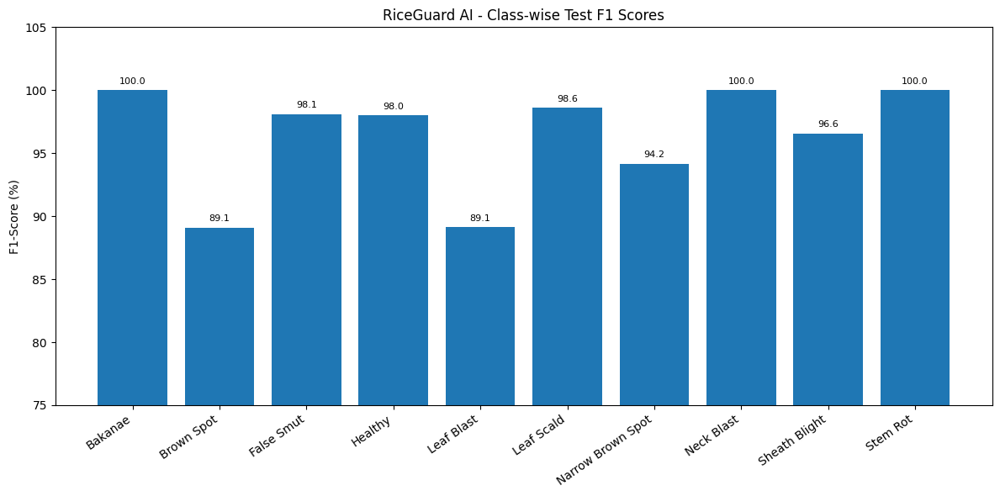

RICEGUARD AI - FINAL MODEL COMPARISON


,Model,Accuracy,Macro-F1
0,EfficientNetV2-S,94.30,93.30
1,Swin-Tiny,94.05,93.66
2,ConvNeXt-Tiny,95.64,94.94
3,Three-Model Ensemble,96.48,96.37



Saved:
1. final_model_comparison.csv
2. test_accuracy_comparison.png
3. test_macro_f1_comparison.png
4. classwise_f1_comparison.png

✅ PERFORMANCE VISUALIZATION COMPLETED


In [13]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "final_test_evaluation"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# Test metrics from completed evaluations
comparison = pd.DataFrame({
    "Model": [
        "EfficientNetV2-S",
        "Swin-Tiny",
        "ConvNeXt-Tiny",
        "Three-Model Ensemble"
    ],
    "Accuracy": [
        94.30, 94.05, 95.64, 96.48
    ],
    "Macro-F1": [
        93.30, 93.66, 94.94, 96.37
    ]
})

comparison.to_csv(
    os.path.join(RESULTS_DIR, "final_model_comparison.csv"),
    index=False
)

# ------------------------------------------------
# CHART 1: TEST ACCURACY
# ------------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("RiceGuard AI - Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(85, 100)
plt.xticks(rotation=15, ha="right")

for bar, value in zip(bars, comparison["Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "test_accuracy_comparison.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------
# CHART 2: MACRO-F1 COMPARISON
# ------------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison["Model"],
    comparison["Macro-F1"]
)

plt.title("RiceGuard AI - Test Macro-F1 Comparison")
plt.ylabel("Macro-F1 (%)")
plt.ylim(85, 100)
plt.xticks(rotation=15, ha="right")

for bar, value in zip(bars, comparison["Macro-F1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "test_macro_f1_comparison.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------
# CHART 3: CLASS-WISE F1 SCORE
# ------------------------------------------------

report_path = os.path.join(
    RESULTS_DIR,
    "ensemble_test_classification_report.csv"
)

report = pd.read_csv(report_path, index_col=0)

class_report = report.loc[
    CLASS_NAMES
].copy()

class_report["f1-score"] *= 100

plt.figure(figsize=(12, 6))

bars = plt.bar(
    class_report.index,
    class_report["f1-score"]
)

plt.title("RiceGuard AI - Class-wise Test F1 Scores")
plt.ylabel("F1-Score (%)")
plt.ylim(75, 105)
plt.xticks(rotation=35, ha="right")

for bar, value in zip(bars, class_report["f1-score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.1f}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "classwise_f1_comparison.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------

print("=" * 60)
print("RICEGUARD AI - FINAL MODEL COMPARISON")
print("=" * 60)

display(comparison)

print("\nSaved:")
print("1. final_model_comparison.csv")
print("2. test_accuracy_comparison.png")
print("3. test_macro_f1_comparison.png")
print("4. classwise_f1_comparison.png")

print("\n✅ PERFORMANCE VISUALIZATION COMPLETED")

In [14]:
import os
import json
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

# ============================================================
# CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/kaggle/working/rice_disease_project"
)

BACKUP_DIR = Path(
    "/kaggle/working"
)

ZIP_PATH = BACKUP_DIR / "RiceGuard_AI_Final_Backup.zip"

assert PROJECT_DIR.exists(), "Project directory not found!"

# ============================================================
# CREATE PROJECT SUMMARY
# ============================================================

project_summary = {
    "project_name": "RiceGuard AI",
    "description": "Rice fungal disease classification using deep learning",
    "classes": [
        "Bakanae",
        "Brown Spot",
        "False Smut",
        "Healthy",
        "Leaf Blast",
        "Leaf Scald",
        "Narrow Brown Spot",
        "Neck Blast",
        "Sheath Blight",
        "Stem Rot"
    ],
    "dataset": {
        "unique_images": 7955,
        "training_images": 5568,
        "validation_images": 1193,
        "test_images": 1194
    },
    "models": {
        "EfficientNetV2-S": {
            "test_accuracy": 94.30,
            "test_macro_f1": 93.30
        },
        "Swin-Tiny": {
            "test_accuracy": 94.05,
            "test_macro_f1": 93.66
        },
        "ConvNeXt-Tiny": {
            "test_accuracy": 95.64,
            "test_macro_f1": 94.94
        },
        "Three-Model Ensemble": {
            "weights": {
                "EfficientNetV2-S": 0.45,
                "Swin-Tiny": 0.30,
                "ConvNeXt-Tiny": 0.25
            },
            "test_accuracy": 96.48,
            "test_macro_precision": 96.60,
            "test_macro_recall": 96.34,
            "test_macro_f1": 96.37,
            "test_weighted_f1": 96.43,
            "correct_predictions": 1152,
            "incorrect_predictions": 42
        }
    },
    "backup_created": datetime.now().isoformat()
}

summary_path = PROJECT_DIR / "RICEGUARD_PROJECT_SUMMARY.json"

with open(summary_path, "w") as f:
    json.dump(project_summary, f, indent=4)

# ============================================================
# CREATE ZIP BACKUP
# ============================================================

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

print("=" * 65)
print("CREATING RICEGUARD AI FINAL BACKUP")
print("=" * 65)

file_count = 0
total_size = 0

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=4
) as archive:

    for file_path in PROJECT_DIR.rglob("*"):

        if not file_path.is_file():
            continue

        relative_path = file_path.relative_to(
            PROJECT_DIR.parent
        )

        archive.write(
            file_path,
            arcname=str(relative_path)
        )

        file_count += 1
        total_size += file_path.stat().st_size

        print("Added:", relative_path)

# ============================================================
# VERIFY ZIP INTEGRITY
# ============================================================

print("\n" + "=" * 65)
print("VERIFYING BACKUP")
print("=" * 65)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity failed: {bad_file}"
        )

    archived_files = archive.namelist()

print("ZIP integrity: PASSED")
print("Files archived:", file_count)
print(f"Original size: {total_size / (1024**3):.2f} GB")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**3):.2f} GB")

print("\nBackup location:")
print(ZIP_PATH)

print("\n" + "=" * 65)
print("✅ RICEGUARD AI BACKUP CREATED SUCCESSFULLY")
print("=" * 65)

CREATING RICEGUARD AI FINAL BACKUP
Added: rice_disease_project/RICEGUARD_PROJECT_SUMMARY.json
Added: rice_disease_project/dataset_split_manifest.csv
Added: rice_disease_project/unique_image_inventory.csv
Added: rice_disease_project/final_test_evaluation/error_analysis_confusion_matrix.png
Added: rice_disease_project/final_test_evaluation/ensemble_test_predictions.csv
Added: rice_disease_project/final_test_evaluation/ensemble_test_confusion_matrix.png
Added: rice_disease_project/final_test_evaluation/classwise_f1_comparison.png
Added: rice_disease_project/final_test_evaluation/all_misclassified_images.csv
Added: rice_disease_project/final_test_evaluation/ensemble_final_test_summary.csv
Added: rice_disease_project/final_test_evaluation/class_wise_error_analysis.csv
Added: rice_disease_project/final_test_evaluation/priority_disease_errors.csv
Added: rice_disease_project/final_test_evaluation/final_model_comparison.csv
Added: rice_disease_project/final_test_evaluation/test_macro_f1_compari

In [15]:
import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 20

BACKBONE_LR = 1e-5
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

DROPOUT = 0.35
NUM_CLASSES = len(CLASS_NAMES)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "hybrid_experiments",
    "efficientnet_convnext_fusion"
)

CHECKPOINT_DIR = os.path.join(
    MODEL_DIR, "checkpoints"
)

RESULTS_DIR = os.path.join(
    MODEL_DIR, "results"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "best_efficientnet_convnext_fusion.pth"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "efficientnet_convnext_fusion_history.csv"
)

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

amp_enabled = device.type == "cuda"

# ============================================================
# 2. CHECKPOINT PATHS
# ============================================================

EFFICIENTNET_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "efficientnetv2_s_reconstructed",
    "checkpoints",
    "best_efficientnetv2_s_reconstructed.pth"
)

CONVNEXT_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "convnext_tiny_reconstructed",
    "checkpoints",
    "best_convnext_tiny_reconstructed.pth"
)

assert os.path.isfile(EFFICIENTNET_CHECKPOINT)
assert os.path.isfile(CONVNEXT_CHECKPOINT)

# ============================================================
# 3. LOAD TRAINED BACKBONES
# ============================================================

print("=" * 70)
print("LOADING TRAINED BACKBONES")
print("=" * 70)

efficientnet = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=NUM_CLASSES
)

convnext = timm.create_model(
    "convnext_tiny",
    pretrained=False,
    num_classes=NUM_CLASSES
)

eff_checkpoint = torch.load(
    EFFICIENTNET_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

conv_checkpoint = torch.load(
    CONVNEXT_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

efficientnet.load_state_dict(
    eff_checkpoint["model_state_dict"],
    strict=True
)

convnext.load_state_dict(
    conv_checkpoint["model_state_dict"],
    strict=True
)

del eff_checkpoint, conv_checkpoint
gc.collect()

print("EfficientNetV2-S checkpoint loaded.")
print("ConvNeXt-Tiny checkpoint loaded.")

# ============================================================
# 4. FEATURE FUSION ARCHITECTURE
# ============================================================

class RiceFeatureFusion(nn.Module):

    def __init__(
        self,
        efficientnet,
        convnext,
        num_classes=10,
        dropout=0.35
    ):
        super().__init__()

        self.efficientnet = efficientnet
        self.convnext = convnext

        efficientnet_features = efficientnet.num_features
        convnext_features = convnext.num_features

        fusion_features = (
            efficientnet_features + convnext_features
        )

        self.fusion_head = nn.Sequential(

            nn.LayerNorm(fusion_features),

            nn.Linear(
                fusion_features,
                1024
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                1024,
                512
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                512,
                num_classes
            )
        )

    def forward(self, images):

        # EfficientNet feature extraction
        efficient_features = (
            self.efficientnet.forward_head(
                self.efficientnet.forward_features(images),
                pre_logits=True
            )
        )

        # ConvNeXt feature extraction
        convnext_features = (
            self.convnext.forward_head(
                self.convnext.forward_features(images),
                pre_logits=True
            )
        )

        # Feature concatenation
        fused_features = torch.cat(
            [
                efficient_features,
                convnext_features
            ],
            dim=1
        )

        # Final classification
        outputs = self.fusion_head(fused_features)

        return outputs


model = RiceFeatureFusion(
    efficientnet=efficientnet,
    convnext=convnext,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)

print("\nFusion architecture:")
print("EfficientNet features:", efficientnet.num_features)
print("ConvNeXt features:", convnext.num_features)
print(
    "Combined features:",
    efficientnet.num_features + convnext.num_features
)

# ============================================================
# 5. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.efficientnet.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.convnext.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.fusion_head.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# ============================================================
# 6. TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, loader):

    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ============================================================
# 7. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate_one_epoch(model, loader):

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ============================================================
# 8. TRAIN FOR ALL 20 EPOCHS
# ============================================================

history = []

best_val_f1 = -1.0
best_epoch = 0

print("\n" + "=" * 70)
print("RICEGUARD AI — EFFICIENTNET + CONVNEXT FEATURE FUSION")
print("=" * 70)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Device:", device)

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    print(f"\n{'=' * 65}")
    print(f"EPOCH {epoch}/{EPOCHS}")
    print("=" * 65)

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc, val_f1 = validate_one_epoch(
        model,
        val_loader
    )

    scheduler.step()

    epoch_time = time.time() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "backbone_learning_rate": optimizer.param_groups[0]["lr"],
        "head_learning_rate": optimizer.param_groups[2]["lr"],
        "epoch_time_seconds": epoch_time
    }

    history.append(record)

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    # Save best model using validation Macro-F1
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_name": "efficientnetv2_s_convnext_tiny_feature_fusion",
                "model_state_dict": model.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "best_val_accuracy": val_acc,
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "seed": SEED,
                "efficientnet_checkpoint": EFFICIENTNET_CHECKPOINT,
                "convnext_checkpoint": CONVNEXT_CHECKPOINT
            },
            BEST_CHECKPOINT
        )

        print("\n🏆 BEST FUSION CHECKPOINT UPDATED")

    print(f"\nTrain Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Train Macro-F1: {train_f1 * 100:.2f}%")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc * 100:.2f}%")
    print(f"Validation Macro-F1: {val_f1 * 100:.2f}%")

    print(f"Epoch Time: {epoch_time / 60:.2f} minutes")

# ============================================================
# 9. FINAL TRAINING SUMMARY
# ============================================================

total_time = (time.time() - training_start) / 60

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

best_row = history_df.loc[
    history_df["val_macro_f1"].idxmax()
]

print("\n" + "=" * 70)
print("FEATURE FUSION TRAINING COMPLETED")
print("=" * 70)

print("Completed epochs:", len(history_df))
print("Best epoch:", best_epoch)

print(
    f"Best validation accuracy: "
    f"{best_row['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best validation Macro-F1: "
    f"{best_row['val_macro_f1'] * 100:.2f}%"
)

print(f"Total training time: {total_time:.2f} minutes")

print("\nBest checkpoint:", BEST_CHECKPOINT)
print("Training history:", HISTORY_PATH)

assert len(history_df) == EPOCHS
assert os.path.isfile(BEST_CHECKPOINT)

print("\n✅ EXPERIMENT 4 TRAINING COMPLETED")

LOADING TRAINED BACKBONES
EfficientNetV2-S checkpoint loaded.
ConvNeXt-Tiny checkpoint loaded.

Fusion architecture:
EfficientNet features: 1280
ConvNeXt features: 768
Combined features: 2048

RICEGUARD AI — EFFICIENTNET + CONVNEXT FEATURE FUSION
Training samples: 5568
Validation samples: 1193
Epochs: 20
Batch size: 16
Device: cuda:0

EPOCH 1/20


Training:   0%|          | 0/348 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]


🏆 BEST FUSION CHECKPOINT UPDATED

Train Loss: 0.6488
Train Accuracy: 95.37%
Train Macro-F1: 94.54%
Validation Loss: 0.6415
Validation Accuracy: 94.47%
Validation Macro-F1: 93.28%
Epoch Time: 2.95 minutes

EPOCH 2/20


Training:   0%|          | 0/348 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

... (65 outputs left out)

Training:   0%|          | 0/348 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ee29dba42c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Train Loss: 0.5298
Train Accuracy: 99.10%
Train Macro-F1: 99.14%
Validation Loss: 0.5784
Validation Accuracy: 96.65%
Validation Macro-F1: 96.07%
Epoch Time: 2.73 minutes

FEATURE FUSION TRAINING COMPLETED
Completed epochs: 20
Best epoch: 16
Best validation accuracy: 97.07%
Best validation Macro-F1: 96.49%
Total training time: 56.17 minutes

Best checkpoint: /kaggle/working/rice_disease_project/hybrid_experiments/efficientnet_convnext_fusion/checkpoints/best_efficientnet_convnext_fusion.pth
Training history: /kaggle/working/rice_disease_project/hybrid_experiments/efficientnet_convnext_fusion/results/efficientnet_convnext_fusion_history.csv

✅ EXPERIMENT 4 TRAINING COMPLETED


In [1]:
import os
import gc
import torch
import timm
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. PATHS
# ============================================================

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "hybrid_experiments",
    "efficientnet_convnext_fusion"
)

CHECKPOINT_PATH = os.path.join(
    MODEL_DIR,
    "checkpoints",
    "best_efficientnet_convnext_fusion.pth"
)

RESULTS_DIR = os.path.join(
    MODEL_DIR,
    "results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

assert os.path.isfile(CHECKPOINT_PATH), "Checkpoint missing!"

# ============================================================
# 2. RECREATE MODEL ARCHITECTURE
# ============================================================

class RiceFeatureFusion(torch.nn.Module):

    def __init__(
        self,
        efficientnet,
        convnext,
        num_classes=10,
        dropout=0.35
    ):
        super().__init__()

        self.efficientnet = efficientnet
        self.convnext = convnext

        fusion_features = (
            efficientnet.num_features +
            convnext.num_features
        )

        self.fusion_head = torch.nn.Sequential(
            torch.nn.LayerNorm(fusion_features),
            torch.nn.Linear(fusion_features, 1024),
            torch.nn.GELU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(1024, 512),
            torch.nn.GELU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(512, num_classes)
        )

    def forward(self, images):

        efficient_features = self.efficientnet.forward_head(
            self.efficientnet.forward_features(images),
            pre_logits=True
        )

        convnext_features = self.convnext.forward_head(
            self.convnext.forward_features(images),
            pre_logits=True
        )

        fused_features = torch.cat(
            [efficient_features, convnext_features],
            dim=1
        )

        return self.fusion_head(fused_features)


# ============================================================
# 3. LOAD BEST CHECKPOINT
# ============================================================

efficientnet = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=NUM_CLASSES
)

convnext = timm.create_model(
    "convnext_tiny",
    pretrained=False,
    num_classes=NUM_CLASSES
)

model = RiceFeatureFusion(
    efficientnet,
    convnext,
    num_classes=NUM_CLASSES
).to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

print("Loaded best epoch:", checkpoint["epoch"])
print(
    "Best validation Macro-F1:",
    round(checkpoint["best_val_macro_f1"] * 100, 2),
    "%"
)

# ============================================================
# 4. TEST INFERENCE
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Testing feature fusion"
    ):

        images = images.to(device)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

# ============================================================
# 5. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 65)
print("EXPERIMENT 4 — TEST RESULTS")
print("=" * 65)

print(f"Test samples: {len(y_true)}")
print(f"Correct predictions: {(y_true == y_pred).sum()}")
print(f"Incorrect predictions: {(y_true != y_pred).sum()}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall: {recall * 100:.2f}%")
print(f"Macro-F1: {macro_f1 * 100:.2f}%")
print(f"Weighted F1: {weighted_f1 * 100:.2f}%")

# ============================================================
# 6. CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_convnext_fusion_test_report.csv"
)

report_df.to_csv(report_path)

print("\nCLASS-WISE PERFORMANCE")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

# ============================================================
# 7. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_convnext_fusion_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

# ============================================================
# 8. SAVE PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({
    "actual_class": [CLASS_NAMES[i] for i in y_true],
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
    "correct": y_true == y_pred,
    "confidence": y_prob.max(axis=1)
})

predictions_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_convnext_fusion_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

# ============================================================
# 9. SAVE SUMMARY
# ============================================================

summary = pd.DataFrame([{
    "model": "EfficientNetV2-S + ConvNeXt-Tiny Feature Fusion",
    "best_epoch": checkpoint["epoch"],
    "test_samples": len(y_true),
    "correct": int((y_true == y_pred).sum()),
    "incorrect": int((y_true != y_pred).sum()),
    "test_accuracy": accuracy,
    "macro_precision": precision,
    "macro_recall": recall,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1
}])

summary_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_convnext_fusion_test_summary.csv"
)

summary.to_csv(summary_path, index=False)

print("\nSaved evaluation files:")
print(report_path)
print(cm_path)
print(predictions_path)
print(summary_path)

print("\n✅ EXPERIMENT 4 TEST EVALUATION COMPLETED")

del model, efficientnet, convnext
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

NameError: name 'PROJECT_DIR' is not defined

In [2]:
import os

# Restore project directory
PROJECT_DIR = "/kaggle/working/rice_disease_project"

# Restore device
import torch

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Restore class configuration
CLASS_NAMES = [
    "Bakanae",
    "Brown Spot",
    "False Smut",
    "Healthy",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Spot",
    "Neck Blast",
    "Sheath Blight",
    "Stem Rot"
]

NUM_CLASSES = len(CLASS_NAMES)

# Experiment 4 checkpoint
CHECKPOINT_PATH = os.path.join(
    PROJECT_DIR,
    "hybrid_experiments",
    "efficientnet_convnext_fusion",
    "checkpoints",
    "best_efficientnet_convnext_fusion.pth"
)

print("PROJECT_DIR:", PROJECT_DIR)
print("Device:", device)
print("Number of classes:", NUM_CLASSES)
print("Project exists:", os.path.isdir(PROJECT_DIR))
print("Experiment 4 checkpoint exists:", os.path.isfile(CHECKPOINT_PATH))

if os.path.isfile(CHECKPOINT_PATH):
    print("\n✅ Experiment 4 checkpoint found.")
else:
    print("\n❌ Checkpoint not found. Do not start test evaluation.")
    print("Check whether the project backup was restored.")

PROJECT_DIR: /kaggle/working/rice_disease_project
Device: cuda:0
Number of classes: 10
Project exists: False
Experiment 4 checkpoint exists: False

❌ Checkpoint not found. Do not start test evaluation.
Check whether the project backup was restored.


In [1]:
import os

print("=" * 65)
print("SEARCHING KAGGLE INPUT AND WORKING DIRECTORIES")
print("=" * 65)

for root in ["/kaggle/input", "/kaggle/working"]:

    print(f"\n📁 {root}")

    if not os.path.exists(root):
        print("Directory does not exist.")
        continue

    for current, dirs, files in os.walk(root):

        dirs[:] = [
            d for d in dirs
            if not d.startswith(".")
        ]

        for filename in files:

            if (
                "RiceGuard" in filename
                or "backup" in filename.lower()
                or filename.endswith(".pth")
                or filename == "dataset_split_manifest.csv"
            ):
                path = os.path.join(current, filename)
                size = os.path.getsize(path) / (1024**3)

                print(f"{path} ({size:.3f} GB)")

SEARCHING KAGGLE INPUT AND WORKING DIRECTORIES

📁 /kaggle/input
/kaggle/input/datasets/sirichandanakota/rice-disease-model-backup/checkpoints/best_convnext_tiny.pth (0.104 GB)
/kaggle/input/datasets/sirichandanakota/rice-disease-model-backup/checkpoints/best_efficientnetv2-s.pth (0.076 GB)
/kaggle/input/datasets/sirichandanakota/backup-data/dataset_split_manifest.csv (0.002 GB)
/kaggle/input/datasets/sirichandanakota/backup-data/efficientnetv2_s_reconstructed/checkpoints/best_efficientnetv2_s_reconstructed.pth (0.227 GB)
/kaggle/input/datasets/sirichandanakota/backup-data/swin_tiny/checkpoints/best_swin_tiny_fresh.pth (0.308 GB)

📁 /kaggle/working


In [1]:
import os

backup_path = "/kaggle/input/datasets/sirichandanakota/backup-data"

print("Backup directory exists:", os.path.exists(backup_path))

if os.path.exists(backup_path):
    print("\nBackup contents:")
    for item in os.listdir(backup_path):
        print(item)
else:
    print("\nBackup dataset not mounted.")
    print("\nAvailable Kaggle input directories:")
    for item in os.listdir("/kaggle/input"):
        print(item)

Backup directory exists: True

Backup contents:
dataset_split_manifest.csv
efficientnetv2_s_reconstructed
swin_tiny
unique_image_inventory.csv


In [2]:
import os
import shutil

SOURCE = "/kaggle/input/datasets/sirichandanakota/backup-data"
PROJECT_DIR = "/kaggle/working/rice_disease_project"

assert os.path.isdir(SOURCE), "Backup source not found!"

shutil.copytree(
    SOURCE,
    PROJECT_DIR,
    dirs_exist_ok=True
)

print("Project restored:", os.path.isdir(PROJECT_DIR))
print("Project contents:")

for item in os.listdir(PROJECT_DIR):
    print(item)

Project restored: True
Project contents:
swin_tiny
efficientnetv2_s_reconstructed
dataset_split_manifest.csv
unique_image_inventory.csv


In [3]:
import os

PROJECT_DIR = "/kaggle/working/rice_disease_project"

print("=" * 70)
print("RESTORED PROJECT — CHECKPOINT INVENTORY")
print("=" * 70)

for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        if file.endswith((".pth", ".pt", ".ckpt")):

            path = os.path.join(root, file)

            size_mb = os.path.getsize(path) / (1024 * 1024)

            print(f"\nCheckpoint: {file}")
            print(f"Location: {path}")
            print(f"Size: {size_mb:.2f} MB")

print("\n" + "=" * 70)
print("SEARCHING FOR BACKUP ZIP FILES")
print("=" * 70)

for root, dirs, files in os.walk("/kaggle/input"):

    for file in files:

        if file.endswith(".zip"):
            print(os.path.join(root, file))

RESTORED PROJECT — CHECKPOINT INVENTORY

Checkpoint: best_swin_tiny_fresh.pth
Location: /kaggle/working/rice_disease_project/swin_tiny/checkpoints/best_swin_tiny_fresh.pth
Size: 315.23 MB

Checkpoint: best_efficientnetv2_s_reconstructed.pth
Location: /kaggle/working/rice_disease_project/efficientnetv2_s_reconstructed/checkpoints/best_efficientnetv2_s_reconstructed.pth
Size: 232.33 MB

SEARCHING FOR BACKUP ZIP FILES


In [4]:
import os

SEARCH_DIRS = [
    "/kaggle/input",
    "/kaggle/working"
]

keywords = [
    "convnext",
    "efficientnet_convnext",
    "feature_fusion",
    "riceguard"
]

print("=" * 70)
print("SEARCHING FOR MISSING RICEGUARD CHECKPOINTS")
print("=" * 70)

for base in SEARCH_DIRS:

    print(f"\nSearching: {base}")

    for root, dirs, files in os.walk(base):

        for filename in files:

            lower = filename.lower()

            if (
                filename.endswith((".pth", ".pt", ".ckpt", ".zip"))
                and any(word in lower for word in keywords)
            ):

                path = os.path.join(root, filename)

                size = os.path.getsize(path) / (1024**2)

                print(f"\nFOUND: {path}")
                print(f"Size: {size:.2f} MB")

print("\nSEARCH COMPLETED")

SEARCHING FOR MISSING RICEGUARD CHECKPOINTS

Searching: /kaggle/input

FOUND: /kaggle/input/datasets/sirichandanakota/rice-disease-model-backup/checkpoints/best_convnext_tiny.pth
Size: 106.22 MB

Searching: /kaggle/working

SEARCH COMPLETED


In [5]:
import os
import shutil
import torch

PROJECT_DIR = "/kaggle/working/rice_disease_project"

SOURCE = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup/checkpoints/"
    "best_convnext_tiny.pth"
)

DEST_DIR = os.path.join(
    PROJECT_DIR,
    "convnext_tiny_reconstructed",
    "checkpoints"
)

os.makedirs(DEST_DIR, exist_ok=True)

DEST = os.path.join(
    DEST_DIR,
    "best_convnext_tiny_reconstructed.pth"
)

assert os.path.isfile(SOURCE), "Source checkpoint missing!"

shutil.copy2(SOURCE, DEST)

print("Checkpoint copied:", os.path.isfile(DEST))
print("Checkpoint size:", round(os.path.getsize(DEST) / (1024**2), 2), "MB")

# Inspect checkpoint structure
checkpoint = torch.load(
    DEST,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("Checkpoint keys:", list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        state_dict = checkpoint

    print("\nNumber of model parameters:", len(state_dict))
    print("First five parameter keys:")

    for key in list(state_dict.keys())[:5]:
        print(key, state_dict[key].shape)

print("\n✅ CONVNEXT CHECKPOINT RESTORED")

Checkpoint copied: True
Checkpoint size: 106.22 MB

Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_name', 'epoch', 'model_state_dict', 'validation_accuracy', 'validation_macro_f1', 'class_names']

Number of model parameters: 182
First five parameter keys:
stem.0.weight torch.Size([96, 3, 4, 4])
stem.0.bias torch.Size([96])
stem.1.weight torch.Size([96])
stem.1.bias torch.Size([96])
stages.0.blocks.0.gamma torch.Size([96])

✅ CONVNEXT CHECKPOINT RESTORED


In [6]:
import os
import torch
import timm

PROJECT_DIR = "/kaggle/working/rice_disease_project"

CHECKPOINTS = {
    "EfficientNetV2-S": os.path.join(
        PROJECT_DIR,
        "efficientnetv2_s_reconstructed",
        "checkpoints",
        "best_efficientnetv2_s_reconstructed.pth"
    ),
    "Swin-Tiny": os.path.join(
        PROJECT_DIR,
        "swin_tiny",
        "checkpoints",
        "best_swin_tiny_fresh.pth"
    ),
    "ConvNeXt-Tiny": os.path.join(
        PROJECT_DIR,
        "convnext_tiny_reconstructed",
        "checkpoints",
        "best_convnext_tiny_reconstructed.pth"
    )
}

print("=" * 70)
print("RICEGUARD AI — MODEL CHECKPOINT VERIFICATION")
print("=" * 70)

for name, path in CHECKPOINTS.items():

    print(f"\n{'-' * 60}")
    print(name)

    if not os.path.isfile(path):
        print("❌ Checkpoint missing")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("File exists: YES")
    print("Checkpoint size:", round(
        os.path.getsize(path) / (1024**2), 2
    ), "MB")

    if "model_state_dict" not in checkpoint:
        print("❌ model_state_dict missing")
        continue

    state = checkpoint["model_state_dict"]

    print("Saved epoch:", checkpoint.get("epoch", "Unknown"))
    print("Validation accuracy:", checkpoint.get(
        "validation_accuracy",
        checkpoint.get("best_val_accuracy", "Not recorded")
    ))
    print("Validation Macro-F1:", checkpoint.get(
        "validation_macro_f1",
        checkpoint.get("best_val_macro_f1", "Not recorded")
    ))

    print("Number of parameter tensors:", len(state))
    print("First 5 parameter names:")

    for key in list(state.keys())[:5]:
        print(" ", key, tuple(state[key].shape))

    if name == "ConvNeXt-Tiny":

        print("\nChecking compatibility with TIMM ConvNeXt-Tiny...")

        test_model = timm.create_model(
            "convnext_tiny",
            pretrained=False,
            num_classes=10
        )

        try:
            test_model.load_state_dict(state, strict=True)
            print("✅ Strict TIMM compatibility confirmed.")

        except RuntimeError as error:
            print("⚠️ Strict TIMM compatibility FAILED.")
            print("Architecture needs further inspection.")
            print(str(error)[:1800])

        del test_model

    del checkpoint
    del state

print("\n" + "=" * 70)
print("CHECKPOINT VERIFICATION COMPLETED")
print("=" * 70)

RICEGUARD AI — MODEL CHECKPOINT VERIFICATION

------------------------------------------------------------
EfficientNetV2-S
File exists: YES
Checkpoint size: 232.33 MB
Saved epoch: 18
Validation accuracy: 0.9488683989941324
Validation Macro-F1: 0.9421058879962597
Number of parameter tensors: 782
First 5 parameter names:
  conv_stem.weight (24, 3, 3, 3)
  bn1.weight (24,)
  bn1.bias (24,)
  bn1.running_mean (24,)
  bn1.running_var (24,)

------------------------------------------------------------
Swin-Tiny
File exists: YES
Checkpoint size: 315.23 MB
Saved epoch: 20
Validation accuracy: 0.9404861693210393
Validation Macro-F1: 0.9392922218225701
Number of parameter tensors: 173
First 5 parameter names:
  patch_embed.proj.weight (96, 3, 4, 4)
  patch_embed.proj.bias (96,)
  patch_embed.norm.weight (96,)
  patch_embed.norm.bias (96,)
  layers.0.blocks.0.norm1.weight (96,)

------------------------------------------------------------
ConvNeXt-Tiny
File exists: YES
Checkpoint size: 106.22 MB

In [7]:
import os
import pandas as pd
import torch

PROJECT_DIR = "/kaggle/working/rice_disease_project"

manifest_path = os.path.join(
    PROJECT_DIR,
    "dataset_split_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

print("=" * 65)
print("DATASET RECOVERY VERIFICATION")
print("=" * 65)

print("Manifest rows:", len(manifest))
print("\nSplit distribution:")
print(manifest["split"].value_counts())

print("\nClass distribution:")
print(manifest["class_name"].value_counts().sort_index())

print("\nMissing image paths:")

missing = []

for path in manifest["path"]:
    if not os.path.isfile(path):
        missing.append(path)

print("Missing:", len(missing))

print("\nCheckpoint verification:")

checkpoint_paths = [
    os.path.join(
        PROJECT_DIR,
        "efficientnetv2_s_reconstructed",
        "checkpoints",
        "best_efficientnetv2_s_reconstructed.pth"
    ),
    os.path.join(
        PROJECT_DIR,
        "swin_tiny",
        "checkpoints",
        "best_swin_tiny_fresh.pth"
    ),
    os.path.join(
        PROJECT_DIR,
        "convnext_tiny_reconstructed",
        "checkpoints",
        "best_convnext_tiny_reconstructed.pth"
    )
]

for path in checkpoint_paths:
    print(os.path.basename(path), os.path.isfile(path))

print("\nDataset verification completed.")

DATASET RECOVERY VERIFICATION
Manifest rows: 7955

Split distribution:
split
train         5568
test          1194
validation    1193
Name: count, dtype: int64

Class distribution:
class_name
Bakanae               350
Brown Spot            698
False Smut            176
Healthy              2296
Leaf Blast            702
Leaf Scald           1439
Narrow Brown Spot     726
Neck Blast            600
Sheath Blight         568
Stem Rot              400
Name: count, dtype: int64

Missing image paths:
Missing: 0

Checkpoint verification:
best_efficientnetv2_s_reconstructed.pth True
best_swin_tiny_fresh.pth True
best_convnext_tiny_reconstructed.pth True

Dataset verification completed.


In [8]:
import os
import gc
import torch
import timm
import numpy as np
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = "/kaggle/working/rice_disease_project"

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2

# ============================================================
# 2. LOAD MANIFEST
# ============================================================

manifest = pd.read_csv(
    os.path.join(PROJECT_DIR, "dataset_split_manifest.csv")
)

assert len(manifest) == 7955
assert manifest["path"].apply(os.path.isfile).all()

# ============================================================
# 3. DATASET CLASS
# ============================================================

class RiceDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        label = CLASS_TO_IDX[row["class_name"]]

        if self.transform:
            image = self.transform(image)

        return image, label


# ============================================================
# 4. TRANSFORMS
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 5. REBUILD LOADERS
# ============================================================

train_dataset = RiceDiseaseDataset(
    manifest[manifest["split"] == "train"],
    train_transform
)

val_dataset = RiceDiseaseDataset(
    manifest[manifest["split"] == "validation"],
    eval_transform
)

test_dataset = RiceDiseaseDataset(
    manifest[manifest["split"] == "test"],
    eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

# ============================================================
# 6. CHECKPOINT PATHS
# ============================================================

CHECKPOINTS = {
    "EfficientNetV2-S": (
        "efficientnetv2_s_reconstructed/checkpoints/"
        "best_efficientnetv2_s_reconstructed.pth"
    ),
    "Swin-Tiny": (
        "swin_tiny/checkpoints/"
        "best_swin_tiny_fresh.pth"
    ),
    "ConvNeXt-Tiny": (
        "convnext_tiny_reconstructed/checkpoints/"
        "best_convnext_tiny_reconstructed.pth"
    )
}

ARCHITECTURES = {
    "EfficientNetV2-S": "efficientnetv2_s",
    "Swin-Tiny": "swin_tiny_patch4_window7_224",
    "ConvNeXt-Tiny": "convnext_tiny"
}

# ============================================================
# 7. VERIFY MODEL PREDICTIONS
# ============================================================

sample_images, sample_labels = next(iter(val_loader))

sample_images = sample_images.to(device)

print("\n" + "=" * 65)
print("MODEL CHECKPOINT AND PREDICTION VERIFICATION")
print("=" * 65)

for name, relative_path in CHECKPOINTS.items():

    checkpoint_path = os.path.join(
        PROJECT_DIR,
        relative_path
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model = timm.create_model(
        ARCHITECTURES[name],
        pretrained=False,
        num_classes=NUM_CLASSES
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model = model.to(device)
    model.eval()

    with torch.no_grad():

        outputs = model(sample_images)

        predictions = outputs.argmax(dim=1)

    print(f"\n{name}")
    print("Output shape:", tuple(outputs.shape))
    print("Predictions:", predictions[:5].cpu().tolist())
    print("Checkpoint loaded successfully.")

    del model, checkpoint, outputs, predictions
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\n" + "=" * 65)
print("✅ DATA LOADERS AND ALL THREE MODELS VERIFIED")
print("=" * 65)

Train: 5568
Validation: 1193
Test: 1194

MODEL CHECKPOINT AND PREDICTION VERIFICATION

EfficientNetV2-S
Output shape: (16, 10)
Predictions: [3, 3, 8, 5, 1]
Checkpoint loaded successfully.

Swin-Tiny
Output shape: (16, 10)
Predictions: [3, 3, 8, 5, 1]
Checkpoint loaded successfully.

ConvNeXt-Tiny
Output shape: (16, 10)
Predictions: [3, 3, 8, 5, 1]
Checkpoint loaded successfully.

✅ DATA LOADERS AND ALL THREE MODELS VERIFIED


In [9]:
import torch
import timm
import os

models_to_check = {
    "EfficientNetV2-S": (
        "efficientnetv2_s",
        "efficientnetv2_s_reconstructed/checkpoints/"
        "best_efficientnetv2_s_reconstructed.pth"
    ),
    "Swin-Tiny": (
        "swin_tiny_patch4_window7_224",
        "swin_tiny/checkpoints/best_swin_tiny_fresh.pth"
    ),
    "ConvNeXt-Tiny": (
        "convnext_tiny",
        "convnext_tiny_reconstructed/checkpoints/"
        "best_convnext_tiny_reconstructed.pth"
    )
}

images, labels = next(iter(val_loader))
images = images.to(device)

for name, (architecture, relative_path) in models_to_check.items():

    path = os.path.join(PROJECT_DIR, relative_path)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    model = timm.create_model(
        architecture,
        pretrained=False,
        num_classes=NUM_CLASSES
    ).to(device)

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    with torch.no_grad():
        outputs = model(images)

    print(f"\n{name}")
    print("Checkpoint loaded: YES")
    print("Output shape:", tuple(outputs.shape))
    print("Prediction sample:", outputs.argmax(1)[:5].cpu().tolist())

    del model, checkpoint, outputs
    torch.cuda.empty_cache()

print("\n✅ ALL THREE MODEL CHECKS COMPLETED")


EfficientNetV2-S
Checkpoint loaded: YES
Output shape: (16, 10)
Prediction sample: [3, 3, 8, 5, 1]

Swin-Tiny
Checkpoint loaded: YES
Output shape: (16, 10)
Prediction sample: [3, 3, 8, 5, 1]

ConvNeXt-Tiny
Checkpoint loaded: YES
Output shape: (16, 10)
Prediction sample: [3, 3, 8, 5, 1]

✅ ALL THREE MODEL CHECKS COMPLETED


In [12]:
import os

EFFICIENTNET_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "efficientnetv2_s_reconstructed",
    "checkpoints",
    "best_efficientnetv2_s_reconstructed.pth"
)

CONVNEXT_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "convnext_tiny_reconstructed",
    "checkpoints",
    "best_convnext_tiny_reconstructed.pth"
)

print("EfficientNetV2-S checkpoint:")
print(EFFICIENTNET_CHECKPOINT)
print("Exists:", os.path.isfile(EFFICIENTNET_CHECKPOINT))

print("\nConvNeXt-Tiny checkpoint:")
print(CONVNEXT_CHECKPOINT)
print("Exists:", os.path.isfile(CONVNEXT_CHECKPOINT))

assert os.path.isfile(EFFICIENTNET_CHECKPOINT)
assert os.path.isfile(CONVNEXT_CHECKPOINT)

print("\n✅ Both checkpoints are ready.")

EfficientNetV2-S checkpoint:
/kaggle/working/rice_disease_project/efficientnetv2_s_reconstructed/checkpoints/best_efficientnetv2_s_reconstructed.pth
Exists: True

ConvNeXt-Tiny checkpoint:
/kaggle/working/rice_disease_project/convnext_tiny_reconstructed/checkpoints/best_convnext_tiny_reconstructed.pth
Exists: True

✅ Both checkpoints are ready.


In [13]:
SWIN_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "swin_tiny",
    "checkpoints",
    "best_swin_tiny_fresh.pth"
)

print("Swin-Tiny checkpoint:", SWIN_CHECKPOINT)
print("Exists:", os.path.isfile(SWIN_CHECKPOINT))

Swin-Tiny checkpoint: /kaggle/working/rice_disease_project/swin_tiny/checkpoints/best_swin_tiny_fresh.pth
Exists: True


In [14]:
import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
EPOCHS = 20

BACKBONE_LR = 1e-5
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.35

NUM_CLASSES = len(CLASS_NAMES)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "hybrid_experiments",
    "efficientnet_swin_fusion"
)

CHECKPOINT_DIR = os.path.join(MODEL_DIR, "checkpoints")
RESULTS_DIR = os.path.join(MODEL_DIR, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "best_efficientnet_swin_fusion.pth"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "efficientnet_swin_fusion_history.csv"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

amp_enabled = device.type == "cuda"

# ============================================================
# 2. CHECKPOINT PATHS
# ============================================================

EFFICIENTNET_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "efficientnetv2_s_reconstructed",
    "checkpoints",
    "best_efficientnetv2_s_reconstructed.pth"
)

SWIN_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "swin_tiny",
    "checkpoints",
    "best_swin_tiny_fresh.pth"
)

assert os.path.isfile(EFFICIENTNET_CHECKPOINT)
assert os.path.isfile(SWIN_CHECKPOINT)

# ============================================================
# 3. LOAD TRAINED BACKBONES
# ============================================================

print("=" * 70)
print("LOADING EFFICIENTNETV2-S AND SWIN-TINY")
print("=" * 70)

efficientnet = timm.create_model(
    "efficientnetv2_s",
    pretrained=False,
    num_classes=NUM_CLASSES
)

swin = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=False,
    num_classes=NUM_CLASSES
)

eff_checkpoint = torch.load(
    EFFICIENTNET_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

swin_checkpoint = torch.load(
    SWIN_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

efficientnet.load_state_dict(
    eff_checkpoint["model_state_dict"],
    strict=True
)

swin.load_state_dict(
    swin_checkpoint["model_state_dict"],
    strict=True
)

del eff_checkpoint, swin_checkpoint
gc.collect()

print("EfficientNetV2-S loaded.")
print("Swin-Tiny loaded.")

# ============================================================
# 4. FEATURE FUSION ARCHITECTURE
# ============================================================

class RiceEfficientNetSwinFusion(nn.Module):

    def __init__(
        self,
        efficientnet,
        swin,
        num_classes=10,
        dropout=0.35
    ):
        super().__init__()

        self.efficientnet = efficientnet
        self.swin = swin

        efficient_features = efficientnet.num_features
        swin_features = swin.num_features

        fusion_features = (
            efficient_features + swin_features
        )

        self.fusion_head = nn.Sequential(

            nn.LayerNorm(fusion_features),

            nn.Linear(
                fusion_features,
                1024
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                1024,
                512
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                512,
                num_classes
            )
        )

    def forward(self, images):

        # EfficientNet feature extraction
        efficient_features = (
            self.efficientnet.forward_head(
                self.efficientnet.forward_features(images),
                pre_logits=True
            )
        )

        # Swin Transformer feature extraction
        swin_features = (
            self.swin.forward_head(
                self.swin.forward_features(images),
                pre_logits=True
            )
        )

        # Concatenate both feature vectors
        fused_features = torch.cat(
            [
                efficient_features,
                swin_features
            ],
            dim=1
        )

        return self.fusion_head(fused_features)


model = RiceEfficientNetSwinFusion(
    efficientnet,
    swin,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)

print("\nEfficientNet features:", efficientnet.num_features)
print("Swin features:", swin.num_features)
print(
    "Combined features:",
    efficientnet.num_features + swin.num_features
)

# ============================================================
# 5. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.efficientnet.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.swin.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.fusion_head.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

# ============================================================
# 6. TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, loader):

    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(
        loader,
        desc="Training",
        leave=False
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ============================================================
# 7. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate_one_epoch(model, loader):

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = total_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ============================================================
# 8. TRAIN FOR 20 EPOCHS
# ============================================================

history = []

best_val_f1 = -1.0
best_epoch = 0

print("\n" + "=" * 70)
print("EXPERIMENT 5: EFFICIENTNETV2-S + SWIN-TINY FEATURE FUSION")
print("=" * 70)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Device:", device)

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    print(f"\nEPOCH {epoch}/{EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc, val_f1 = validate_one_epoch(
        model,
        val_loader
    )

    scheduler.step()

    epoch_time = time.time() - epoch_start

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "epoch_time_seconds": epoch_time
    }

    history.append(record)

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_name": "efficientnetv2_s_swin_tiny_feature_fusion",
                "model_state_dict": model.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "best_val_accuracy": val_acc,
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "seed": SEED,
                "efficientnet_checkpoint": EFFICIENTNET_CHECKPOINT,
                "swin_checkpoint": SWIN_CHECKPOINT
            },
            BEST_CHECKPOINT
        )

        print("🏆 BEST CHECKPOINT UPDATED")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Train Macro-F1: {train_f1 * 100:.2f}%")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc * 100:.2f}%")
    print(f"Validation Macro-F1: {val_f1 * 100:.2f}%")

    print(f"Epoch Time: {epoch_time / 60:.2f} minutes")


# ============================================================
# 9. TRAINING SUMMARY
# ============================================================

total_time = (time.time() - training_start) / 60

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

best_row = history_df.loc[
    history_df["val_macro_f1"].idxmax()
]

print("\n" + "=" * 70)
print("EXPERIMENT 5 TRAINING COMPLETED")
print("=" * 70)

print("Completed epochs:", len(history_df))
print("Best epoch:", best_epoch)

print(
    f"Best validation accuracy: "
    f"{best_row['val_accuracy'] * 100:.2f}%"
)

print(
    f"Best validation Macro-F1: "
    f"{best_row['val_macro_f1'] * 100:.2f}%"
)

print(f"Total training time: {total_time:.2f} minutes")

print("Best checkpoint:", BEST_CHECKPOINT)
print("Training history:", HISTORY_PATH)

assert len(history_df) == EPOCHS
assert os.path.isfile(BEST_CHECKPOINT)

print("\n✅ EXPERIMENT 5 COMPLETED")

LOADING EFFICIENTNETV2-S AND SWIN-TINY
EfficientNetV2-S loaded.
Swin-Tiny loaded.

EfficientNet features: 1280
Swin features: 768
Combined features: 2048

EXPERIMENT 5: EFFICIENTNETV2-S + SWIN-TINY FEATURE FUSION
Training samples: 5568
Validation samples: 1193
Epochs: 20
Batch size: 16
Device: cuda:0

EPOCH 1/20


Training:   0%|          | 0/348 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

🏆 BEST CHECKPOINT UPDATED
Train Loss: 0.6910
Train Accuracy: 93.09%
Train Macro-F1: 91.83%
Validation Loss: 0.6213
Validation Accuracy: 95.14%
Validation Macro-F1: 94.47%
Epoch Time: 7.12 minutes

EPOCH 2/20


Training:   0%|          | 0/348 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

... (74 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79cc9914d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79cc9914d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/75 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79cc9914d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79cc9914d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.5340
Train Accuracy: 98.96%
Train Macro-F1: 98.88%
Validation Loss: 0.5633
Validation Accuracy: 97.65%
Validation Macro-F1: 97.10%
Epoch Time: 3.01 minutes

EXPERIMENT 5 TRAINING COMPLETED
Completed epochs: 20
Best epoch: 19
Best validation accuracy: 97.82%
Best validation Macro-F1: 97.30%
Total training time: 65.04 minutes
Best checkpoint: /kaggle/working/rice_disease_project/hybrid_experiments/efficientnet_swin_fusion/checkpoints/best_efficientnet_swin_fusion.pth
Training history: /kaggle/working/rice_disease_project/hybrid_experiments/efficientnet_swin_fusion/results/efficientnet_swin_fusion_history.csv

✅ EXPERIMENT 5 COMPLETED


In [2]:
import os

print("Available Kaggle input datasets:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 3:
        print(root)
        for file in files[:10]:
            print("   ", file)

Available Kaggle input datasets:

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sirichandanakota
/kaggle/input/datasets/sirichandanakota/backup-data
    dataset_split_manifest.csv
    unique_image_inventory.csv
/kaggle/input/datasets/sirichandanakota/rice-crop-dataset
/kaggle/input/datasets/sirichandanakota/rice-disease-model-backup


In [3]:
import os
import shutil

SOURCE_DIR = "/kaggle/input/datasets/sirichandanakota/backup-data"
PROJECT_DIR = "/kaggle/working/rice_disease_project"

if not os.path.isdir(SOURCE_DIR):
    print("Backup directory not found. Stop here.")
else:
    os.makedirs(PROJECT_DIR, exist_ok=True)

    shutil.copytree(
        SOURCE_DIR,
        PROJECT_DIR,
        dirs_exist_ok=True
    )

    print("Project backup restored!")
    print("Project directory:", PROJECT_DIR)

    print("\nRestored files:")
    for item in os.listdir(PROJECT_DIR):
        print("-", item)


Project backup restored!
Project directory: /kaggle/working/rice_disease_project

Restored files:
- efficientnetv2_s_reconstructed
- dataset_split_manifest.csv
- swin_tiny
- unique_image_inventory.csv


In [4]:
MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "dataset_split_manifest.csv"
)

print("Manifest exists:", os.path.isfile(MANIFEST_PATH))

Manifest exists: True


In [5]:
import os
import shutil

SOURCE = (
    "/kaggle/input/datasets/sirichandanakota/"
    "rice-disease-model-backup/checkpoints/"
    "best_convnext_tiny.pth"
)

DEST_DIR = os.path.join(
    PROJECT_DIR,
    "convnext_tiny_reconstructed",
    "checkpoints"
)

os.makedirs(DEST_DIR, exist_ok=True)

DEST = os.path.join(
    DEST_DIR,
    "best_convnext_tiny_reconstructed.pth"
)

if os.path.isfile(SOURCE):
    shutil.copy2(SOURCE, DEST)
    print("ConvNeXt checkpoint restored!")
    print("Exists:", os.path.isfile(DEST))
else:
    print("ERROR: ConvNeXt checkpoint not found.")

ConvNeXt checkpoint restored!
Exists: True


In [6]:
import os
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

PROJECT_DIR = "/kaggle/working/rice_disease_project"

MANIFEST_PATH = os.path.join(
    PROJECT_DIR, "dataset_split_manifest.csv"
)

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2
NUM_CLASSES = 10

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = [
    "Bakanae", "Brown Spot", "False Smut", "Healthy",
    "Leaf Blast", "Leaf Scald", "Narrow Brown Spot",
    "Neck Blast", "Sheath Blight", "Stem Rot"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

manifest = pd.read_csv(MANIFEST_PATH)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class RiceDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = CLASS_TO_IDX[row["class_name"]]

        return image, label


train_dataset = RiceDiseaseDataset(
    manifest[manifest["split"] == "train"],
    train_transform
)

val_dataset = RiceDiseaseDataset(
    manifest[manifest["split"] == "validation"],
    eval_transform
)

test_dataset = RiceDiseaseDataset(
    manifest[manifest["split"] == "test"],
    eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=16,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=16,
    shuffle=False, num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=16,
    shuffle=False, num_workers=2, pin_memory=True
)

print("DATA LOADERS RESTORED")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Device:", device)

images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)

DATA LOADERS RESTORED
Training: 5568
Validation: 1193
Testing: 1194
Device: cpu


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])


In [1]:
import os
import platform
import multiprocessing

print("Processor:", platform.processor())
print("CPU cores:", multiprocessing.cpu_count())
print("RAM available to system:", 
      round(os.sysconf("SC_PAGE_SIZE") *
            os.sysconf("SC_PHYS_PAGES") / (1024**3), 2), "GB")
print("Device:", device)

Processor: x86_64
CPU cores: 4
RAM available to system: 31.35 GB


NameError: name 'device' is not defined

In [ ]:
# ================================================================
# EXPERIMENT 6: ConvNeXt-Tiny + Swin-Tiny Feature Fusion
# CPU-OPTIMISED TRAINING
# ================================================================

import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 20
BATCH_SIZE = 8
NUM_CLASSES = 10

BACKBONE_LR = 1e-5
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.35

torch.set_num_threads(4)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cpu")

print("=" * 65)
print("EXPERIMENT 6: ConvNeXt-Tiny + Swin-Tiny")
print("CPU-OPTIMISED FEATURE FUSION TRAINING")
print("=" * 65)

print("Device:", device)
print("CPU threads:", torch.get_num_threads())
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

# ================================================================
# 2. VERIFY DATASETS
# ================================================================

assert os.path.isfile(
    os.path.join(PROJECT_DIR, "dataset_split_manifest.csv")
), "Dataset manifest missing."

assert len(train_dataset) == 5568
assert len(val_dataset) == 1193
assert len(test_dataset) == 1194

# Rebuild loaders with CPU-friendly settings

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=False
)

print("\nDataset verification successful.")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

# ================================================================
# 3. CHECKPOINT PATHS
# ================================================================

CONVNEXT_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "convnext_tiny_reconstructed",
    "checkpoints",
    "best_convnext_tiny_reconstructed.pth"
)

SWIN_CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "swin_tiny",
    "checkpoints",
    "best_swin_tiny_fresh.pth"
)

assert os.path.isfile(CONVNEXT_CHECKPOINT)
assert os.path.isfile(SWIN_CHECKPOINT)

print("\nBoth pretrained checkpoints verified.")

# ================================================================
# 4. LOAD PRETRAINED MODELS
# ================================================================

convnext = timm.create_model(
    "convnext_tiny",
    pretrained=False,
    num_classes=NUM_CLASSES
)

swin = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=False,
    num_classes=NUM_CLASSES
)

convnext_ckpt = torch.load(
    CONVNEXT_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

swin_ckpt = torch.load(
    SWIN_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

convnext.load_state_dict(
    convnext_ckpt["model_state_dict"],
    strict=True
)

swin.load_state_dict(
    swin_ckpt["model_state_dict"],
    strict=True
)

print("ConvNeXt-Tiny weights loaded.")
print("Swin-Tiny weights loaded.")

# ================================================================
# 5. FEATURE FUSION ARCHITECTURE
# ================================================================

class ConvNeXtSwinFusion(nn.Module):

    def __init__(
        self,
        convnext_model,
        swin_model,
        num_classes=10,
        dropout=0.35
    ):

        super().__init__()

        self.convnext = convnext_model
        self.swin = swin_model

        fusion_features = (
            self.convnext.num_features +
            self.swin.num_features
        )

        self.fusion_head = nn.Sequential(

            nn.LayerNorm(fusion_features),

            nn.Linear(fusion_features, 1024),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(1024, 512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, num_classes)
        )

    def forward(self, images):

        conv_features = self.convnext.forward_head(
            self.convnext.forward_features(images),
            pre_logits=True
        )

        swin_features = self.swin.forward_head(
            self.swin.forward_features(images),
            pre_logits=True
        )

        fused_features = torch.cat(
            [conv_features, swin_features],
            dim=1
        )

        return self.fusion_head(fused_features)


model = ConvNeXtSwinFusion(
    convnext,
    swin,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)

print("\nFeature fusion model created.")
print("ConvNeXt features:", convnext.num_features)
print("Swin features:", swin.num_features)

# ================================================================
# 6. OPTIMIZER AND LOSS
# ================================================================

optimizer = torch.optim.AdamW(

    [
        {
            "params": model.convnext.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.swin.parameters(),
            "lr": BACKBONE_LR
        },
        {
            "params": model.fusion_head.parameters(),
            "lr": HEAD_LR
        }
    ],

    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

# CPU training: no CUDA AMP or GradScaler.

# ================================================================
# 7. OUTPUT DIRECTORIES
# ================================================================

EXPERIMENT_DIR = os.path.join(
    PROJECT_DIR,
    "hybrid_experiments",
    "convnext_swin_fusion"
)

CHECKPOINT_DIR = os.path.join(
    EXPERIMENT_DIR,
    "checkpoints"
)

RESULTS_DIR = os.path.join(
    EXPERIMENT_DIR,
    "results"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "best_convnext_swin_fusion.pth"
)

HISTORY_FILE = os.path.join(
    RESULTS_DIR,
    "convnext_swin_fusion_history.csv"
)

# ================================================================
# 8. TRAINING FUNCTION
# ================================================================

def train_one_epoch():

    model.train()

    total_loss = 0
    predictions_all = []
    targets_all = []

    progress = tqdm(
        train_loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        predictions_all.extend(
            predictions.detach().numpy()
        )

        targets_all.extend(
            labels.numpy()
        )

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = total_loss / len(train_loader.dataset)

    epoch_accuracy = accuracy_score(
        targets_all,
        predictions_all
    )

    epoch_f1 = f1_score(
        targets_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


# ================================================================
# 9. VALIDATION FUNCTION
# ================================================================

@torch.no_grad()
def validate_one_epoch():

    model.eval()

    total_loss = 0
    predictions_all = []
    targets_all = []

    for images, labels in tqdm(
        val_loader,
        desc="Validation",
        leave=False
    ):

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        predictions_all.extend(
            predictions.numpy()
        )

        targets_all.extend(
            labels.numpy()
        )

    val_loss = total_loss / len(val_loader.dataset)

    val_accuracy = accuracy_score(
        targets_all,
        predictions_all
    )

    val_f1 = f1_score(
        targets_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    return val_loss, val_accuracy, val_f1


# ================================================================
# 10. TRAINING LOOP
# ================================================================

best_val_f1 = -1.0
best_epoch = 0

history = []

training_start = time.time()

print("\n" + "=" * 65)
print("STARTING EXPERIMENT 6 ON CPU")
print("=" * 65)

for epoch in range(EPOCHS):

    epoch_start = time.time()

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print("-" * 65)

    train_loss, train_acc, train_f1 = train_one_epoch()

    val_loss, val_acc, val_f1 = validate_one_epoch()

    scheduler.step()

    epoch_time = (time.time() - epoch_start) / 60

    print(f"\nTrain Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Train Macro-F1: {train_f1 * 100:.2f}%")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc * 100:.2f}%")
    print(f"Validation Macro-F1: {val_f1 * 100:.2f}%")

    print(f"Epoch Time: {epoch_time:.2f} minutes")

    history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,

        "validation_loss": val_loss,
        "validation_accuracy": val_acc,
        "validation_macro_f1": val_f1,

        "epoch_time_minutes": epoch_time
    })

    # Save history after every epoch
    pd.DataFrame(history).to_csv(
        HISTORY_FILE,
        index=False
    )

    # Save best checkpoint
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        temp_path = BEST_CHECKPOINT + ".tmp"

        torch.save({

            "experiment": "Experiment 6",

            "model_name": "ConvNeXt-Tiny + Swin-Tiny Feature Fusion",

            "epoch": best_epoch,

            "model_state_dict": model.state_dict(),

            "validation_accuracy": val_acc,
            "validation_macro_f1": val_f1,

            "class_names": CLASS_NAMES

        }, temp_path)

        os.replace(temp_path, BEST_CHECKPOINT)

        print("\nBEST CHECKPOINT SAVED!")

    print(f"Best validation Macro-F1: {best_val_f1 * 100:.2f}%")
    print(f"Best epoch: {best_epoch}")

    elapsed = (time.time() - training_start) / 60

    print(f"Total elapsed time: {elapsed:.2f} minutes")

# ================================================================
# 11. COMPLETION SUMMARY
# ================================================================

total_time = (time.time() - training_start) / 60

print("\n" + "=" * 65)
print("EXPERIMENT 6 TRAINING COMPLETED")
print("=" * 65)

print("Completed epochs:", len(history))
print("Best epoch:", best_epoch)

print(
    "Best validation accuracy:",
    f"{max(h['validation_accuracy'] for h in history) * 100:.2f}%"
)

print(
    "Best validation Macro-F1:",
    f"{best_val_f1 * 100:.2f}%"
)

print(f"Total training time: {total_time:.2f} minutes")

print("\nCheckpoint:", BEST_CHECKPOINT)
print("History:", HISTORY_FILE)

print("Checkpoint exists:", os.path.isfile(BEST_CHECKPOINT))
print("History exists:", os.path.isfile(HISTORY_FILE))

print("\nEXPERIMENT 6 COMPLETED SUCCESSFULLY")

EXPERIMENT 6: ConvNeXt-Tiny + Swin-Tiny
CPU-OPTIMISED FEATURE FUSION TRAINING
Device: cpu
CPU threads: 4
Epochs: 20
Batch size: 8

Dataset verification successful.
Training: 5568
Validation: 1193
Testing: 1194

Both pretrained checkpoints verified.
ConvNeXt-Tiny weights loaded.
Swin-Tiny weights loaded.

Feature fusion model created.
ConvNeXt features: 768
Swin features: 768

STARTING EXPERIMENT 6 ON CPU

Epoch [1/20]
-----------------------------------------------------------------


Training:   0%|          | 0/696 [00:00<?, ?it/s]

Validation:   0%|          | 0/150 [00:00<?, ?it/s]


Train Loss: 0.5693
Train Accuracy: 98.49%
Train Macro-F1: 98.24%
Validation Loss: 0.5270
Validation Accuracy: 99.58%
Validation Macro-F1: 99.56%
Epoch Time: 71.83 minutes

BEST CHECKPOINT SAVED!
Best validation Macro-F1: 99.56%
Best epoch: 1
Total elapsed time: 72.00 minutes

Epoch [2/20]
-----------------------------------------------------------------


Training:   0%|          | 0/696 [00:00<?, ?it/s]

Validation:   0%|          | 0/150 [00:00<?, ?it/s]

... (24 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a905ba374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a905ba374c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/150 [00:00<?, ?it/s]


Train Loss: 0.5091
Train Accuracy: 99.91%
Train Macro-F1: 99.87%
Validation Loss: 0.5091
Validation Accuracy: 99.83%
Validation Macro-F1: 99.81%
Epoch Time: 71.92 minutes

BEST CHECKPOINT SAVED!
Best validation Macro-F1: 99.81%
Best epoch: 8
Total elapsed time: 572.70 minutes

Epoch [9/20]
-----------------------------------------------------------------


Training:   0%|          | 0/696 [00:00<?, ?it/s]